**DATA DESCRIPTION**

1. **specialty**: The specialty of the appointment
2. **appointment_time**: The time of the appointment .
3. **gender**: The gender of the patient(F,M)
4. **appointment_date**: The date of the appointment.
5. **no_show**: Indicates whether the patient showed up for the appointment.
6. **no_show_reason**: The reason for not showing up for the appointment.
7. **disability**: Indicates whether the patient has a disability.
8. **date_of_birth**: The date of birth of the patient.
9. **entry_service_date**: The date when the patient entered the service.
10. **city**: The city where the appointment took place.
11. **icd**: The International Classification of Diseases code associated with the appointment
12. **appointment_month**: The month of the appointment
13. **appointment_year**: The year of the appointment
14. **appointment_shift**: The shift of the appointment
15. **age**: The age of the patient
16. **under_12_years_old**: Indicates whether the patient is under 12 years old.
17. **over_60_years_old**: Indicates whether the patient is over 60 years old
18. **patient_needs_companion**: Indicates whether the patient needs a companion
19. **average_temp_day**: The average temperature of the day
20. **average_rain_day**: The average rainfall of the day
21. **max_temp_day**: The maximum temperature of the day
22. **max_rain_day**: The maximum rainfall of the day
23. **rainy_day_before**: Indicates whether it rained on the day before the appointment
24. **storm_day_before**: Indicates whether there was a storm on the day before the appointment
25. **rain_intensity**: The intensity of rain on the day of the appointment
26. **heat_intensity**: The intensity of heat, but the description is incomplete or unclear.



# **Loading Python libraries**

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime as dt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# ***Dataset***

In [ ]:
df = pd.read_csv("/content/medical-appointments-no-show-en.csv")
df.head()

,specialty,appointment_time,gender,appointment_date,no_show,no_show_reason,disability,date_of_birth,entry_service_date,city,...,over_60_years_old,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity
0,physiotherapy,13:20,M,09/09/2021,yes,surto,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
1,psychotherapy,13:20,M,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
2,speech therapy,13:20,F,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
3,physiotherapy,13:20,F,09/09/2021,no,NaN,NaN,NaN,NaN,NaN,...,0,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild
4,physiotherapy,14:00,M,09/09/2021,no,NaN,motor,10/10/1954,5/2/2020,B. CAMBORIU,...,1,1,20.75,0.01,23.7,0.2,1,1,no_rain,mild


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49593 entries, 0 to 49592
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   specialty                42139 non-null  object 
 1   appointment_time         49593 non-null  object 
 2   gender                   49593 non-null  object 
 3   appointment_date         49593 non-null  object 
 4   no_show                  49593 non-null  object 
 5   no_show_reason           1737 non-null   object 
 6   disability               44456 non-null  object 
 7   date_of_birth            39272 non-null  object 
 8   entry_service_date       44438 non-null  object 
 9   city                     44412 non-null  object 
 10  icd                      10717 non-null  object 
 11  appointment_month        49593 non-null  object 
 12  appointment_year         49593 non-null  int64  
 13  appointment_shift        49593 non-null  object 
 14  age                   

In [ ]:
df.shape

(49593, 26)

In [ ]:
df.describe()

,appointment_year,age,under_12_years_old,over_60_years_old,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before
count,49593.000000,39243.000000,49593.000000,49593.000000,49593.000000,48577.000000,48577.000000,48577.000000,48577.000000,49593.000000,49593.000000
mean,2018.255076,18.522361,0.472446,0.071784,0.544230,19.748317,0.190119,23.961984,1.895687,0.981005,0.981005
std,1.736964,19.234999,0.499245,0.258133,0.498045,3.428767,0.452214,3.819804,4.445412,0.136507,0.136507
min,2016.000000,2.000000,0.000000,0.000000,0.000000,8.940000,0.000000,13.300000,0.000000,0.000000,0.000000
25%,2017.000000,8.000000,0.000000,0.000000,0.000000,17.480000,0.000000,21.400000,0.000000,1.000000,1.000000
50%,2018.000000,11.000000,0.000000,0.000000,1.000000,20.060000,0.010000,23.900000,0.200000,1.000000,1.000000
75%,2019.000000,15.000000,1.000000,0.000000,1.000000,22.120000,0.150000,26.500000,1.600000,1.000000,1.000000
max,2022.000000,110.000000,1.000000,1.000000,1.000000,28.010000,4.770000,35.400000,45.000000,1.000000,1.000000


# ***Data Cleaning***

# **Check for Null values in the dataset**

In [ ]:
df.isna().sum()

specialty                   7454
appointment_time               0
gender                         0
appointment_date               0
no_show                        0
no_show_reason             47856
disability                  5137
date_of_birth              10321
entry_service_date          5155
city                        5181
icd                        38876
appointment_month              0
appointment_year               0
appointment_shift              0
age                        10350
under_12_years_old             0
over_60_years_old              0
patient_needs_companion        0
average_temp_day            1016
average_rain_day            1016
max_temp_day                1016
max_rain_day                1016
rainy_day_before               0
storm_day_before               0
rain_intensity                 0
heat_intensity                 0
dtype: int64

In [ ]:
len(df)

49593

In [ ]:
df = df.drop_duplicates()

In [ ]:
len(df)

46672

In [ ]:
# Select the categorical columns for encoding
categorical_columns = ['specialty', 'appointment_time', 'gender', 'no_show_reason', 'disability', 'city', 'icd', 'appointment_month', 'appointment_shift']

# Perform one-hot encoding
df_encoded = pd.get_dummies(df, columns=categorical_columns)

# Display the encoded DataFrame
print(df_encoded.head())

  appointment_date no_show date_of_birth entry_service_date  appointment_year  \
0       09/09/2021     yes           NaN                NaN              2021   
1       09/09/2021      no           NaN                NaN              2021   
2       09/09/2021      no           NaN                NaN              2021   
3       09/09/2021      no           NaN                NaN              2021   
4       09/09/2021      no    10/10/1954           5/2/2020              2021   

    age  under_12_years_old  over_60_years_old  patient_needs_companion  \
0   NaN                   0                  0                        0   
1   NaN                   0                  0                        0   
2   NaN                   0                  0                        0   
3   NaN                   0                  0                        0   
4  68.0                   0                  1                        1   

   average_temp_day  ...  appointment_month_jan  appointment_m

In [ ]:
# Calculate correlation
correlation = df.corr()

# Display the correlation matrix
print(correlation)

                         appointment_year       age  under_12_years_old  \
appointment_year                 1.000000 -0.018157           -0.063296   
age                             -0.018157  1.000000           -0.628312   
under_12_years_old              -0.063296 -0.628312            1.000000   
over_60_years_old               -0.046623  0.837859           -0.276307   
patient_needs_companion         -0.088513 -0.140888            0.859218   
average_temp_day                 0.085258  0.023274           -0.018522   
average_rain_day                 0.029600 -0.004277            0.019961   
max_temp_day                     0.008631  0.024357           -0.002982   
max_rain_day                     0.015047  0.001023            0.022256   
rainy_day_before                -0.267540  0.033757            0.040913   
storm_day_before                -0.267540  0.033757            0.040913   

                         over_60_years_old  patient_needs_companion  \
appointment_year            

<ipython-input-1274-178c7f10174f>:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation = df.corr()


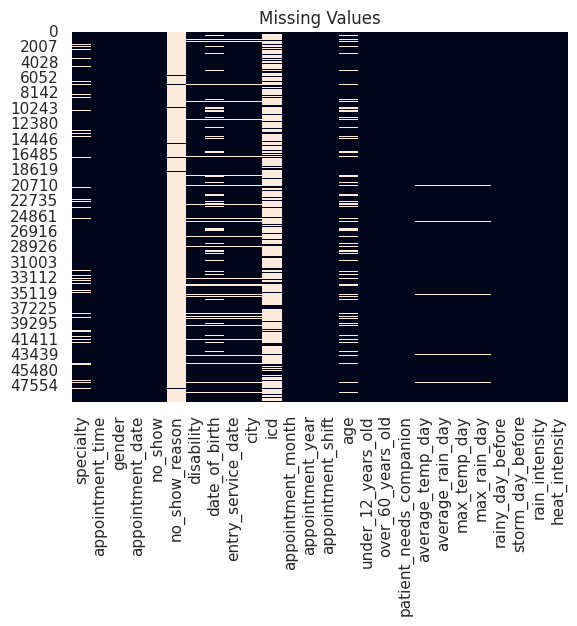

In [ ]:
# Visualize missing values
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

In [ ]:
# Specify columns to drop
columns_to_drop = ['no_show_reason', 'disability', 'icd', 'city']

# Filter out columns that exist in the dataset
columns_to_drop_existing = [col for col in columns_to_drop if col in df.columns]

# Drop the existing columns
df = df.drop(columns_to_drop_existing, axis=1)

# Print the updated DataFrame
print(df)

            specialty appointment_time gender appointment_date no_show  \
0       physiotherapy            13:20      M       09/09/2021     yes   
1       psychotherapy            13:20      M       09/09/2021      no   
2      speech therapy            13:20      F       09/09/2021      no   
3       physiotherapy            13:20      F       09/09/2021      no   
4       physiotherapy            14:00      M       09/09/2021      no   
...               ...              ...    ...              ...     ...   
49587   psychotherapy            10:20      M       01/02/2022      no   
49589             NaN            10:20      M       01/02/2022     yes   
49590             NaN            11:00      M       01/02/2022      no   
49591   psychotherapy            11:00      M       01/02/2022     yes   
49592             NaN            11:00      M       01/02/2022      no   

      date_of_birth entry_service_date appointment_month  appointment_year  \
0               NaN              

# **HANDLING MISSING VALUE IN SPECIALITIES**

In [ ]:
import pandas as pd

# Define important specialties and default specialty
important_specialties = ['physiotherapy', 'occupational therapy', 'speech therapy', 'assist','enf' ,'pedagogo' ]

default_specialty = 'General Medicine'  # Choose a default specialty for cases where patient_needs_companion is 0

# Replace missing values in 'specialty' based on the value of 'patient_needs_companion'
df['specialty'] = df.apply(lambda row: important_specialties[0] if row['patient_needs_companion'] == 1 and pd.isna(row['specialty']) else default_specialty if row['patient_needs_companion'] == 0 and pd.isna(row['specialty']) else row['specialty'], axis=1)

# Check if there are any missing values left in the 'specialty' column
print("Missing values in 'specialty' after handling:")
print(df['specialty'].isna().sum())


Missing values in 'specialty' after handling:
0


In [ ]:
df.loc[:, ['date_of_birth', 'age']]

,date_of_birth,age
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,10/10/1954,68.0
...,...,...
49587,7/3/2016,6.0
49589,NaN,NaN
49590,7/3/2016,6.0
49591,NaN,NaN


In [ ]:
df['date_of_birth'].head(10)

0           NaN
1           NaN
2           NaN
3           NaN
4    10/10/1954
5     21/3/2017
6     10/1/2011
7           NaN
8     21/3/2017
9           NaN
Name: date_of_birth, dtype: object

HANDLING MISSING VALUE IN AGE

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Create a new column 'age_category'
def get_age_category(row):
    if row['under_12_years_old'] == 0 and row['over_60_years_old'] == 0:
        return 'Between'
    else:
        return 'Not between'

df['age_category'] = df.apply(get_age_category, axis=1)

# Encode 'age_category', 'under_12_years_old', and 'over_60_years_old' into a single column
encoder = LabelEncoder()

# Encode age_category column
df['age_category_encoded'] = encoder.fit_transform(df['age_category'])

# Encode under_12_years_old column
df['under_12_years_old_encoded'] = encoder.fit_transform(df['under_12_years_old'])

# Encode over_60_years_old column
df['over_60_years_old_encoded'] = encoder.fit_transform(df['over_60_years_old'])

# Combine encoded columns into a single column
df['age_group'] = df['under_12_years_old_encoded'] + df['over_60_years_old_encoded'] + df['age_category_encoded']

# Drop redundant columns
df.drop(['under_12_years_old', 'over_60_years_old', 'age_category', 'age_category_encoded', 'under_12_years_old_encoded', 'over_60_years_old_encoded'], axis=1, inplace=True)




In [ ]:
df

,specialty,appointment_time,gender,appointment_date,no_show,date_of_birth,entry_service_date,appointment_month,appointment_year,appointment_shift,...,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,age_group
0,physiotherapy,13:20,M,09/09/2021,yes,NaN,NaN,sept,2021,afternoon,...,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild,0
1,psychotherapy,13:20,M,09/09/2021,no,NaN,NaN,sept,2021,afternoon,...,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild,0
2,speech therapy,13:20,F,09/09/2021,no,NaN,NaN,sept,2021,afternoon,...,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild,0
3,physiotherapy,13:20,F,09/09/2021,no,NaN,NaN,sept,2021,afternoon,...,0,20.75,0.01,23.7,0.2,1,1,no_rain,mild,0
4,physiotherapy,14:00,M,09/09/2021,no,10/10/1954,5/2/2020,sept,2021,afternoon,...,1,20.75,0.01,23.7,0.2,1,1,no_rain,mild,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49587,psychotherapy,10:20,M,01/02/2022,no,7/3/2016,11/2/2020,feb,2022,morning,...,1,NaN,NaN,NaN,NaN,0,0,no_rain,heavy_cold,2
49589,General Medicine,10:20,M,01/02/2022,yes,NaN,NaN,feb,2022,morning,...,0,NaN,NaN,NaN,NaN,0,0,no_rain,heavy_cold,0
49590,physiotherapy,11:00,M,01/02/2022,no,7/3/2016,11/2/2020,feb,2022,morning,...,1,NaN,NaN,NaN,NaN,0,0,no_rain,heavy_cold,2
49591,psychotherapy,11:00,M,01/02/2022,yes,NaN,NaN,feb,2022,morning,...,0,NaN,NaN,NaN,NaN,0,0,no_rain,heavy_cold,0


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression



# Split the dataset into two sets: one with non-missing 'age' values and one with missing 'age' values (NaNs)
df_age_present = df.dropna(subset=['age'])
df_age_missing = df[df['age'].isna()]

# Create feature matrix (X) and target vector (y) for the training set
X_train = df_age_present[['age_group']]  # Feature: age_category
y_train = df_age_present['age']             # Target: age

# Create feature matrix (X) for the set with missing 'age' values
X_test = df_age_missing[['age_group']]

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the missing 'age' values
predicted_age = model.predict(X_test)

# Fill the missing 'age' values in the original dataset with the predicted values
df.loc[df['age'].isna(), 'age'] = predicted_age



In [ ]:
import pandas as pd
# Drop the 'date_of_birth' column
df.drop(columns=['date_of_birth'], inplace=True)


In [ ]:
df['age'].isna().sum() / len(df)

0.0

In [ ]:
df['age'].unique()

array([ 22.75615288,  68.        ,   5.        ,  11.        ,
        28.        ,   9.        ,  25.        ,   7.        ,
        51.        ,  15.        ,  52.        ,  79.        ,
        56.        ,   3.        ,   8.        ,   6.        ,
        42.        ,  14.        ,  10.        ,  63.        ,
        23.        ,  48.        ,   4.        ,  39.        ,
        62.        ,  13.        ,  69.        ,  60.        ,
        78.        ,  12.        ,  49.        ,  50.        ,
        73.        ,  55.        ,  27.        ,  17.        ,
        61.        ,  19.        ,  30.        ,  58.        ,
        80.        ,  33.        ,  70.        ,  16.        ,
        29.        ,  31.        ,  65.        ,  87.        ,
        64.        ,  21.        ,  59.        ,  77.        ,
        38.        ,  22.        ,  46.        ,  67.        ,
        54.        ,  44.        ,  26.        ,  83.        ,
        72.        ,  81.        ,  74.        ,  32.  

In [ ]:
df['age'].isna().sum()

0

In [ ]:
df['age'].head()

0    22.756153
1    22.756153
2    22.756153
3    22.756153
4    68.000000
Name: age, dtype: float64

In [ ]:
df['age'].value_counts()

22.756153    8704
9.000000     4231
8.000000     3959
7.000000     3512
10.000000    3185
             ... 
86.000000      14
24.000000      14
76.000000      12
36.000000      10
34.000000       1
Name: age, Length: 88, dtype: int64

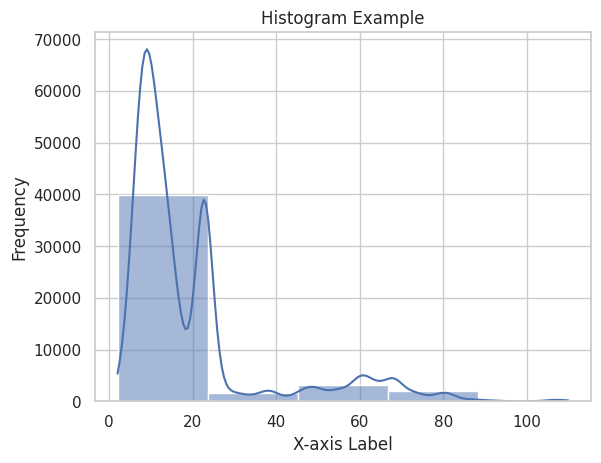

In [ ]:
# Create a histogram using Seaborn
sns.histplot(df['age'], bins=5, kde=True)  # You can adjust the number of bins as needed

# Adding labels and title
plt.xlabel("X-axis Label")
plt.ylabel("Frequency")
plt.title("Histogram Example")

# Display the plot
plt.show()

# ***Extracting date from Scheduled Day***

In [ ]:
import pandas as pd


# Convert the "entry_service_date" column to datetime format
df['entry_service_date'] = pd.to_datetime(df['entry_service_date'], errors='coerce')

# Calculate the default date (e.g., earliest date in the dataset)
default_date = df['entry_service_date'].min()

# Replace missing values with the default date
df['entry_service_date'].fillna(default_date, inplace=True)


<ipython-input-1290-73e48490cff7>:5: UserWarning: Parsing dates in DD/MM/YYYY format when dayfirst=False (the default) was specified. This may lead to inconsistently parsed dates! Specify a format to ensure consistent parsing.
  df['entry_service_date'] = pd.to_datetime(df['entry_service_date'], errors='coerce')


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# Handle missing values using forward fill
df.fillna(method='ffill', inplace=True)

# Feature Engineering
df['appointment_date'] = pd.to_datetime(df['appointment_date'])
df['entry_service_date'] = pd.to_datetime(df['entry_service_date'])
df['days_between'] = (df['appointment_date'] - df['entry_service_date']).dt.days
# Add new column for scheduling date
df['scheduling_date'] = df['appointment_date'] - pd.to_timedelta(df['days_between'], unit='d')

# Encode categorical variables
label_encoder = LabelEncoder()
df['appointment_month'] = label_encoder.fit_transform(df['appointment_month'])
df['rain_intensity'] = label_encoder.fit_transform(df['rain_intensity'])

# Select features and target variable
X = df[[ 'days_between', 'rain_intensity']]
y = df['no_show']

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)




<ipython-input-1291-72ae5be360e0>:11: UserWarning: Parsing dates in DD/MM/YYYY format when dayfirst=False (the default) was specified. This may lead to inconsistently parsed dates! Specify a format to ensure consistent parsing.
  df['appointment_date'] = pd.to_datetime(df['appointment_date'])


In [ ]:
df

,specialty,appointment_time,gender,appointment_date,no_show,entry_service_date,appointment_month,appointment_year,appointment_shift,age,...,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,age_group,days_between,scheduling_date
0,physiotherapy,13:20,M,2021-09-09,yes,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
1,psychotherapy,13:20,M,2021-09-09,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
2,speech therapy,13:20,F,2021-09-09,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
3,physiotherapy,13:20,F,2021-09-09,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
4,physiotherapy,14:00,M,2021-09-09,no,2020-05-02,11,2021,afternoon,68.000000,...,0.01,23.7,0.2,1,1,2,mild,2,495,2020-05-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49587,psychotherapy,10:20,M,2022-01-02,no,2020-11-02,3,2022,morning,6.000000,...,4.22,24.6,32.8,0,0,2,heavy_cold,2,426,2020-11-02
49589,General Medicine,10:20,M,2022-01-02,yes,2014-01-12,3,2022,morning,22.756153,...,4.22,24.6,32.8,0,0,2,heavy_cold,0,2912,2014-01-12
49590,physiotherapy,11:00,M,2022-01-02,no,2020-11-02,3,2022,morning,6.000000,...,4.22,24.6,32.8,0,0,2,heavy_cold,2,426,2020-11-02
49591,psychotherapy,11:00,M,2022-01-02,yes,2014-01-12,3,2022,morning,22.756153,...,4.22,24.6,32.8,0,0,2,heavy_cold,0,2912,2014-01-12


In [ ]:
len(df[df["appointment_date"] < df["scheduling_date"]])


3907

'AppointmentDay' has no value for time of the day and it has many values(38568) smaller than 'ScheduledDay' which is not possible !
The reason for this problem is that probably these appointments happened at the same day that they're booked but because we don't have the exact hour for 'AppointmentDay' their difference is negative.
To solve this problem, we added 23 hrs and 59 min and 59 secs to the 'AppointmentDay'. Now all 'AppointmentDay' are still at the same the same day

In [ ]:
df['appointment_date'] = df['scheduling_date'] + pd.Timedelta('1d') - pd.Timedelta('1s')
df.head()

,specialty,appointment_time,gender,appointment_date,no_show,entry_service_date,appointment_month,appointment_year,appointment_shift,age,...,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,age_group,days_between,scheduling_date
0,physiotherapy,13:20,M,2014-01-12 23:59:59,yes,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
1,psychotherapy,13:20,M,2014-01-12 23:59:59,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
2,speech therapy,13:20,F,2014-01-12 23:59:59,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
3,physiotherapy,13:20,F,2014-01-12 23:59:59,no,2014-01-12,11,2021,afternoon,22.756153,...,0.01,23.7,0.2,1,1,2,mild,0,2797,2014-01-12
4,physiotherapy,14:00,M,2020-05-02 23:59:59,no,2020-05-02,11,2021,afternoon,68.000000,...,0.01,23.7,0.2,1,1,2,mild,2,495,2020-05-02


In [ ]:
len(df[df["appointment_date"] < df["scheduling_date"]])


0

In [ ]:
def parse_date(date):
    if date == '':
        return None
    else:
        return (dt.strptime(date, "%Y-%m-%dT%H:%M:%S%fz"))

def parse_maybe_int(i):
    if i == '':
        return None
    else:
        return int(i)

def get_hour(date):
    if date == '':
        return None
    else:
        return parse_maybe_int(str(parse_date(date)).split(' ')[1].split(':')[0])

def get_day(date):
    if date == '':
        return None
    else:
        return parse_date(date).strftime('%A')

def get_month(date):
    if date == '':
        return None
    else:
        return parse_maybe_int(str(parse_date(date)).split('-')[1])

def get_year(date):
    if date == '':
        return None
    else:
        return parse_maybe_int(str(parse_date(date)).split('-')[0])

In [ ]:
# Extract hour from the 'HH:MM' format
df['scheduledhour'] = pd.to_datetime(df['appointment_time'], format='%H:%M').dt.hour

# Assuming 'appointment_date' is in the format '31/08/2021'
df['scheduleddayofweek'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.day_name()
df['scheduledmonth'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.month
df['scheduledyear'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.year

# Assuming 'appointment_date' is in the format '31/08/2021'
df['appointmentdayofweek'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.day_name()
df['appointmentmonth'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.month
df['appointmentyear'] = pd.to_datetime(df['appointment_date'], format='%d/%m/%Y').dt.year

In [ ]:
df.drop(['appointment_month','appointment_time'], axis=1, inplace=True)

In [ ]:
df

,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,age_group,days_between,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear
0,physiotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
1,psychotherapy,M,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
2,speech therapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
3,physiotherapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
4,physiotherapy,M,2020-05-02 23:59:59,no,2020-05-02,2021,afternoon,68.000000,1,20.75,...,2,495,2020-05-02,14,Saturday,5,2020,Saturday,5,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49587,psychotherapy,M,2020-11-02 23:59:59,no,2020-11-02,2022,morning,6.000000,1,22.55,...,2,426,2020-11-02,10,Monday,11,2020,Monday,11,2020
49589,General Medicine,M,2014-01-12 23:59:59,yes,2014-01-12,2022,morning,22.756153,0,22.55,...,0,2912,2014-01-12,10,Sunday,1,2014,Sunday,1,2014
49590,physiotherapy,M,2020-11-02 23:59:59,no,2020-11-02,2022,morning,6.000000,1,22.55,...,2,426,2020-11-02,11,Monday,11,2020,Monday,11,2020
49591,psychotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2022,morning,22.756153,0,22.55,...,0,2912,2014-01-12,11,Sunday,1,2014,Sunday,1,2014


In [ ]:
df.head()

,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,age_group,days_between,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear
0,physiotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
1,psychotherapy,M,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
2,speech therapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
3,physiotherapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,0,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014
4,physiotherapy,M,2020-05-02 23:59:59,no,2020-05-02,2021,afternoon,68.000000,1,20.75,...,2,495,2020-05-02,14,Saturday,5,2020,Saturday,5,2020


In [ ]:
df.isna().sum()

specialty                  0
gender                     0
appointment_date           0
no_show                    0
entry_service_date         0
appointment_year           0
appointment_shift          0
age                        0
patient_needs_companion    0
average_temp_day           0
average_rain_day           0
max_temp_day               0
max_rain_day               0
rainy_day_before           0
storm_day_before           0
rain_intensity             0
heat_intensity             0
age_group                  0
days_between               0
scheduling_date            0
scheduledhour              0
scheduleddayofweek         0
scheduledmonth             0
scheduledyear              0
appointmentdayofweek       0
appointmentmonth           0
appointmentyear            0
dtype: int64

# ***Adding "Lead days" column***

In [ ]:
df['LeadDays']=(df["appointment_date"] - df["scheduling_date"]).astype('timedelta64[D]').astype(int)


In [ ]:
df.head()


,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,days_between,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear,LeadDays
0,physiotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
1,psychotherapy,M,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
2,speech therapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
3,physiotherapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
4,physiotherapy,M,2020-05-02 23:59:59,no,2020-05-02,2021,afternoon,68.000000,1,20.75,...,495,2020-05-02,14,Saturday,5,2020,Saturday,5,2020,0


# ***We classify Lead Days into 6 categories
***

In [ ]:
def lead_day_category(LeadDay):
    if(LeadDay<=2):
        return 'Within 2 Days'
    elif(LeadDay>2 and LeadDay<=7):
        return 'Within 1 Week'
    elif(LeadDay>7 and LeadDay<=14):
        return 'Within 2 Weeks'
    elif(LeadDay>14 and LeadDay<=21):
        return 'Within 3 Weeks'
    elif(LeadDay>21 and LeadDay<=28):
        return 'Within 4 Weeks'
    elif(LeadDay>28):
        return 'After 1 Month'

In [ ]:
df

,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,days_between,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear,LeadDays
0,physiotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
1,psychotherapy,M,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
2,speech therapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
3,physiotherapy,F,2014-01-12 23:59:59,no,2014-01-12,2021,afternoon,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
4,physiotherapy,M,2020-05-02 23:59:59,no,2020-05-02,2021,afternoon,68.000000,1,20.75,...,495,2020-05-02,14,Saturday,5,2020,Saturday,5,2020,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49587,psychotherapy,M,2020-11-02 23:59:59,no,2020-11-02,2022,morning,6.000000,1,22.55,...,426,2020-11-02,10,Monday,11,2020,Monday,11,2020,0
49589,General Medicine,M,2014-01-12 23:59:59,yes,2014-01-12,2022,morning,22.756153,0,22.55,...,2912,2014-01-12,10,Sunday,1,2014,Sunday,1,2014,0
49590,physiotherapy,M,2020-11-02 23:59:59,no,2020-11-02,2022,morning,6.000000,1,22.55,...,426,2020-11-02,11,Monday,11,2020,Monday,11,2020,0
49591,psychotherapy,M,2014-01-12 23:59:59,yes,2014-01-12,2022,morning,22.756153,0,22.55,...,2912,2014-01-12,11,Sunday,1,2014,Sunday,1,2014,0


In [ ]:
# Handle missing values for categorical columns
categorical_cols = [ 'rain_intensity', 'heat_intensity', 'gender','entry_service_date']
df[categorical_cols] = df[categorical_cols].fillna('Unknown')

# Handle missing values for numeric columns
numeric_cols = [ 'average_temp_day', 'average_rain_day', 'max_temp_day', 'max_rain_day',
                'rainy_day_before', 'storm_day_before']
imputer = SimpleImputer(strategy='mean')
df[numeric_cols] = imputer.fit_transform(df[numeric_cols])
# Drop the letter 'i' from the values in the 'gender' column
###################################################################################################
df['gender'] = df['gender'].str.replace('I', 'F')






# ***Converting Categorical values to Numeric values
***

In [ ]:
# Map 'yes' to 1 and 'no' to 0 in the 'no_show' column
df['no_show'] = df['no_show'].map({'yes': 1, 'no': 0})
# Replace 'yes' with 1 and 'no' with 0 in the 'no_show' column
df['no_show'] = df['no_show'].replace({'yes': 1, 'no': 0})

In [ ]:
df['gender'] = df['gender'].map({'M': 0, 'F': 1})
df['appointment_shift'] = df['appointment_shift'].map({'morning': 0, 'afternoon': 1, 'evening': 2})

In [ ]:
df.head()

,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,days_between,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear,LeadDays
0,physiotherapy,0,2014-01-12 23:59:59,1,2014-01-12,2021,1,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
1,psychotherapy,0,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
2,speech therapy,1,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
3,physiotherapy,1,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2797,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0
4,physiotherapy,0,2020-05-02 23:59:59,0,2020-05-02,2021,1,68.000000,1,20.75,...,495,2020-05-02,14,Saturday,5,2020,Saturday,5,2020,0


In [ ]:
df.isnull().sum().any()

False

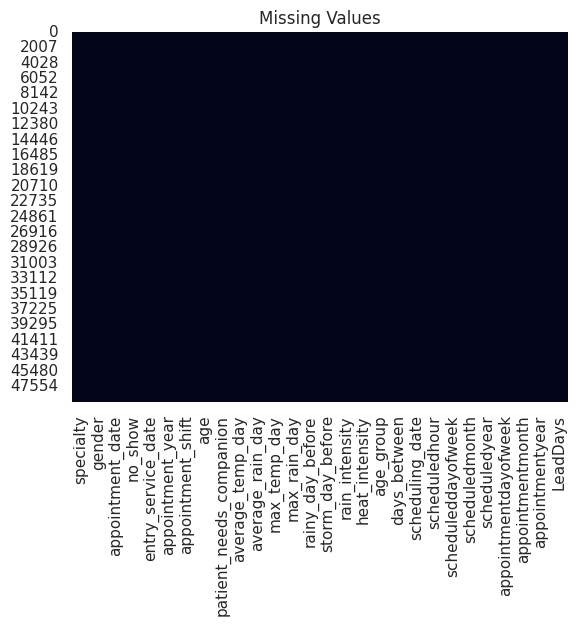

In [ ]:
# Visualize missing values
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

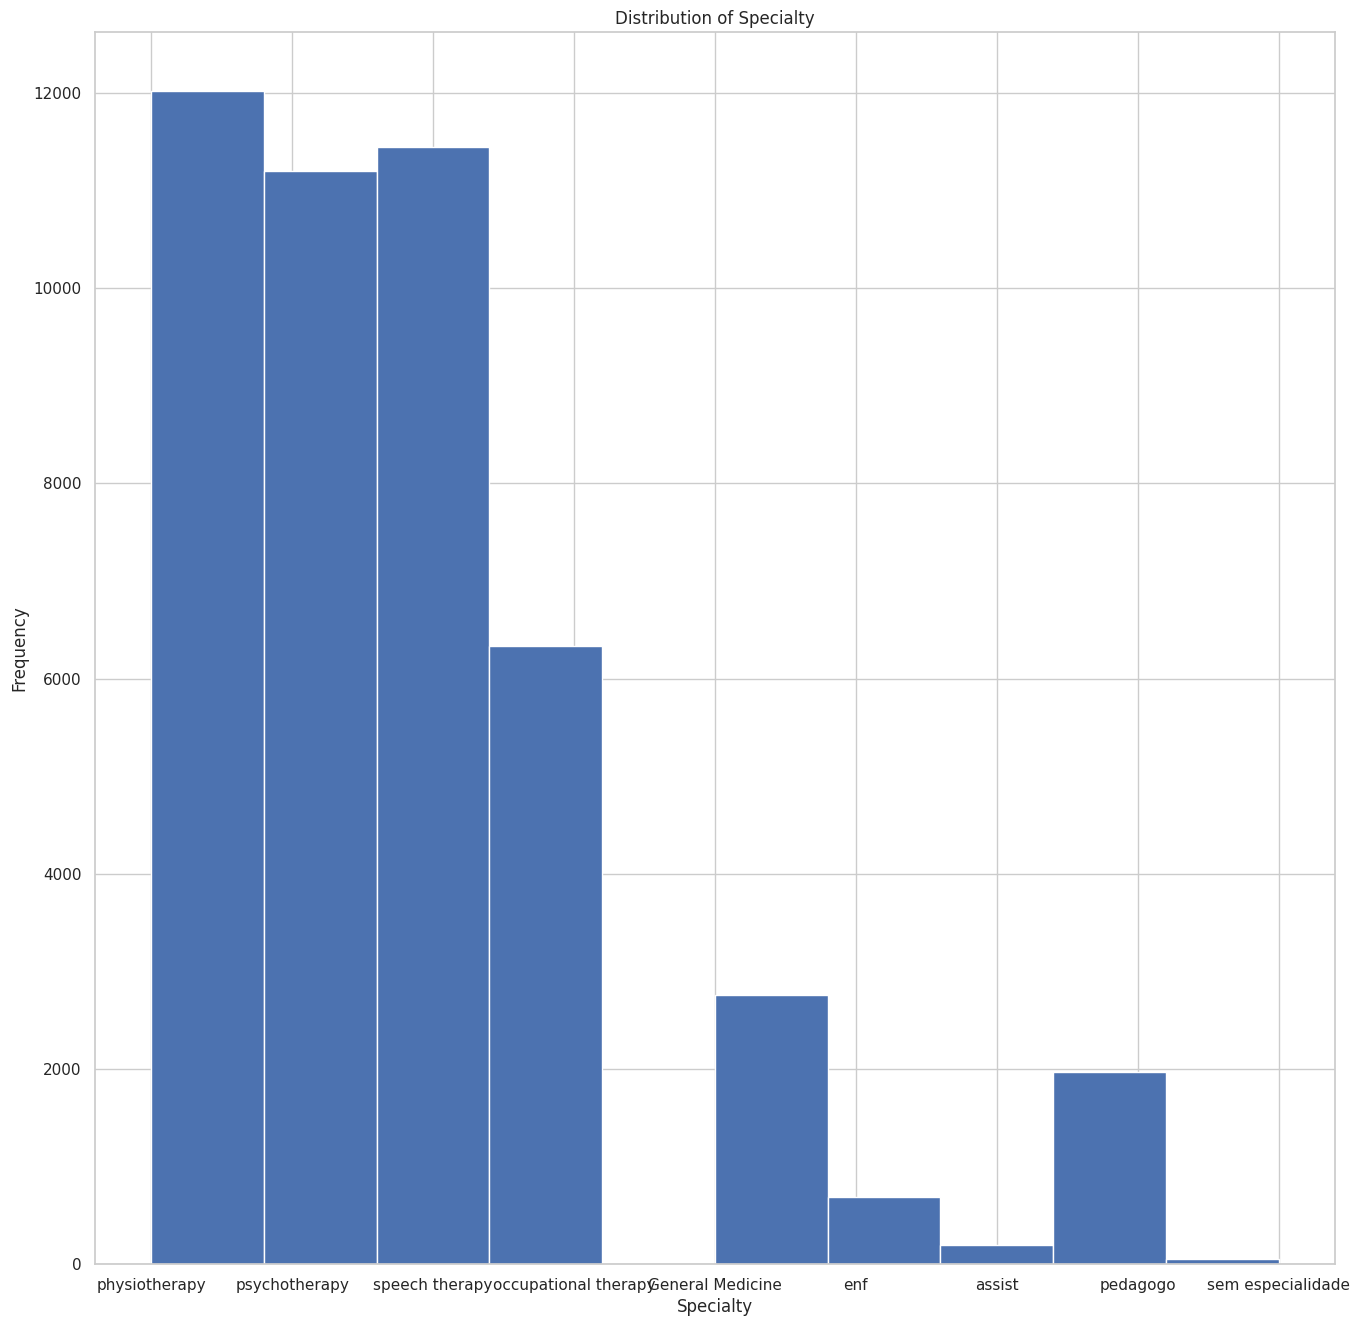

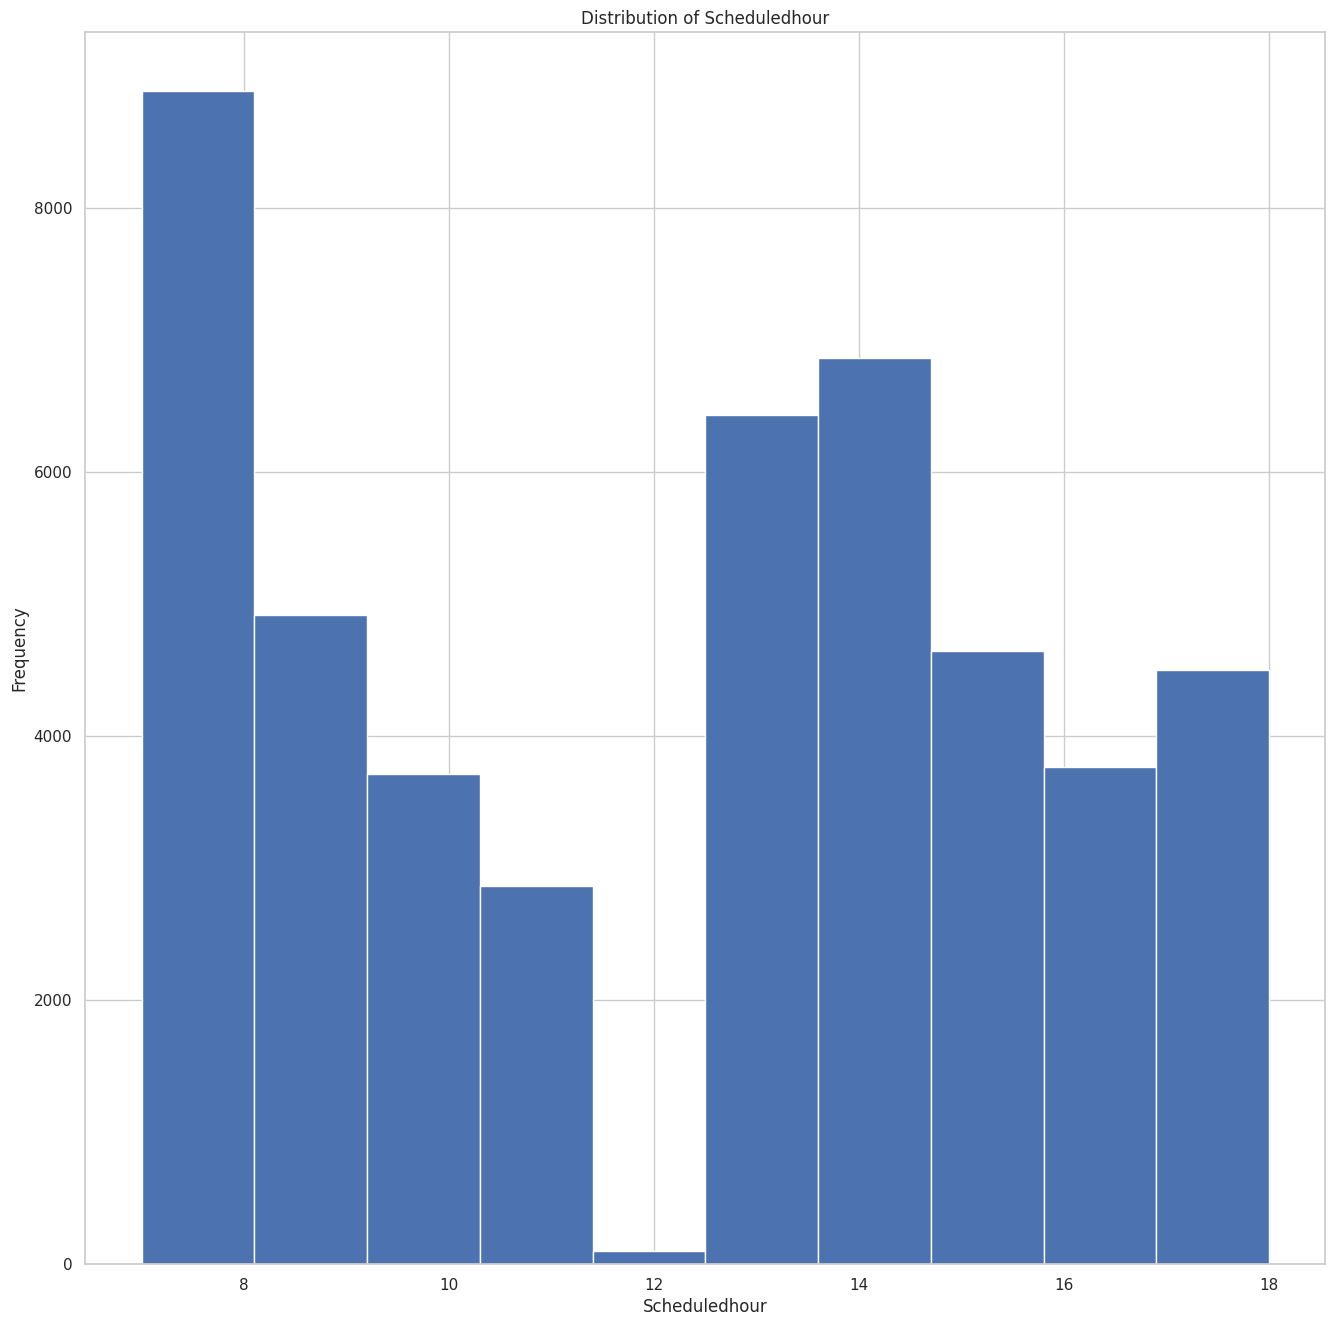

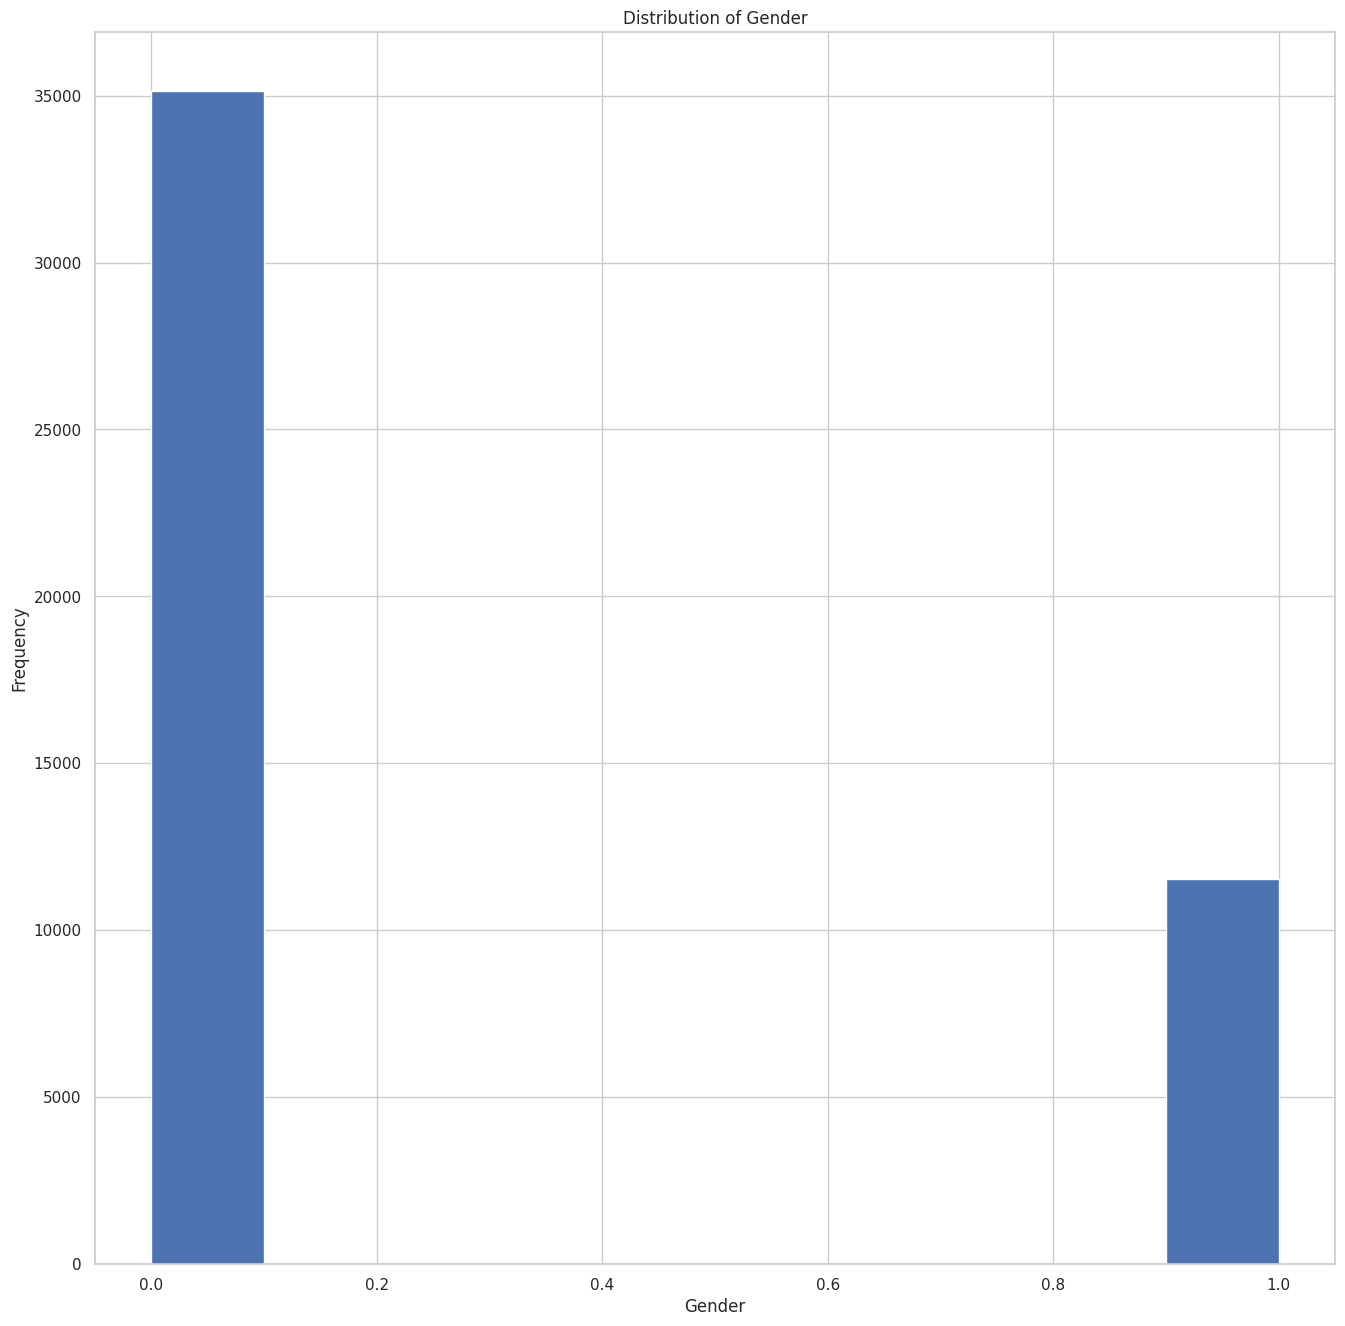

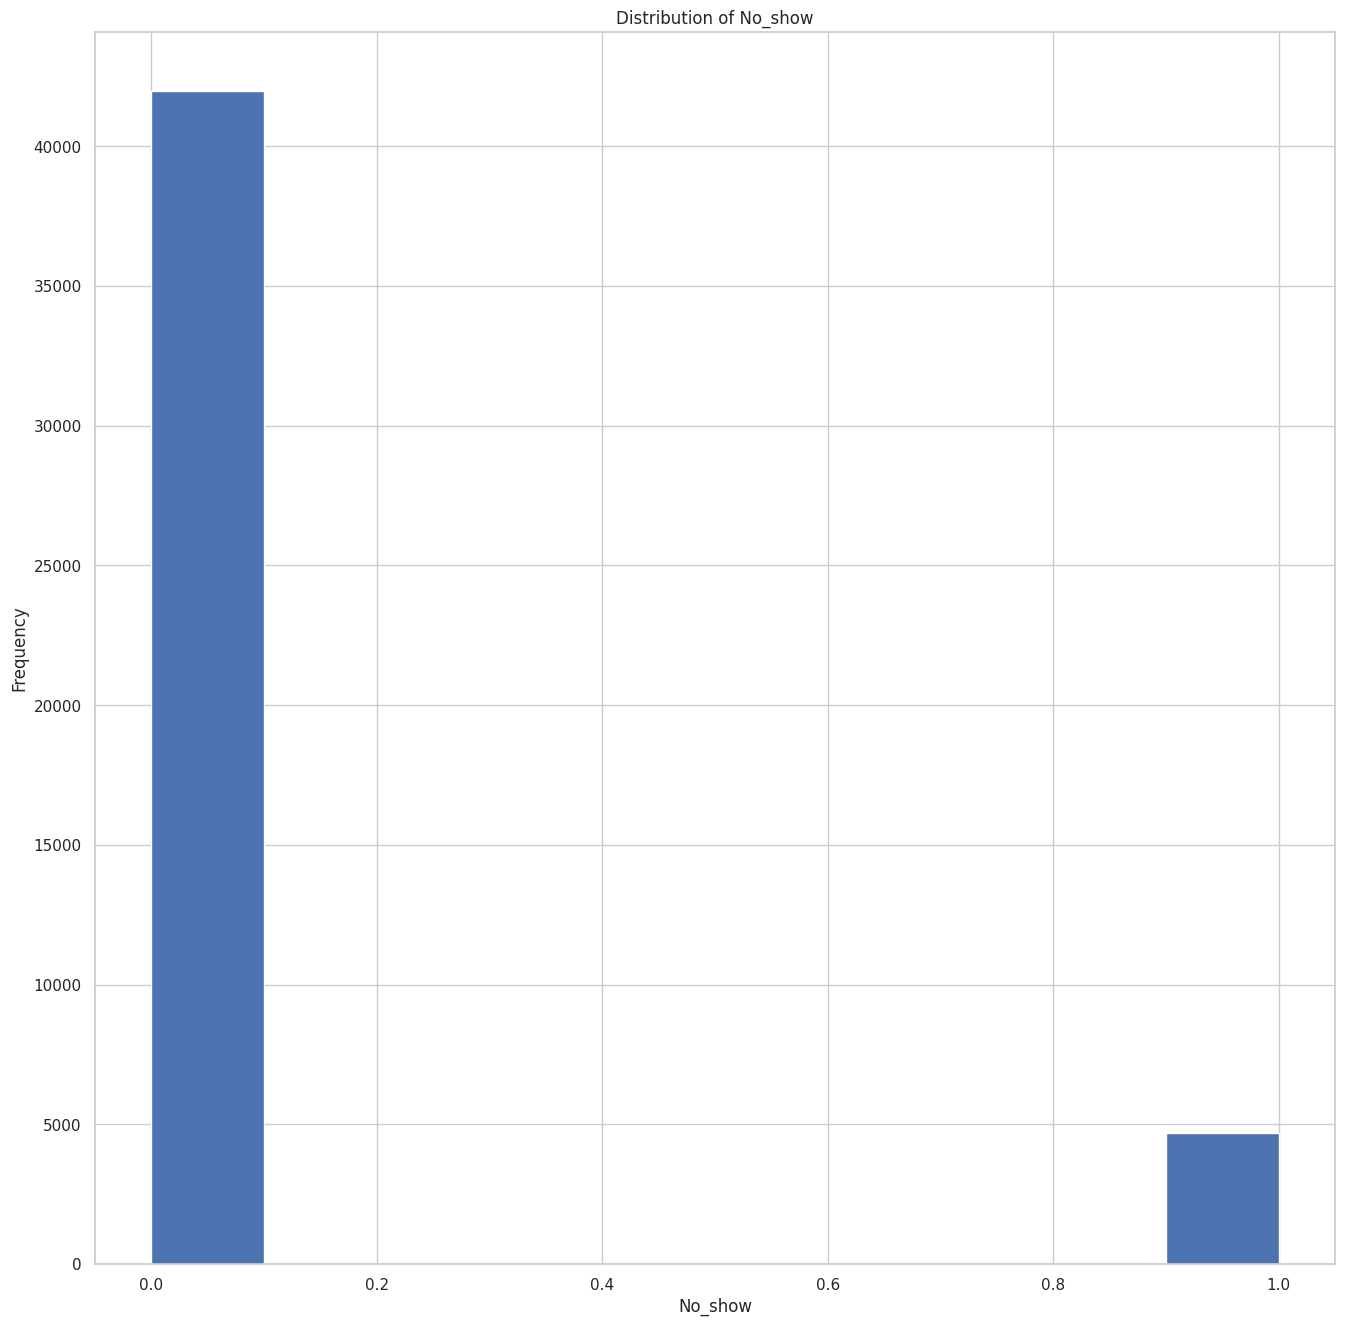

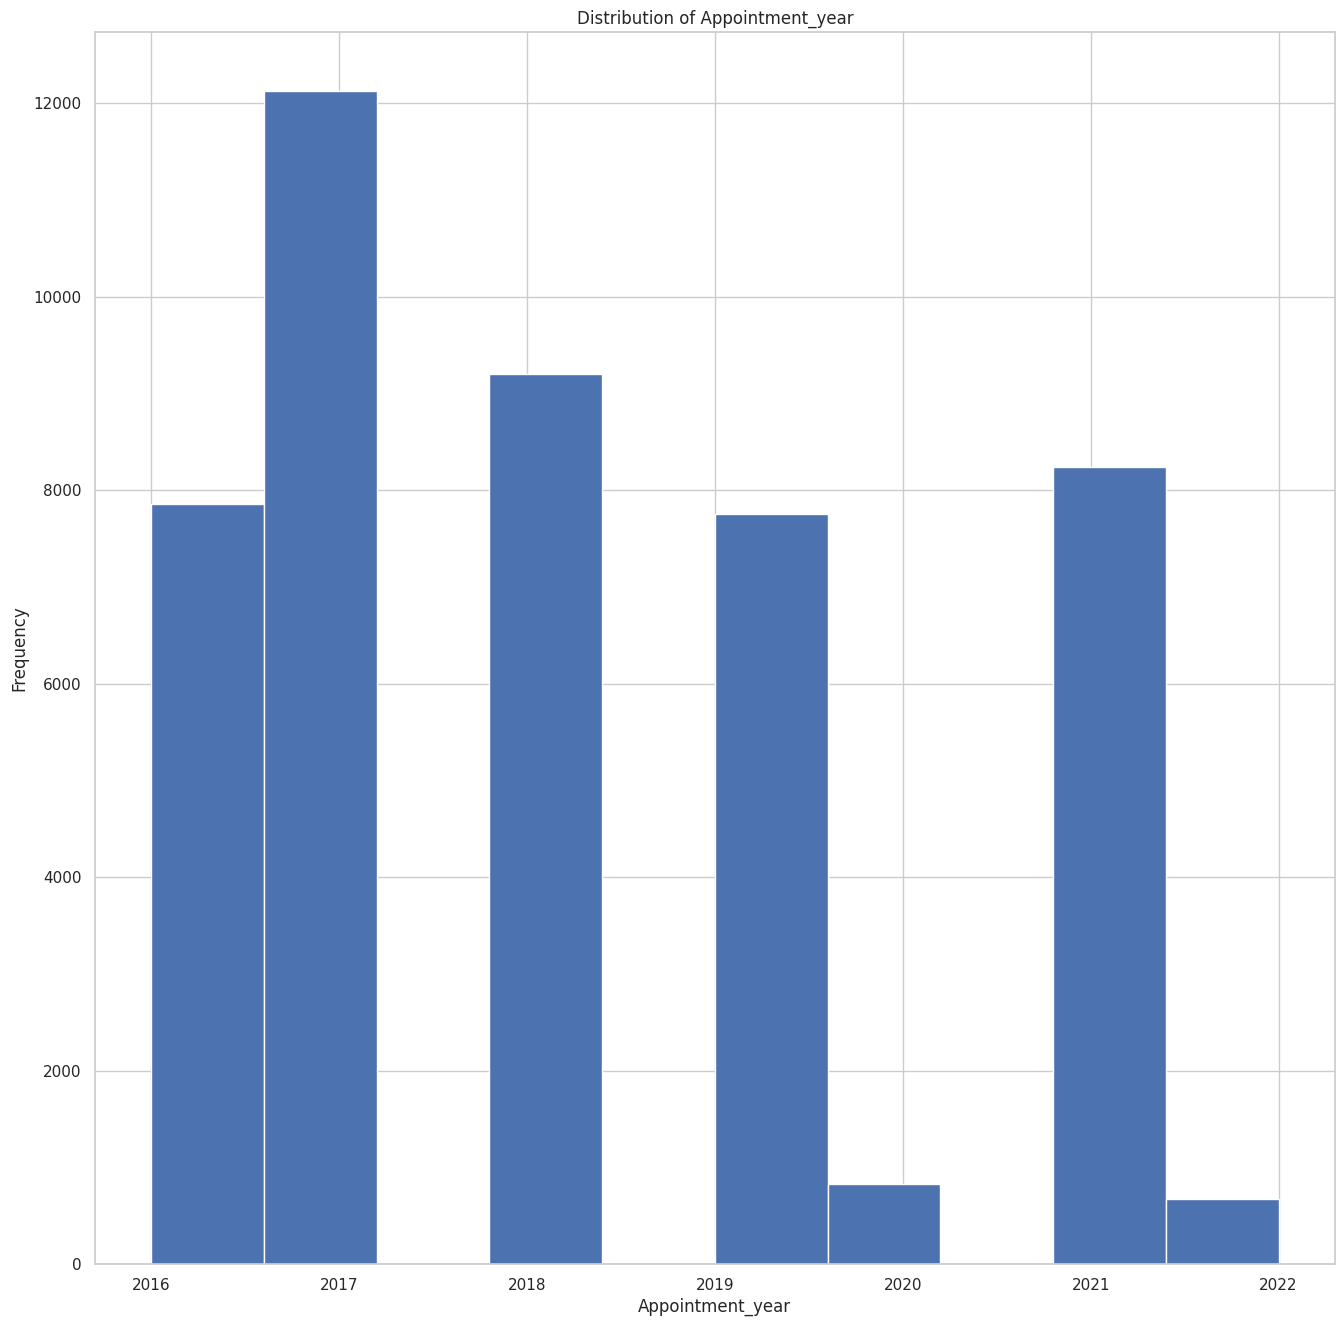

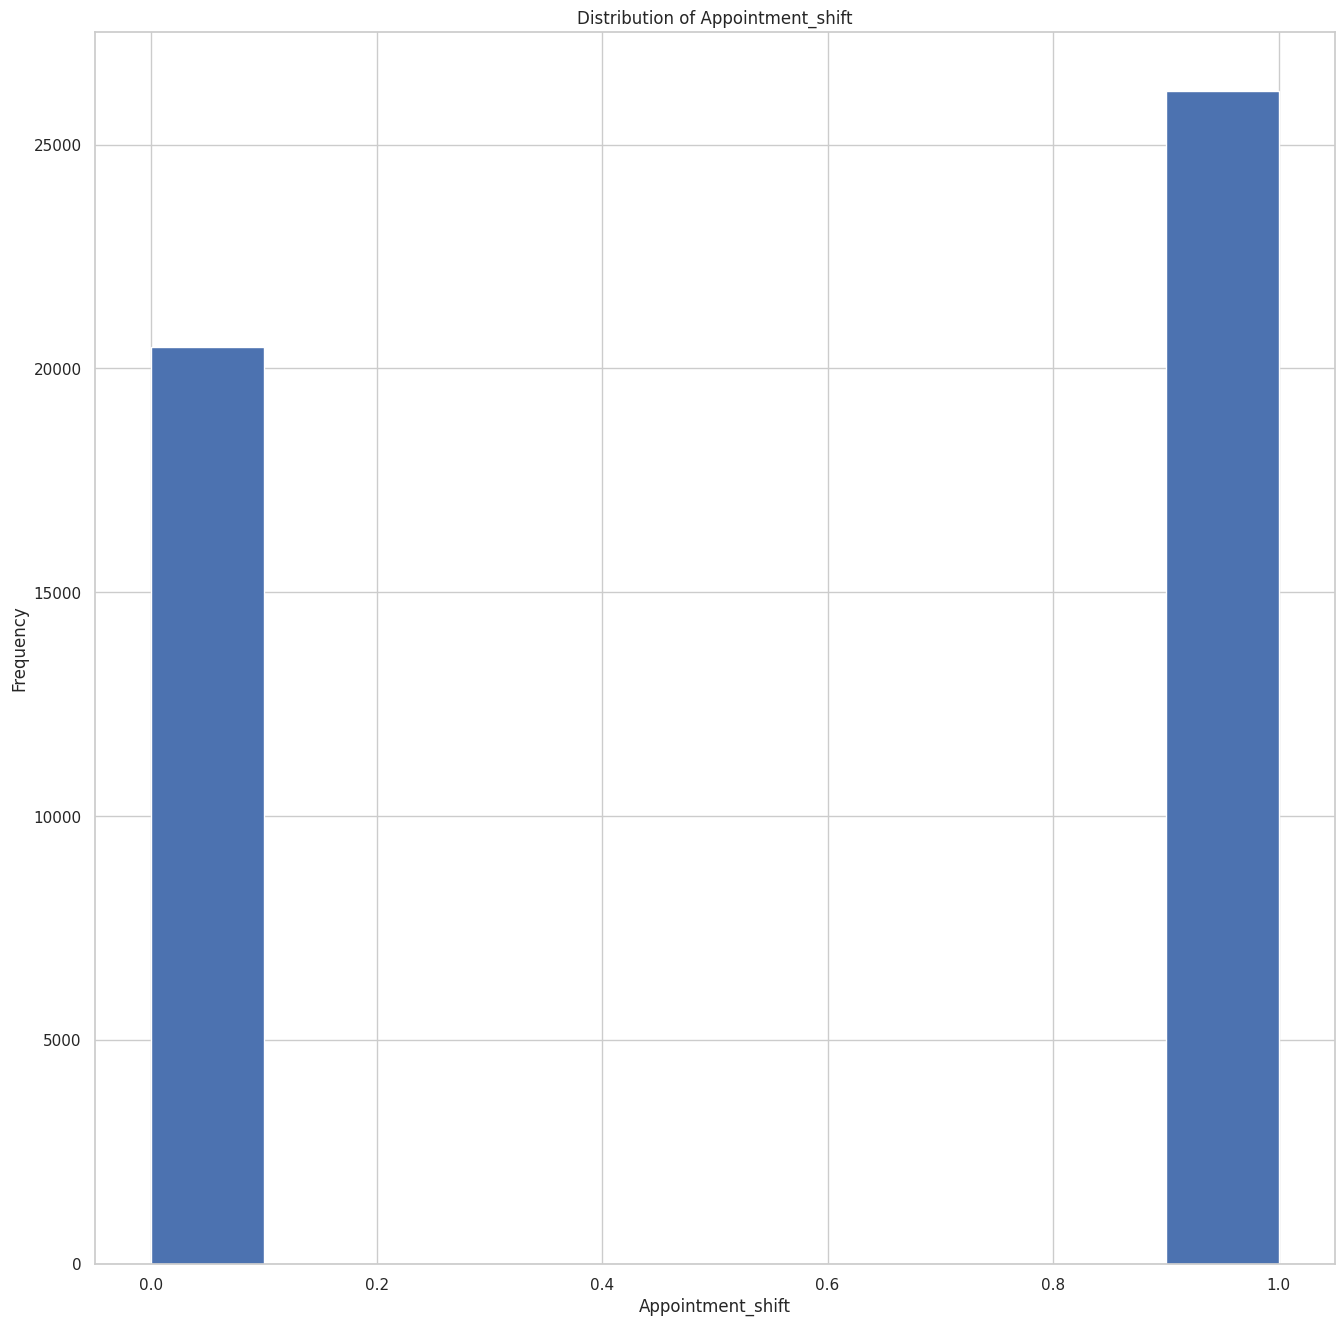

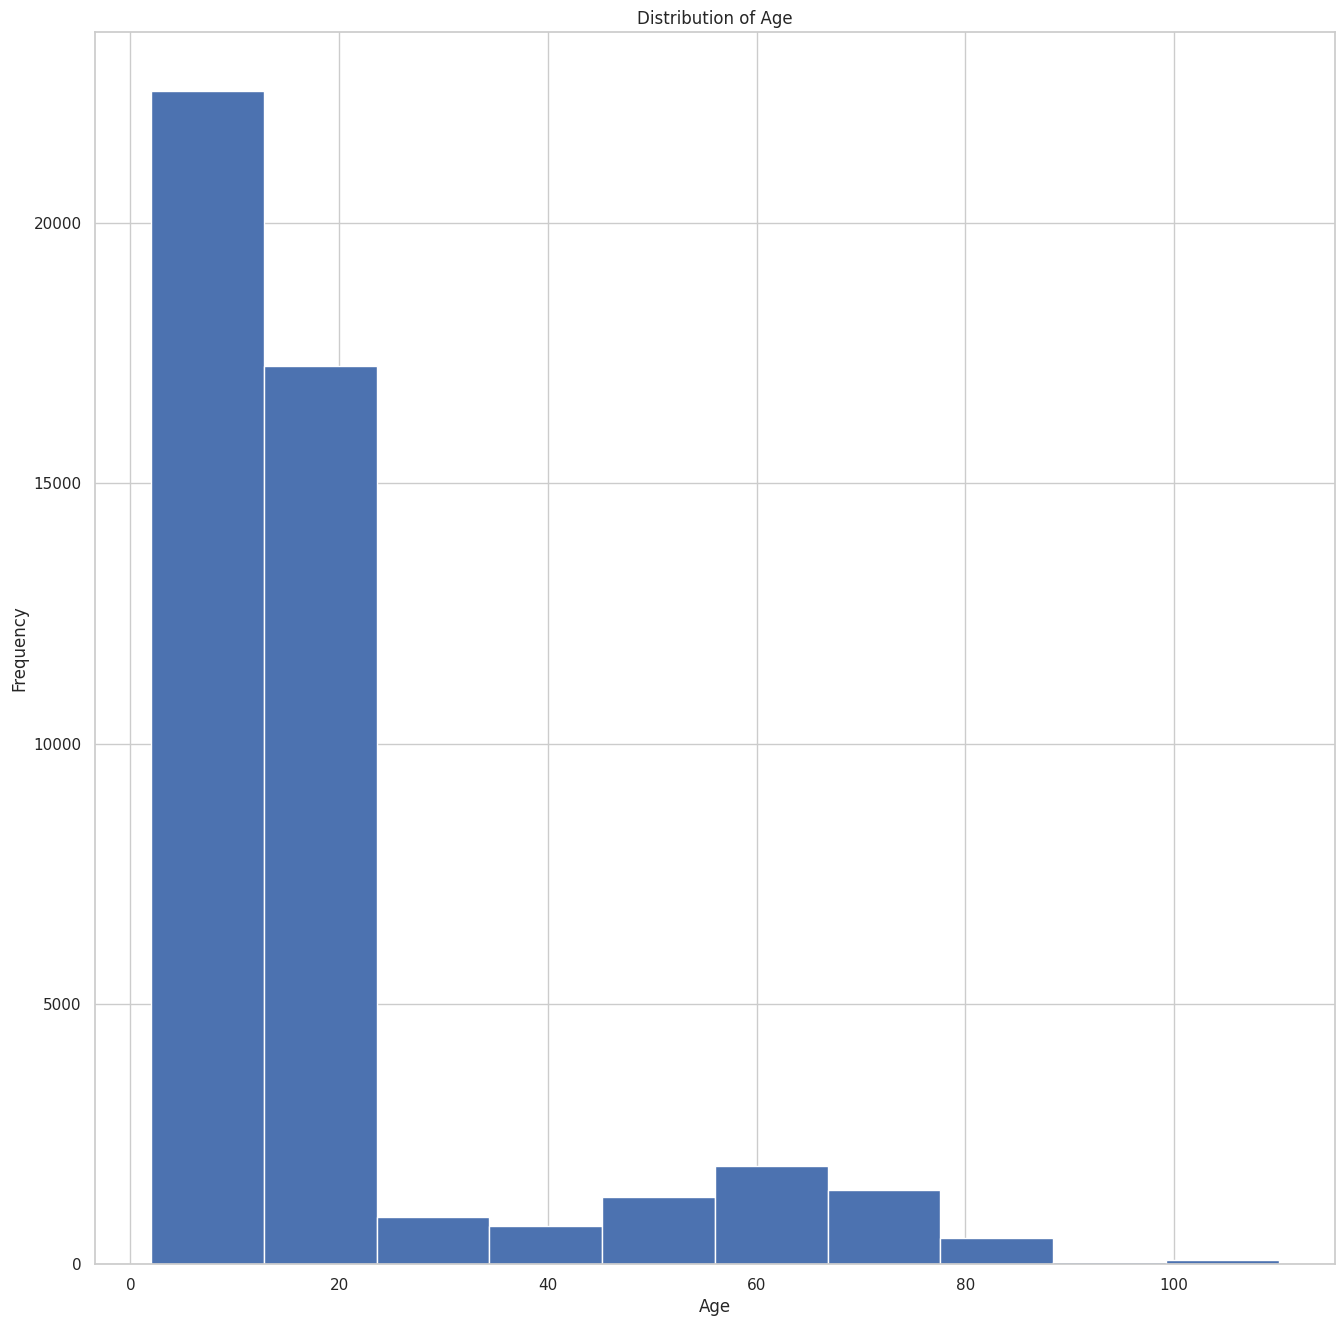

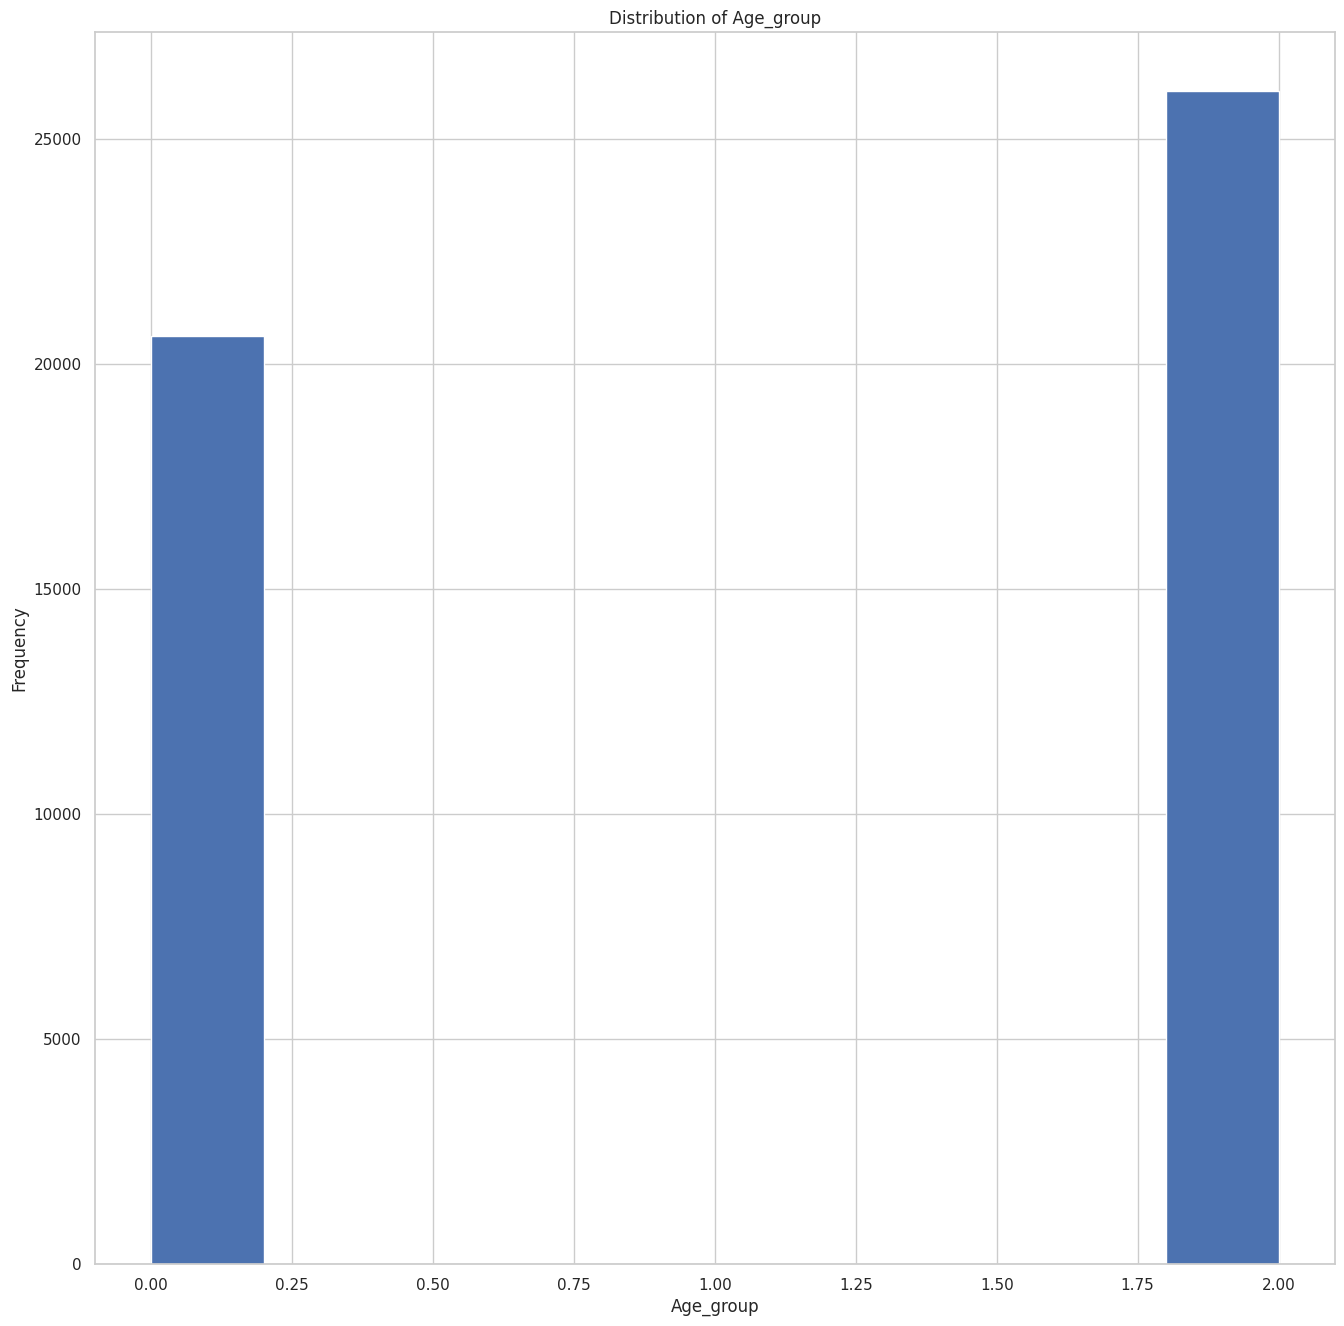

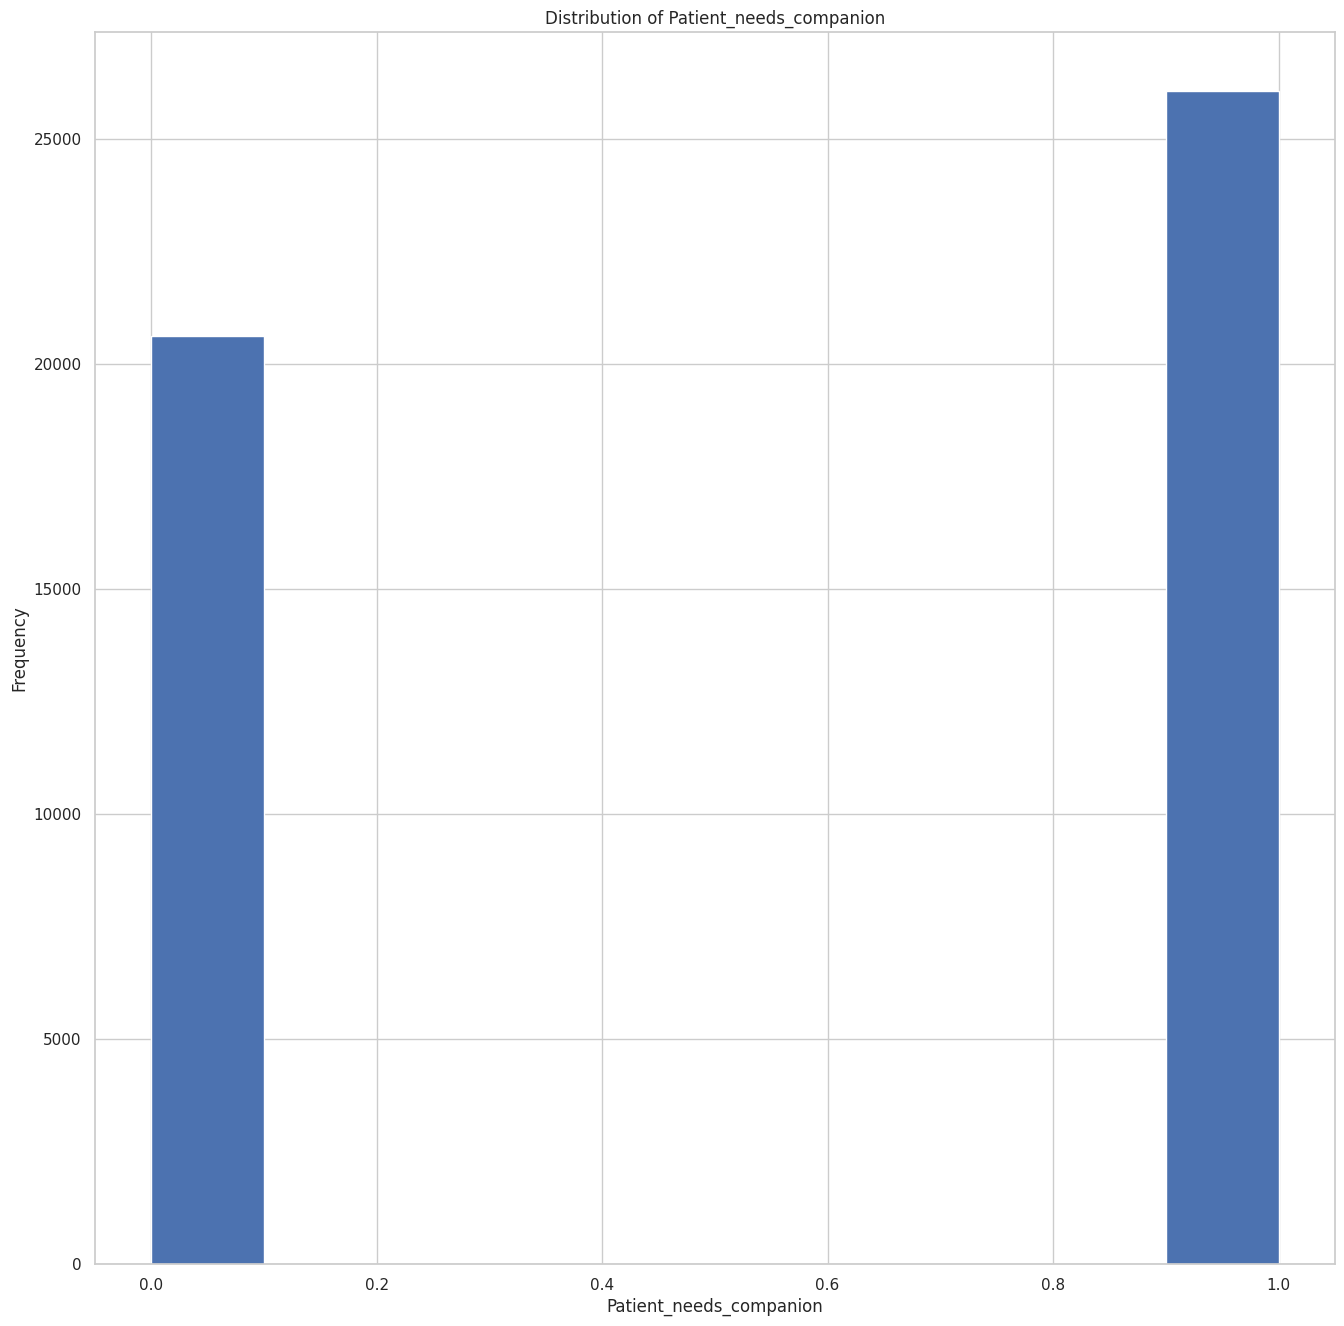

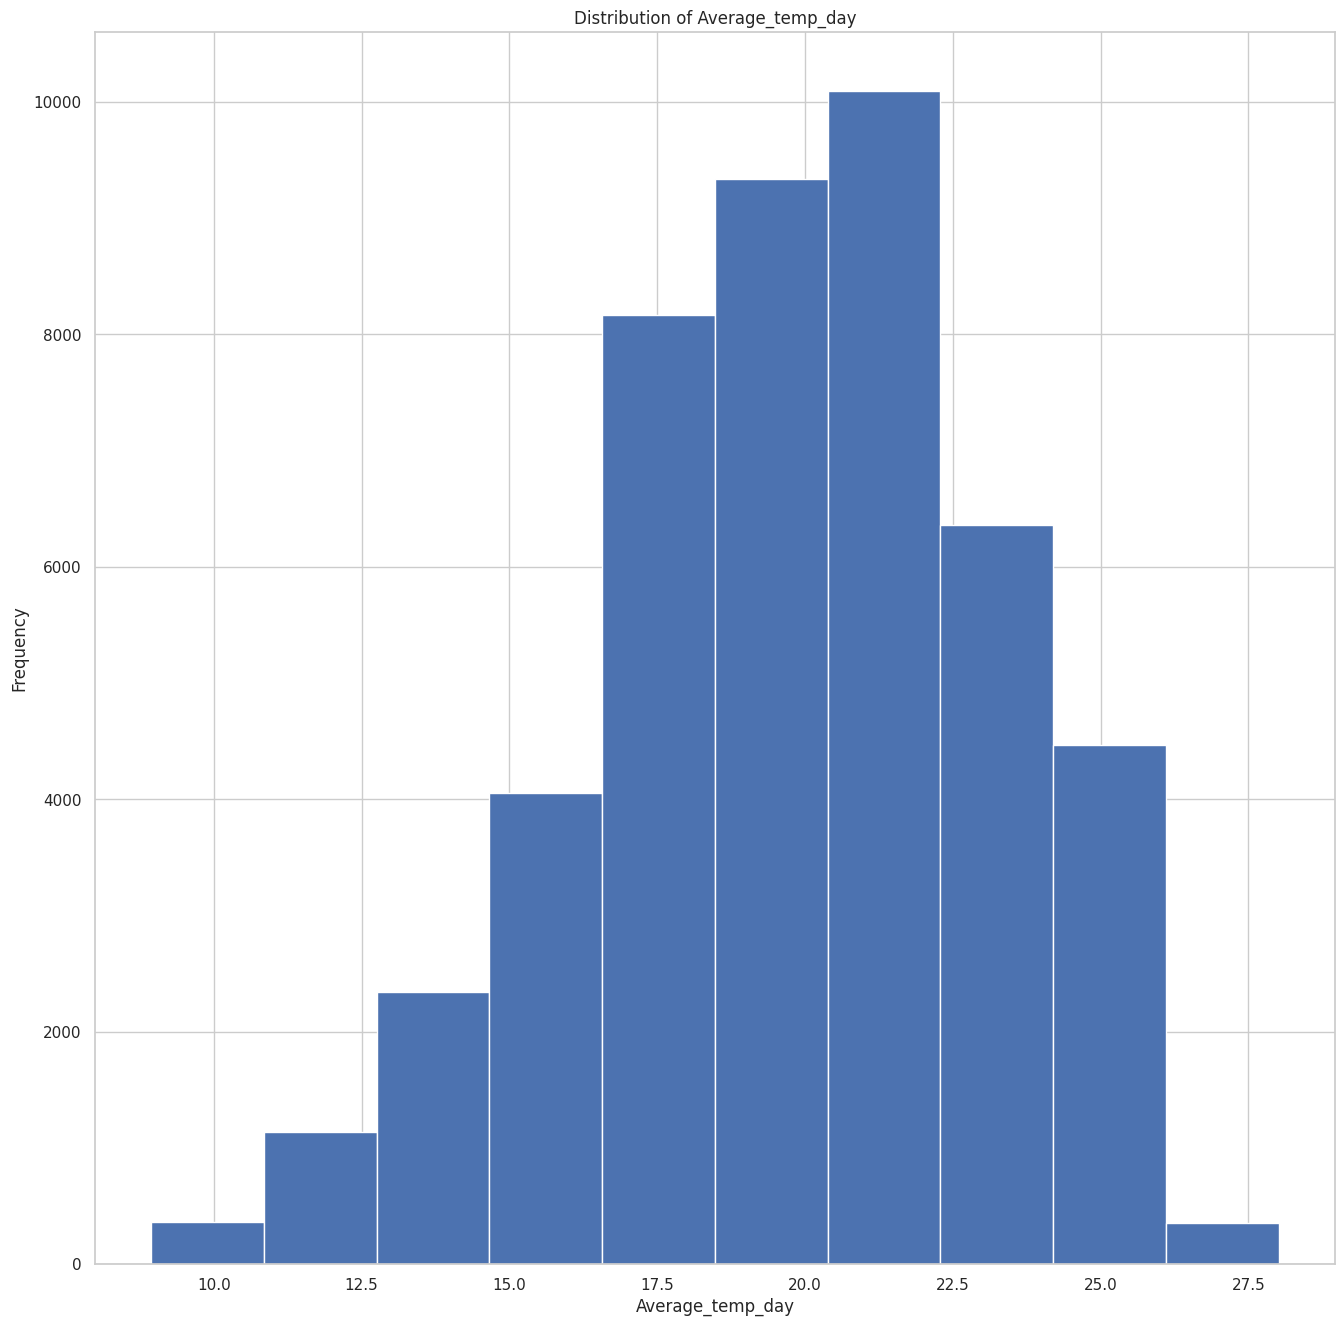

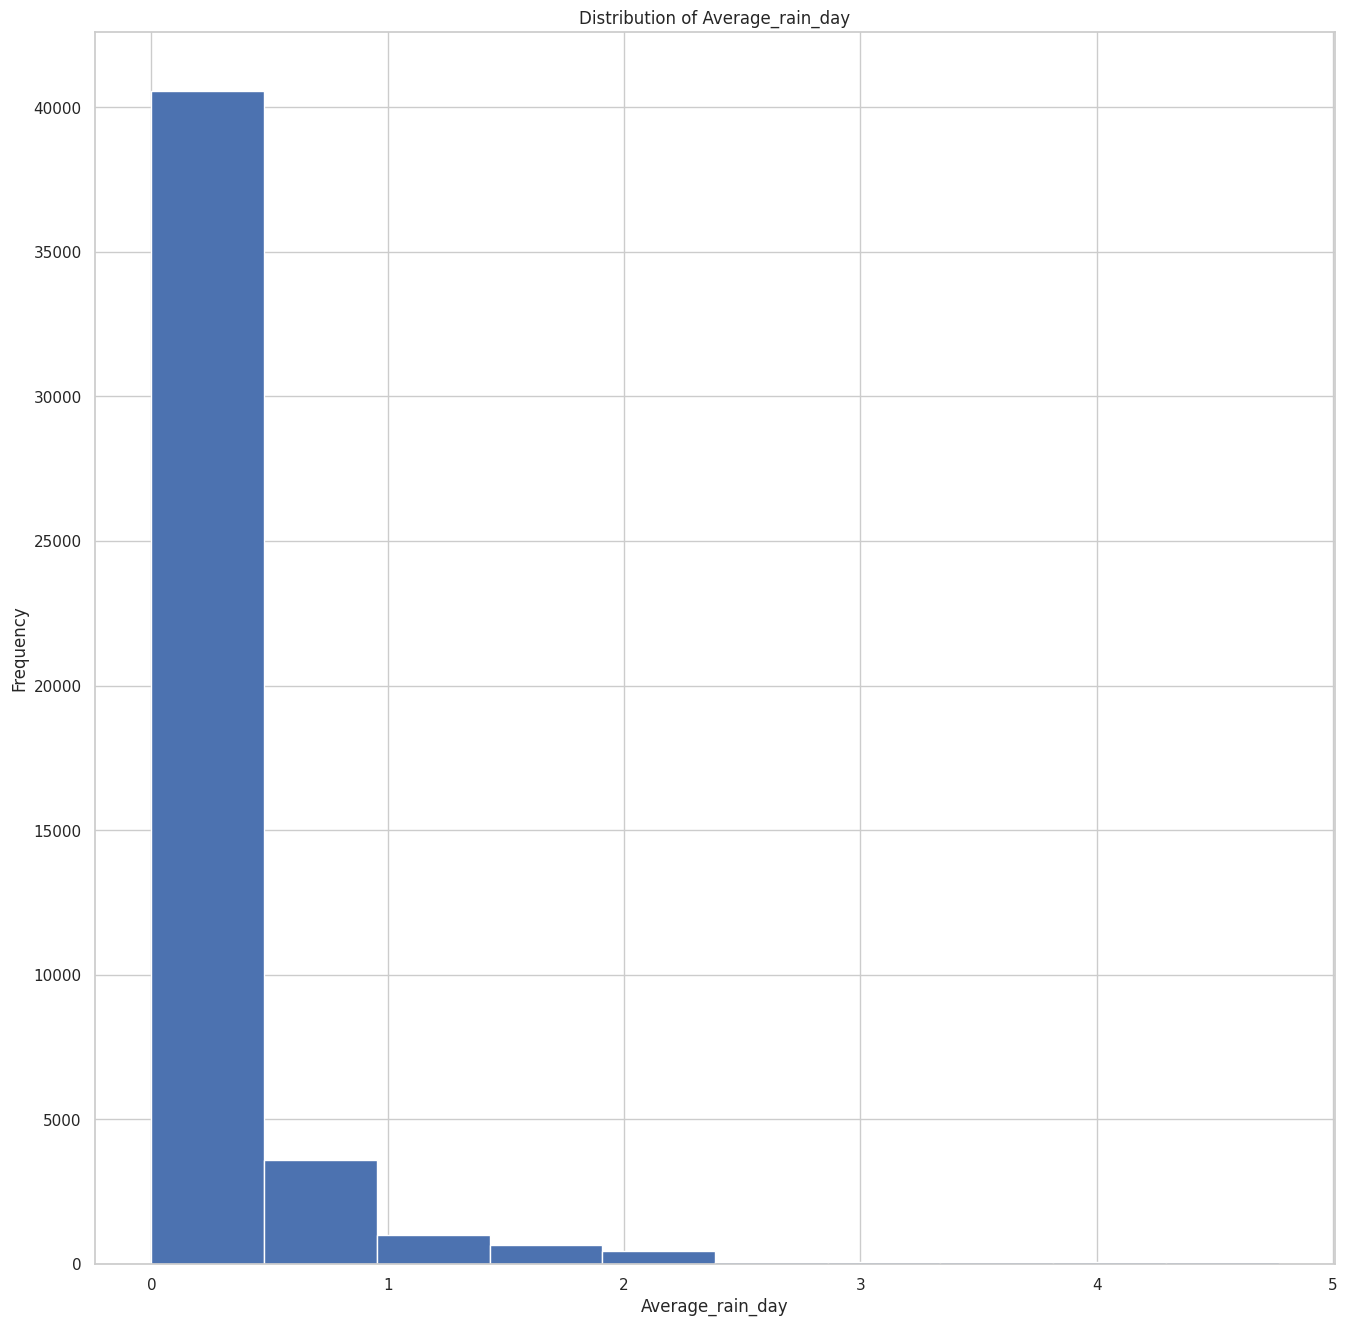

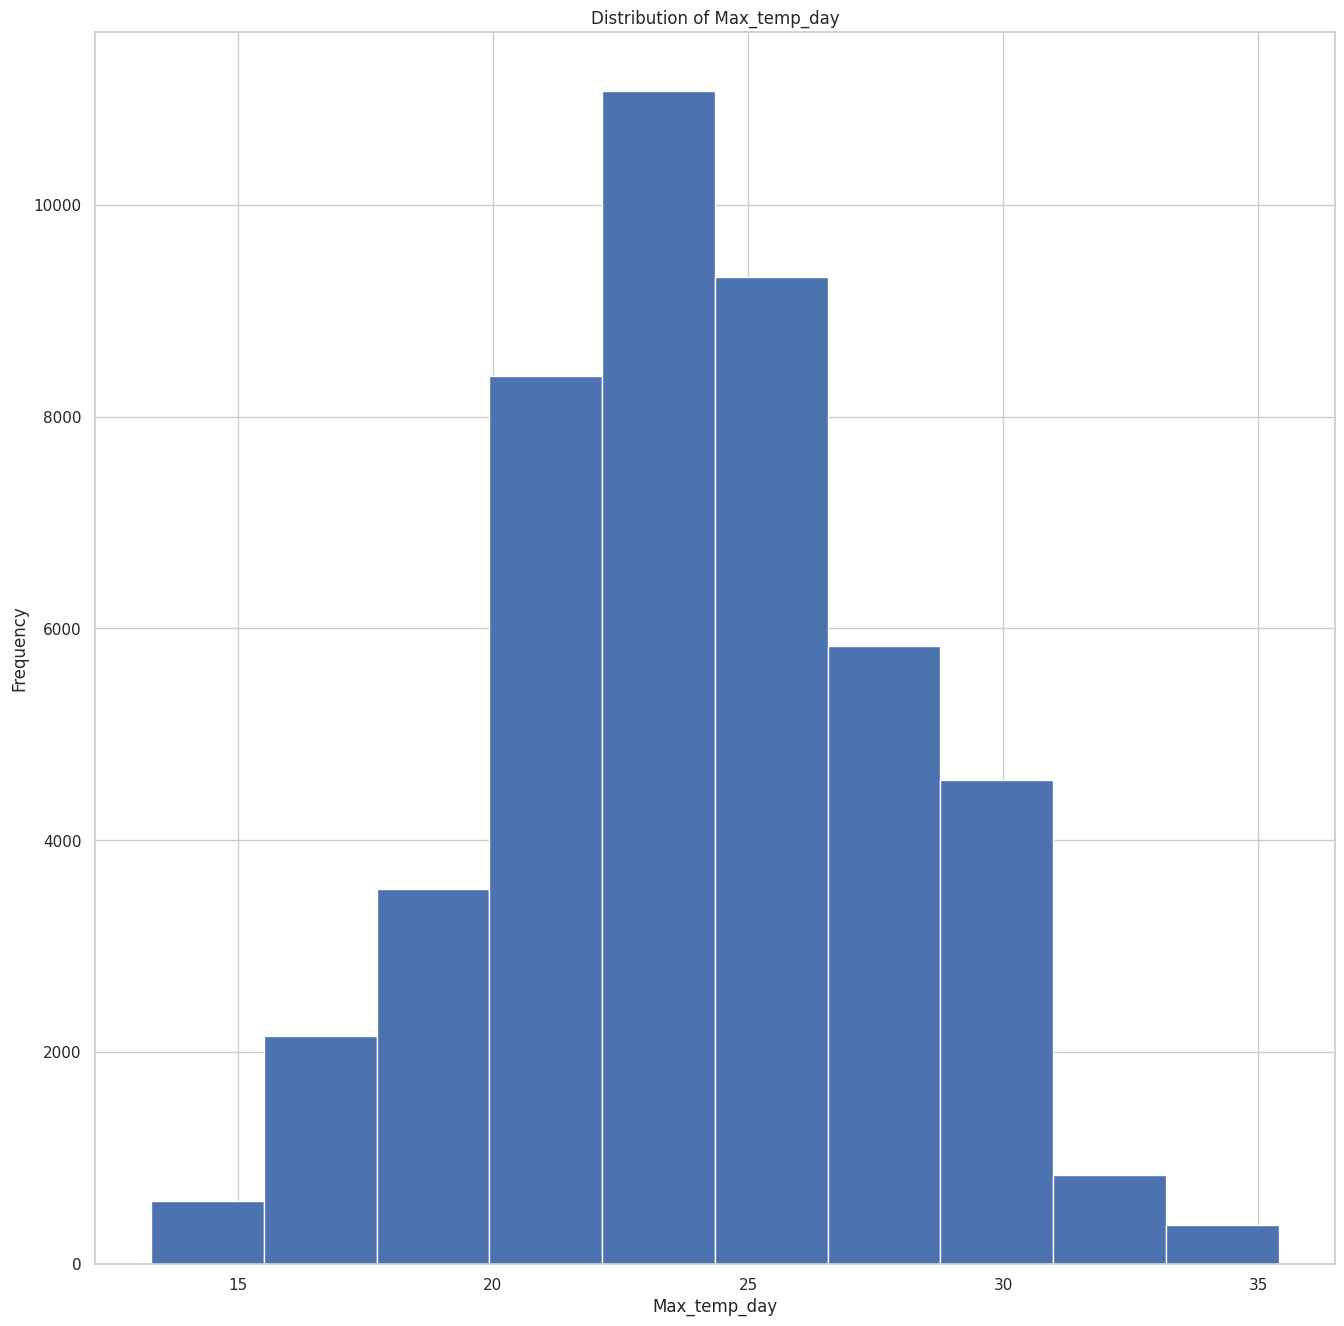

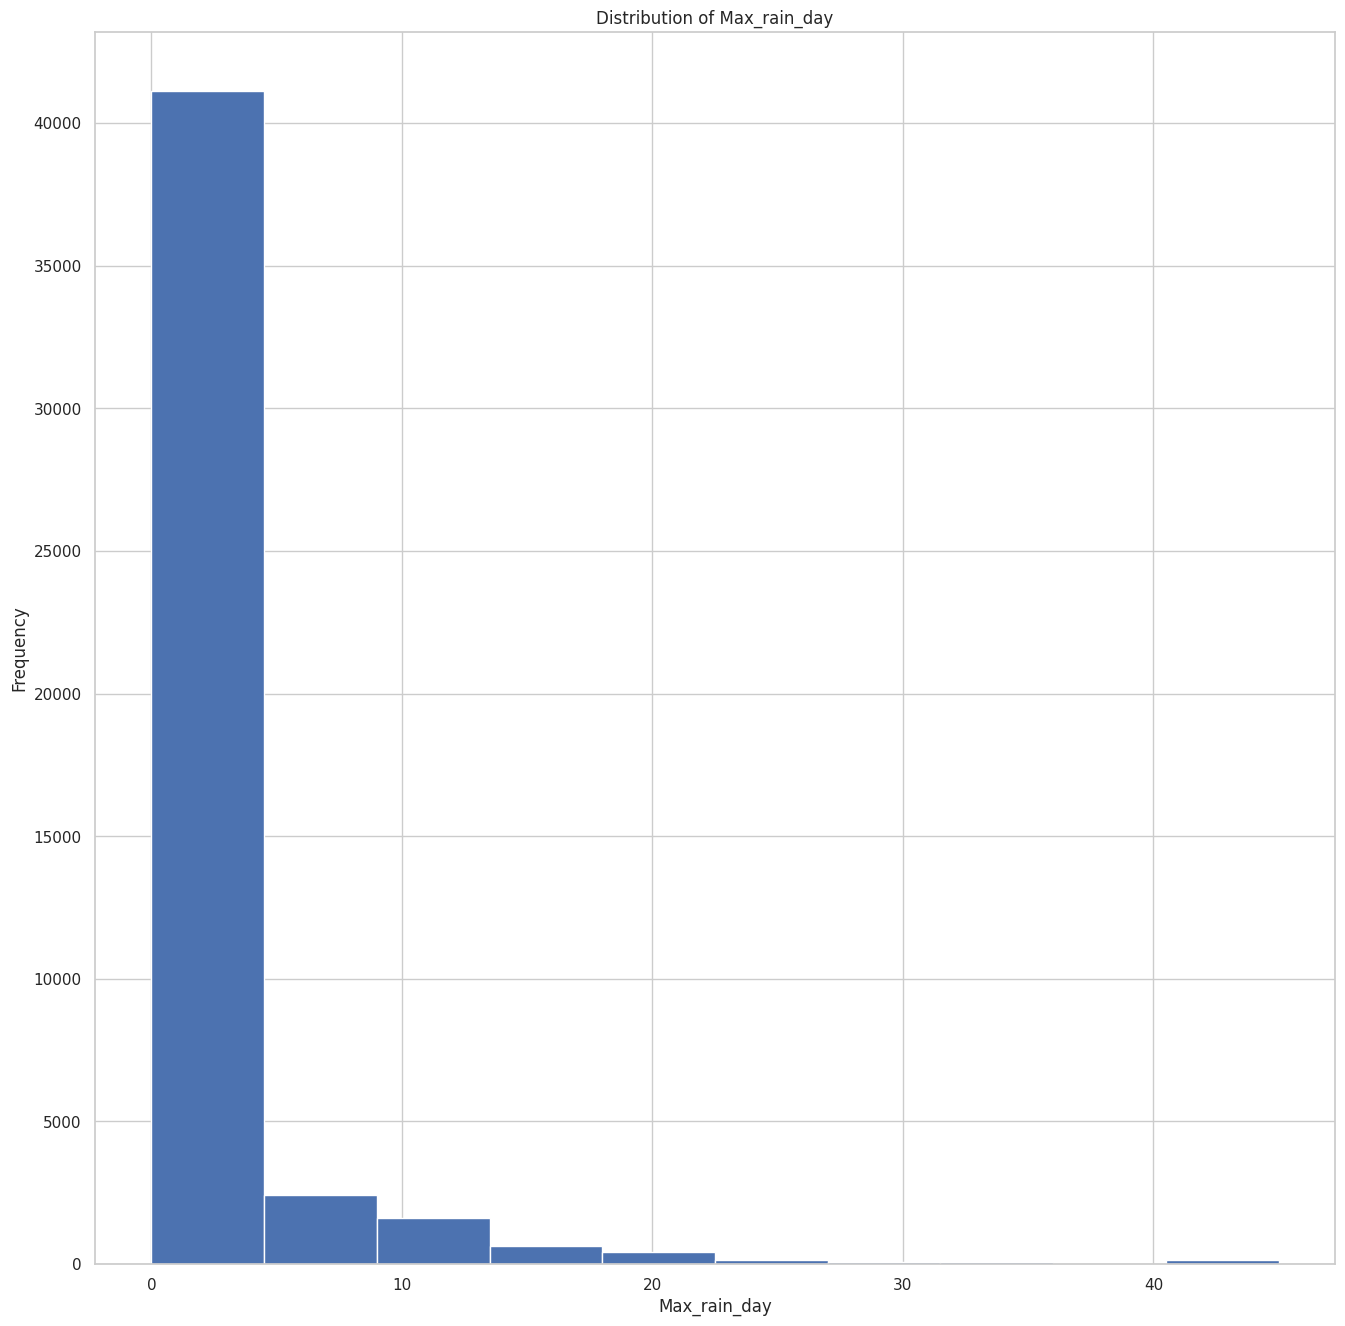

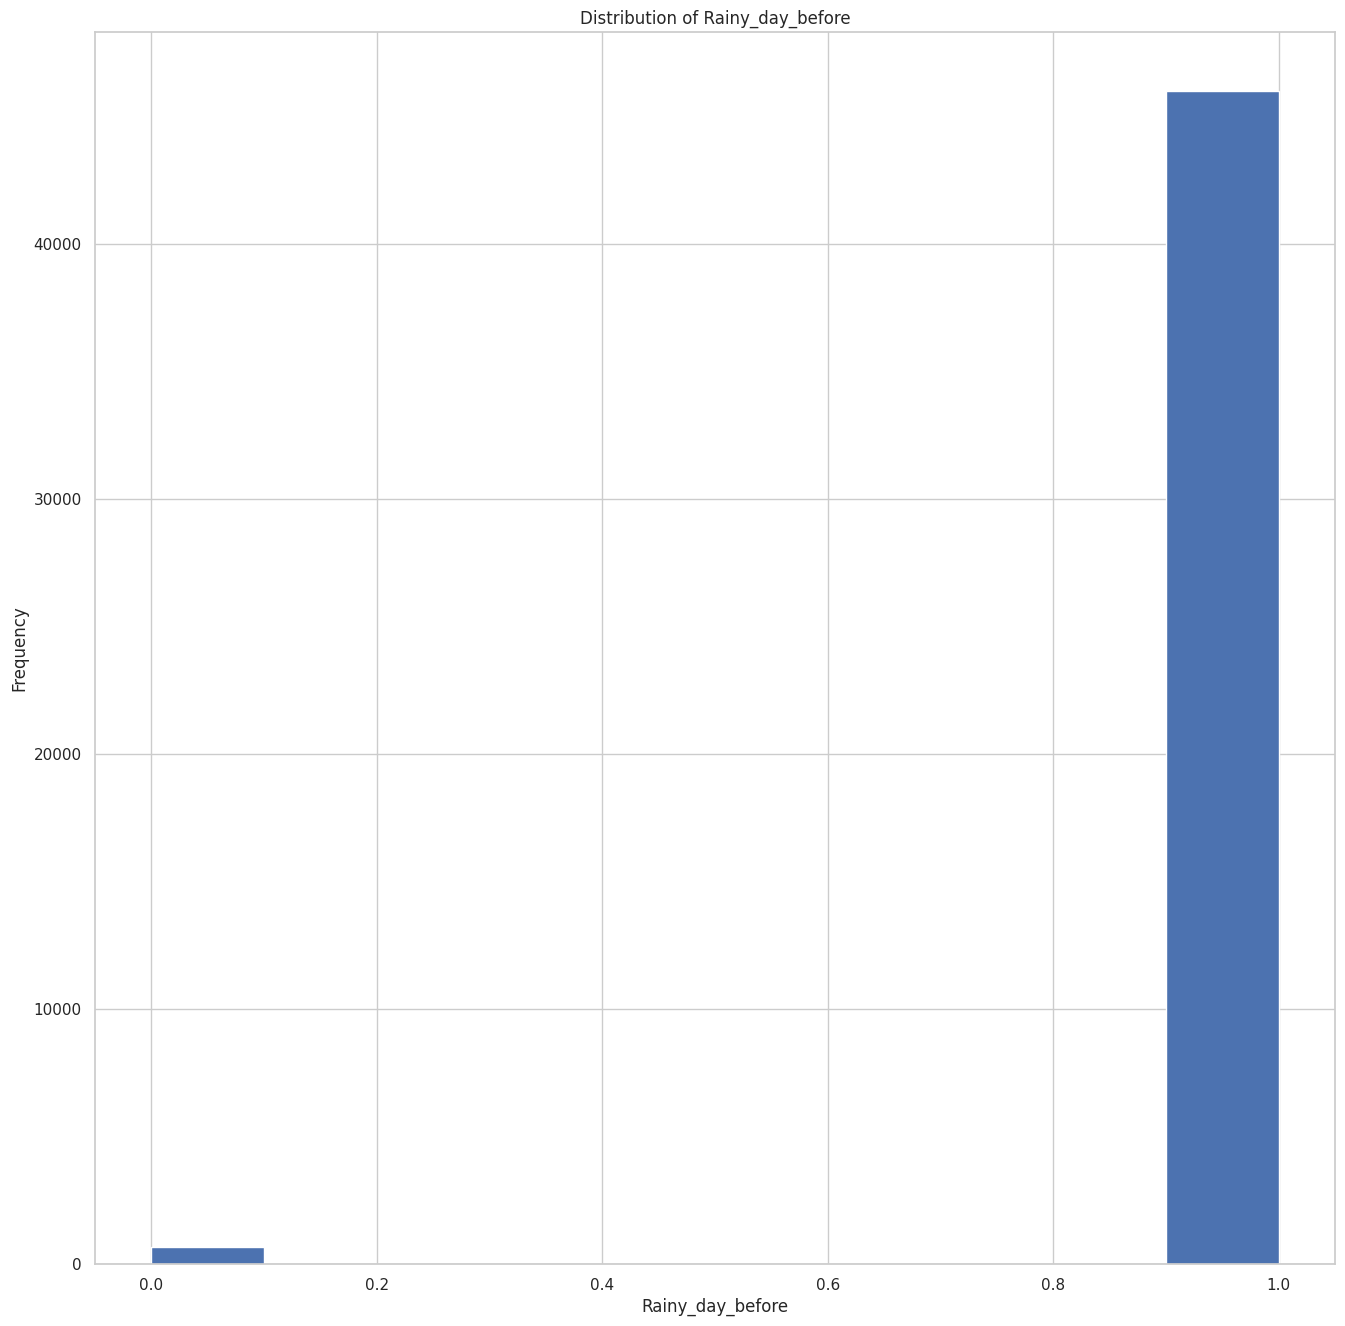

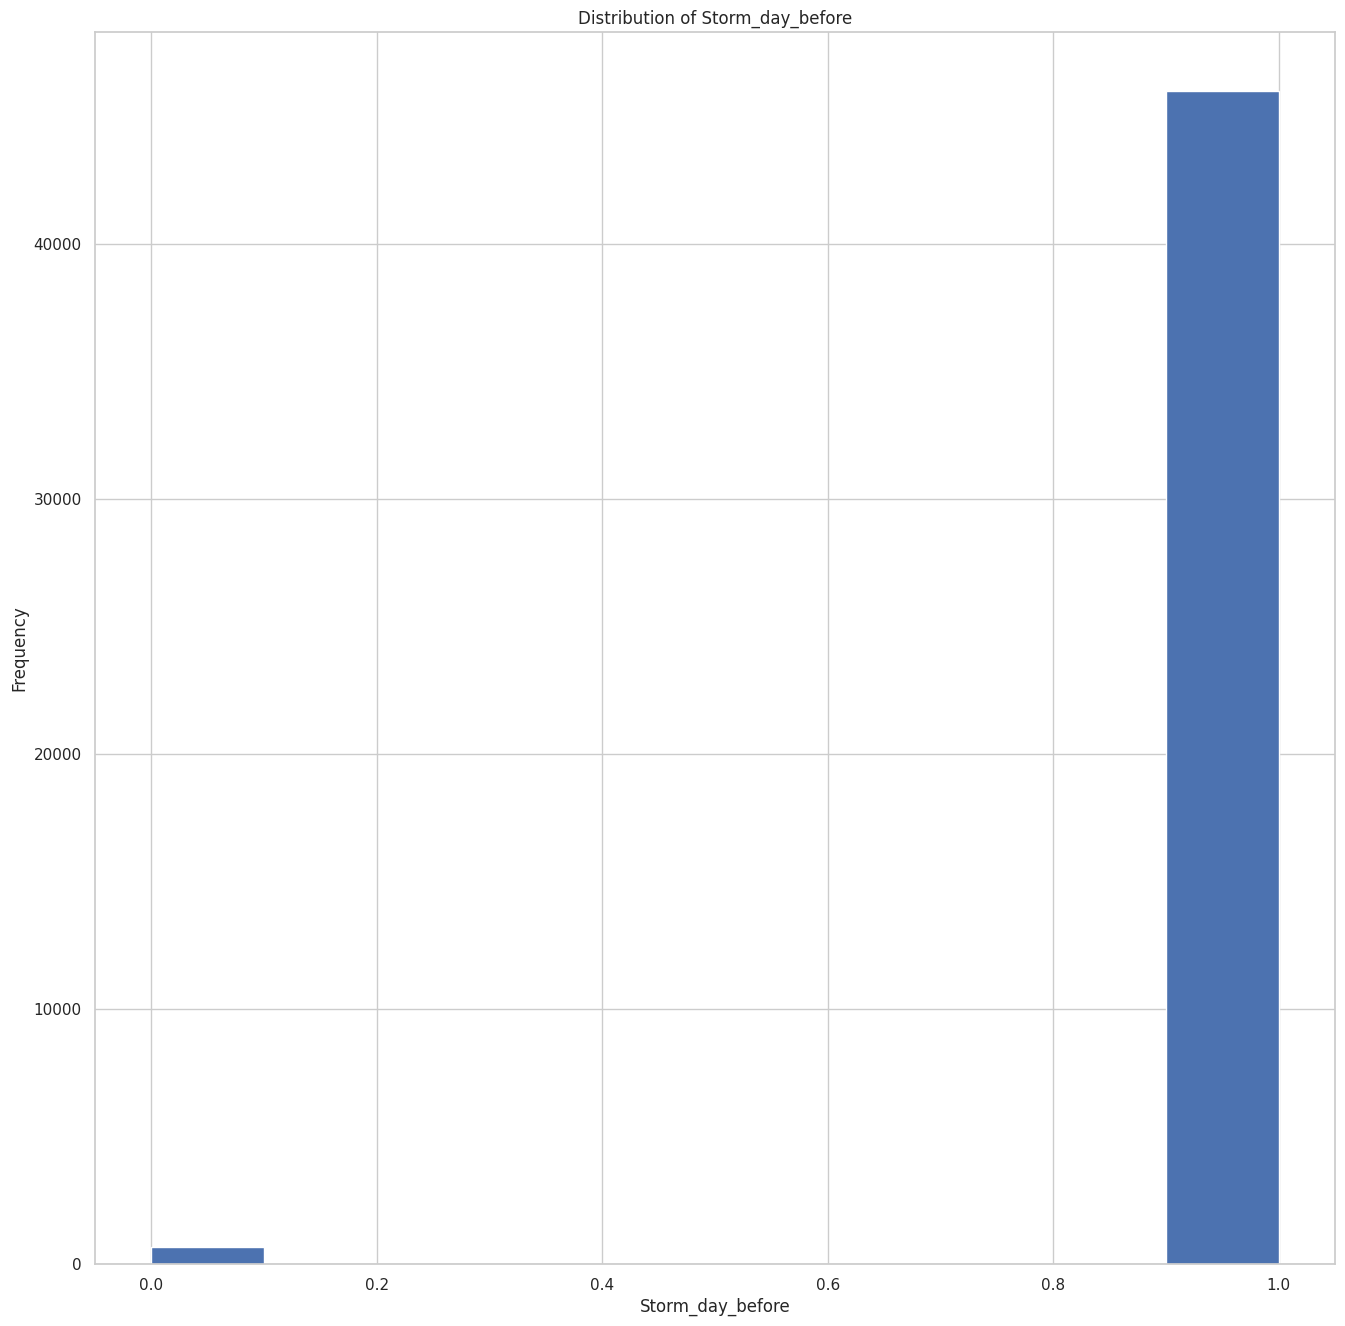

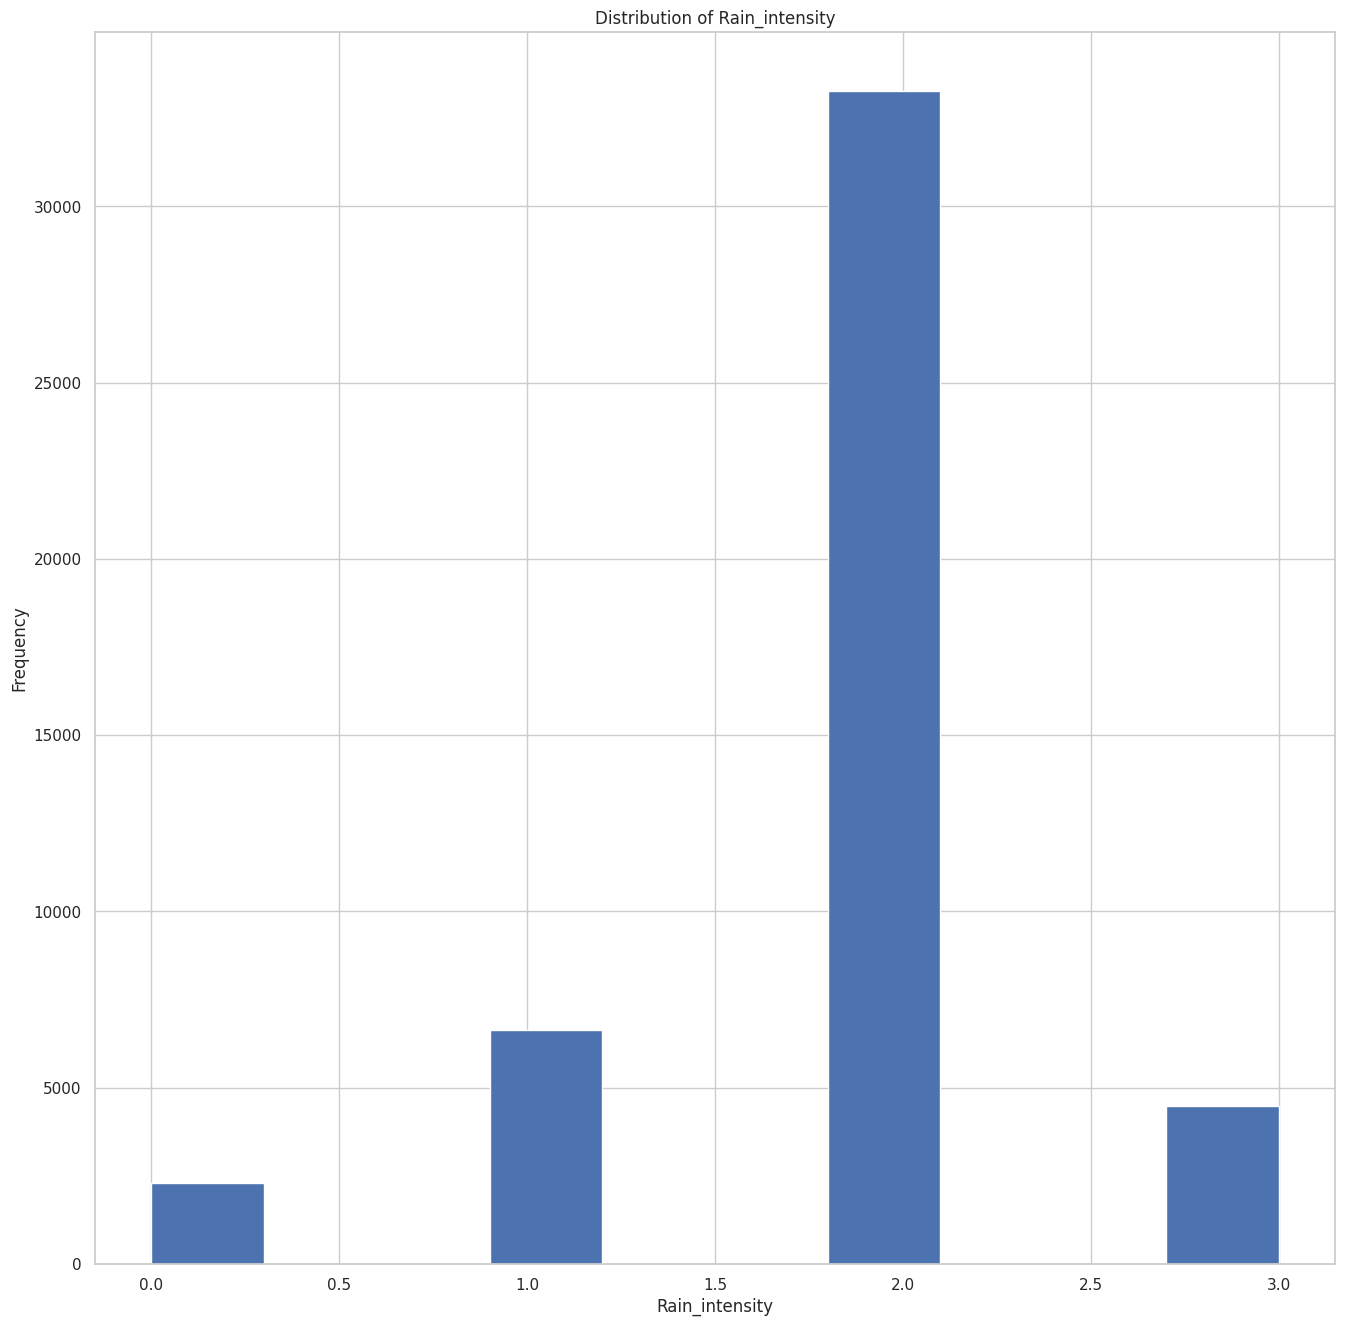

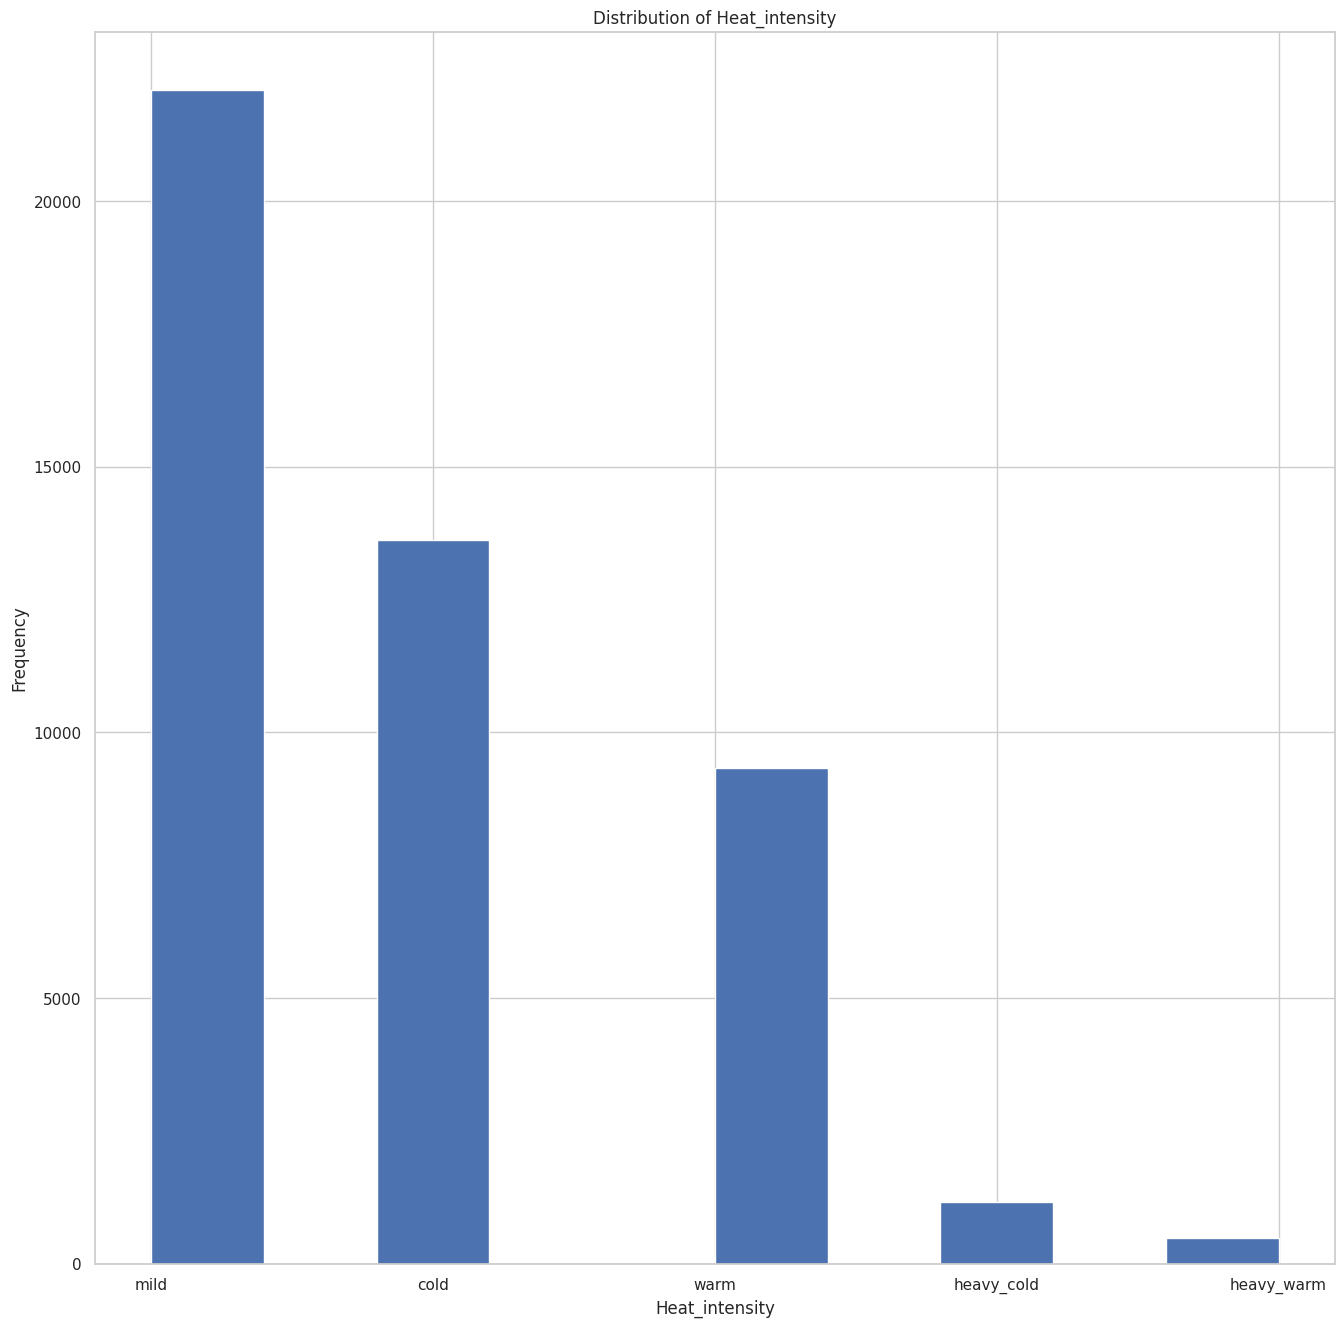

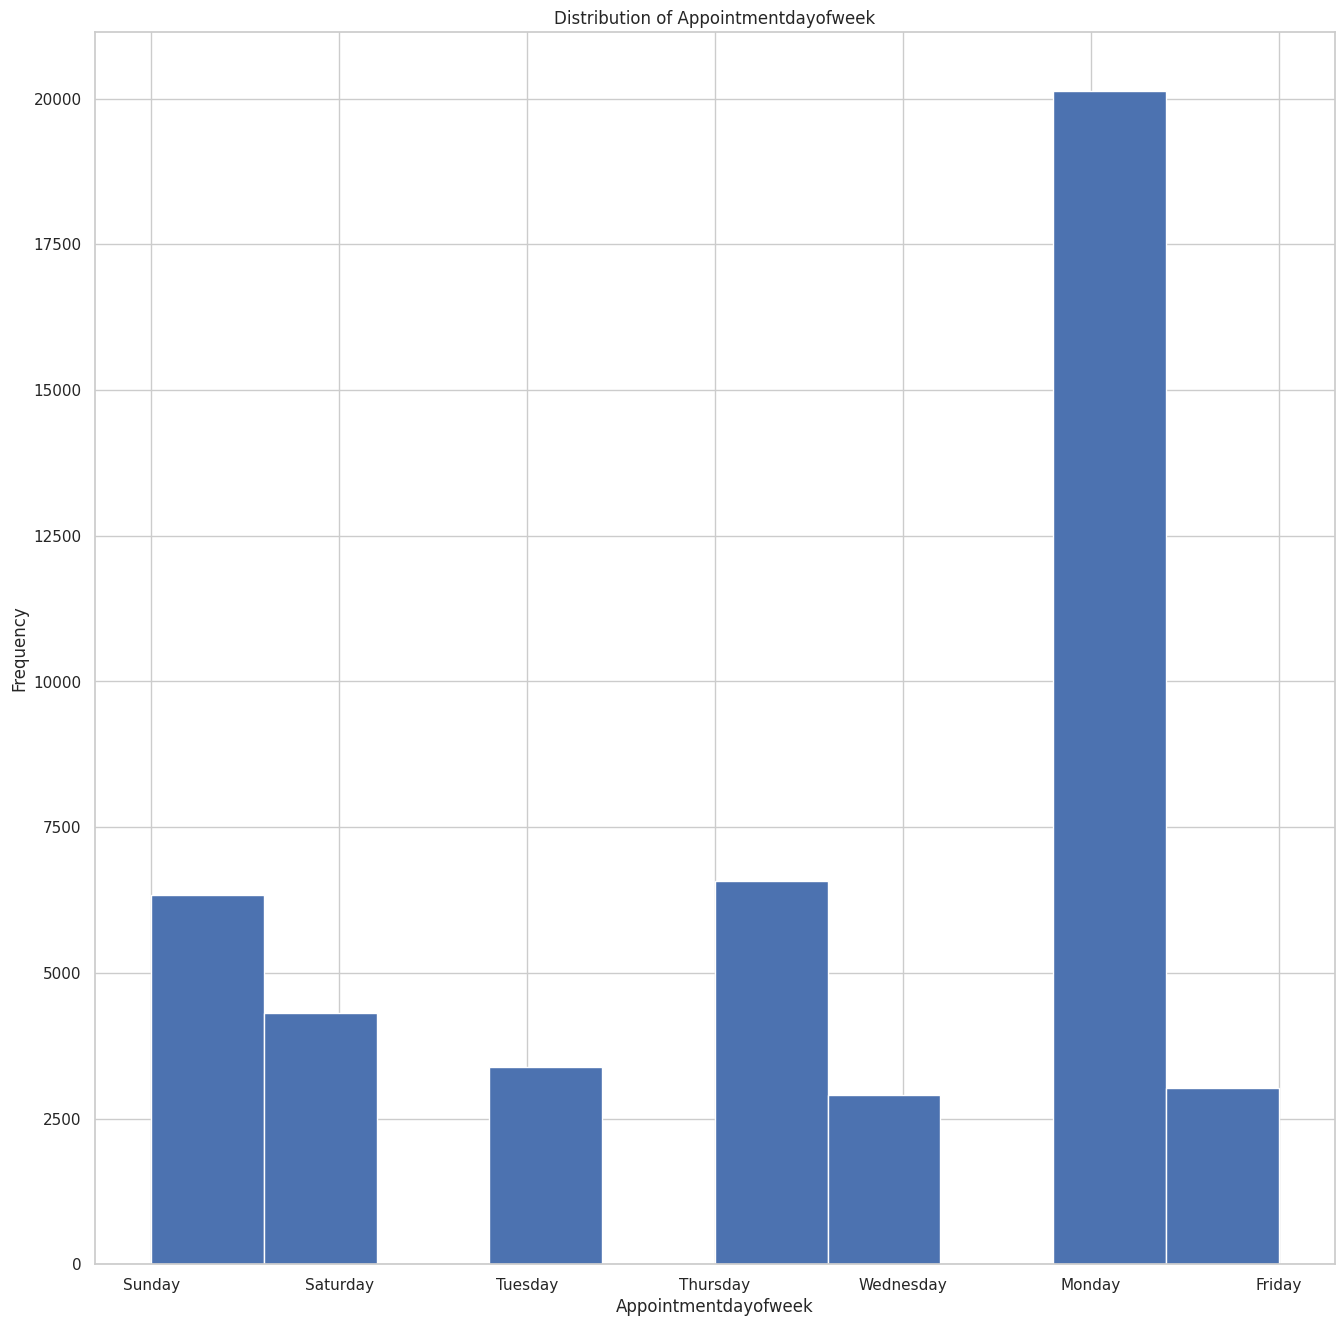

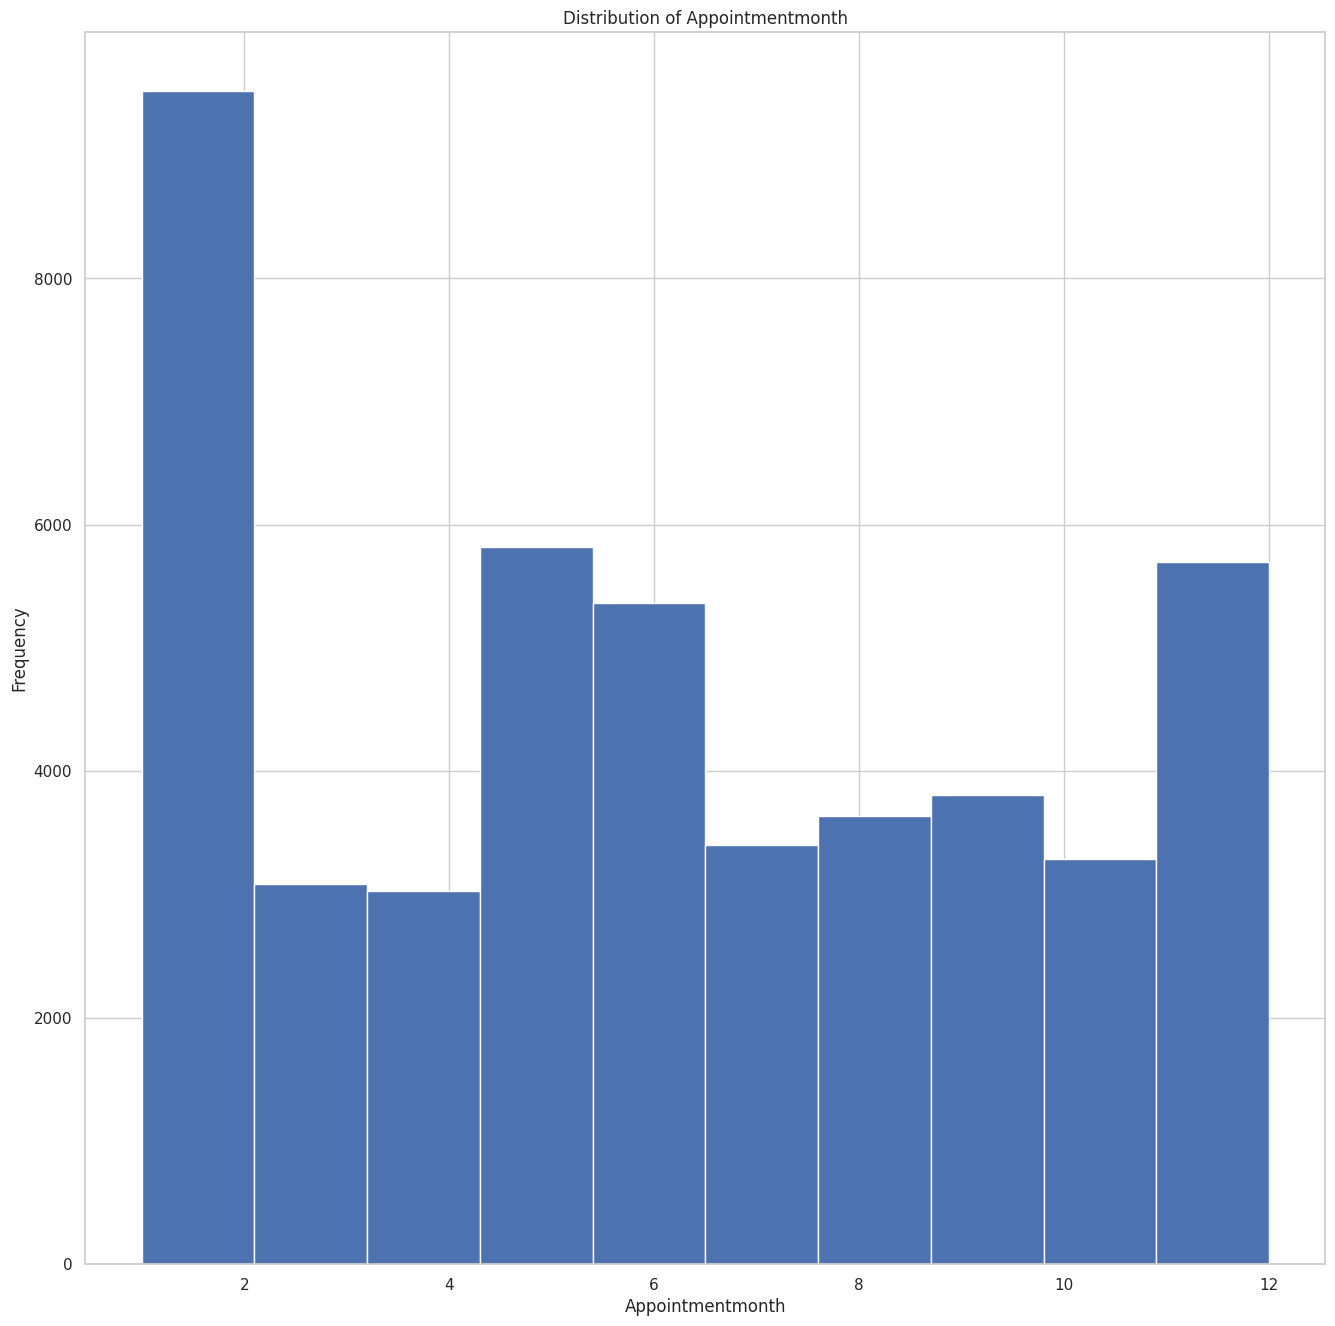

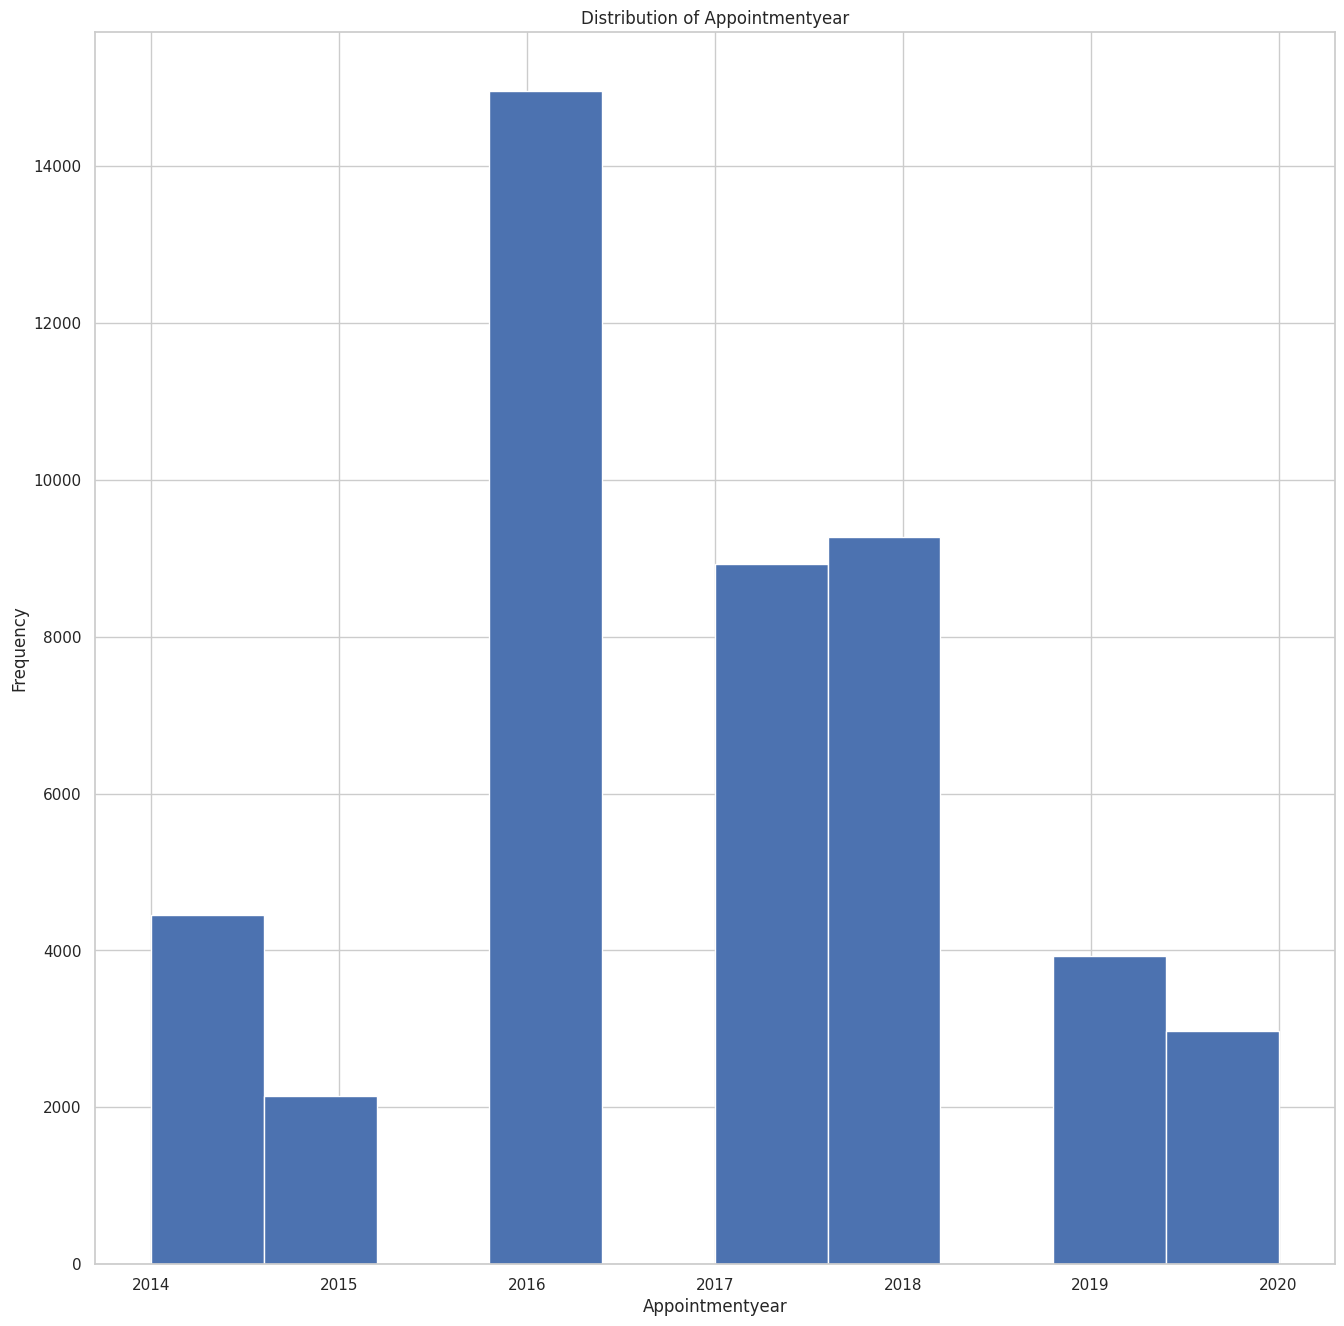

In [ ]:
# List of variables for which histograms will be created
variables = [
    "specialty", "scheduledhour", "gender", "no_show",
    "appointment_year", "appointment_shift", "age",
    "age_group", "patient_needs_companion", "average_temp_day",
    "average_rain_day", "max_temp_day", "max_rain_day", "rainy_day_before",
    "storm_day_before", "rain_intensity", "heat_intensity",
    "appointmentdayofweek", "appointmentmonth", "appointmentyear"
]

# Plot histograms for each variable
for variable in variables:
    plt.figure(figsize=(16,16));
    df[variable].hist()
    plt.xlabel(variable.capitalize())
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {variable.capitalize()}")
    plt.show()

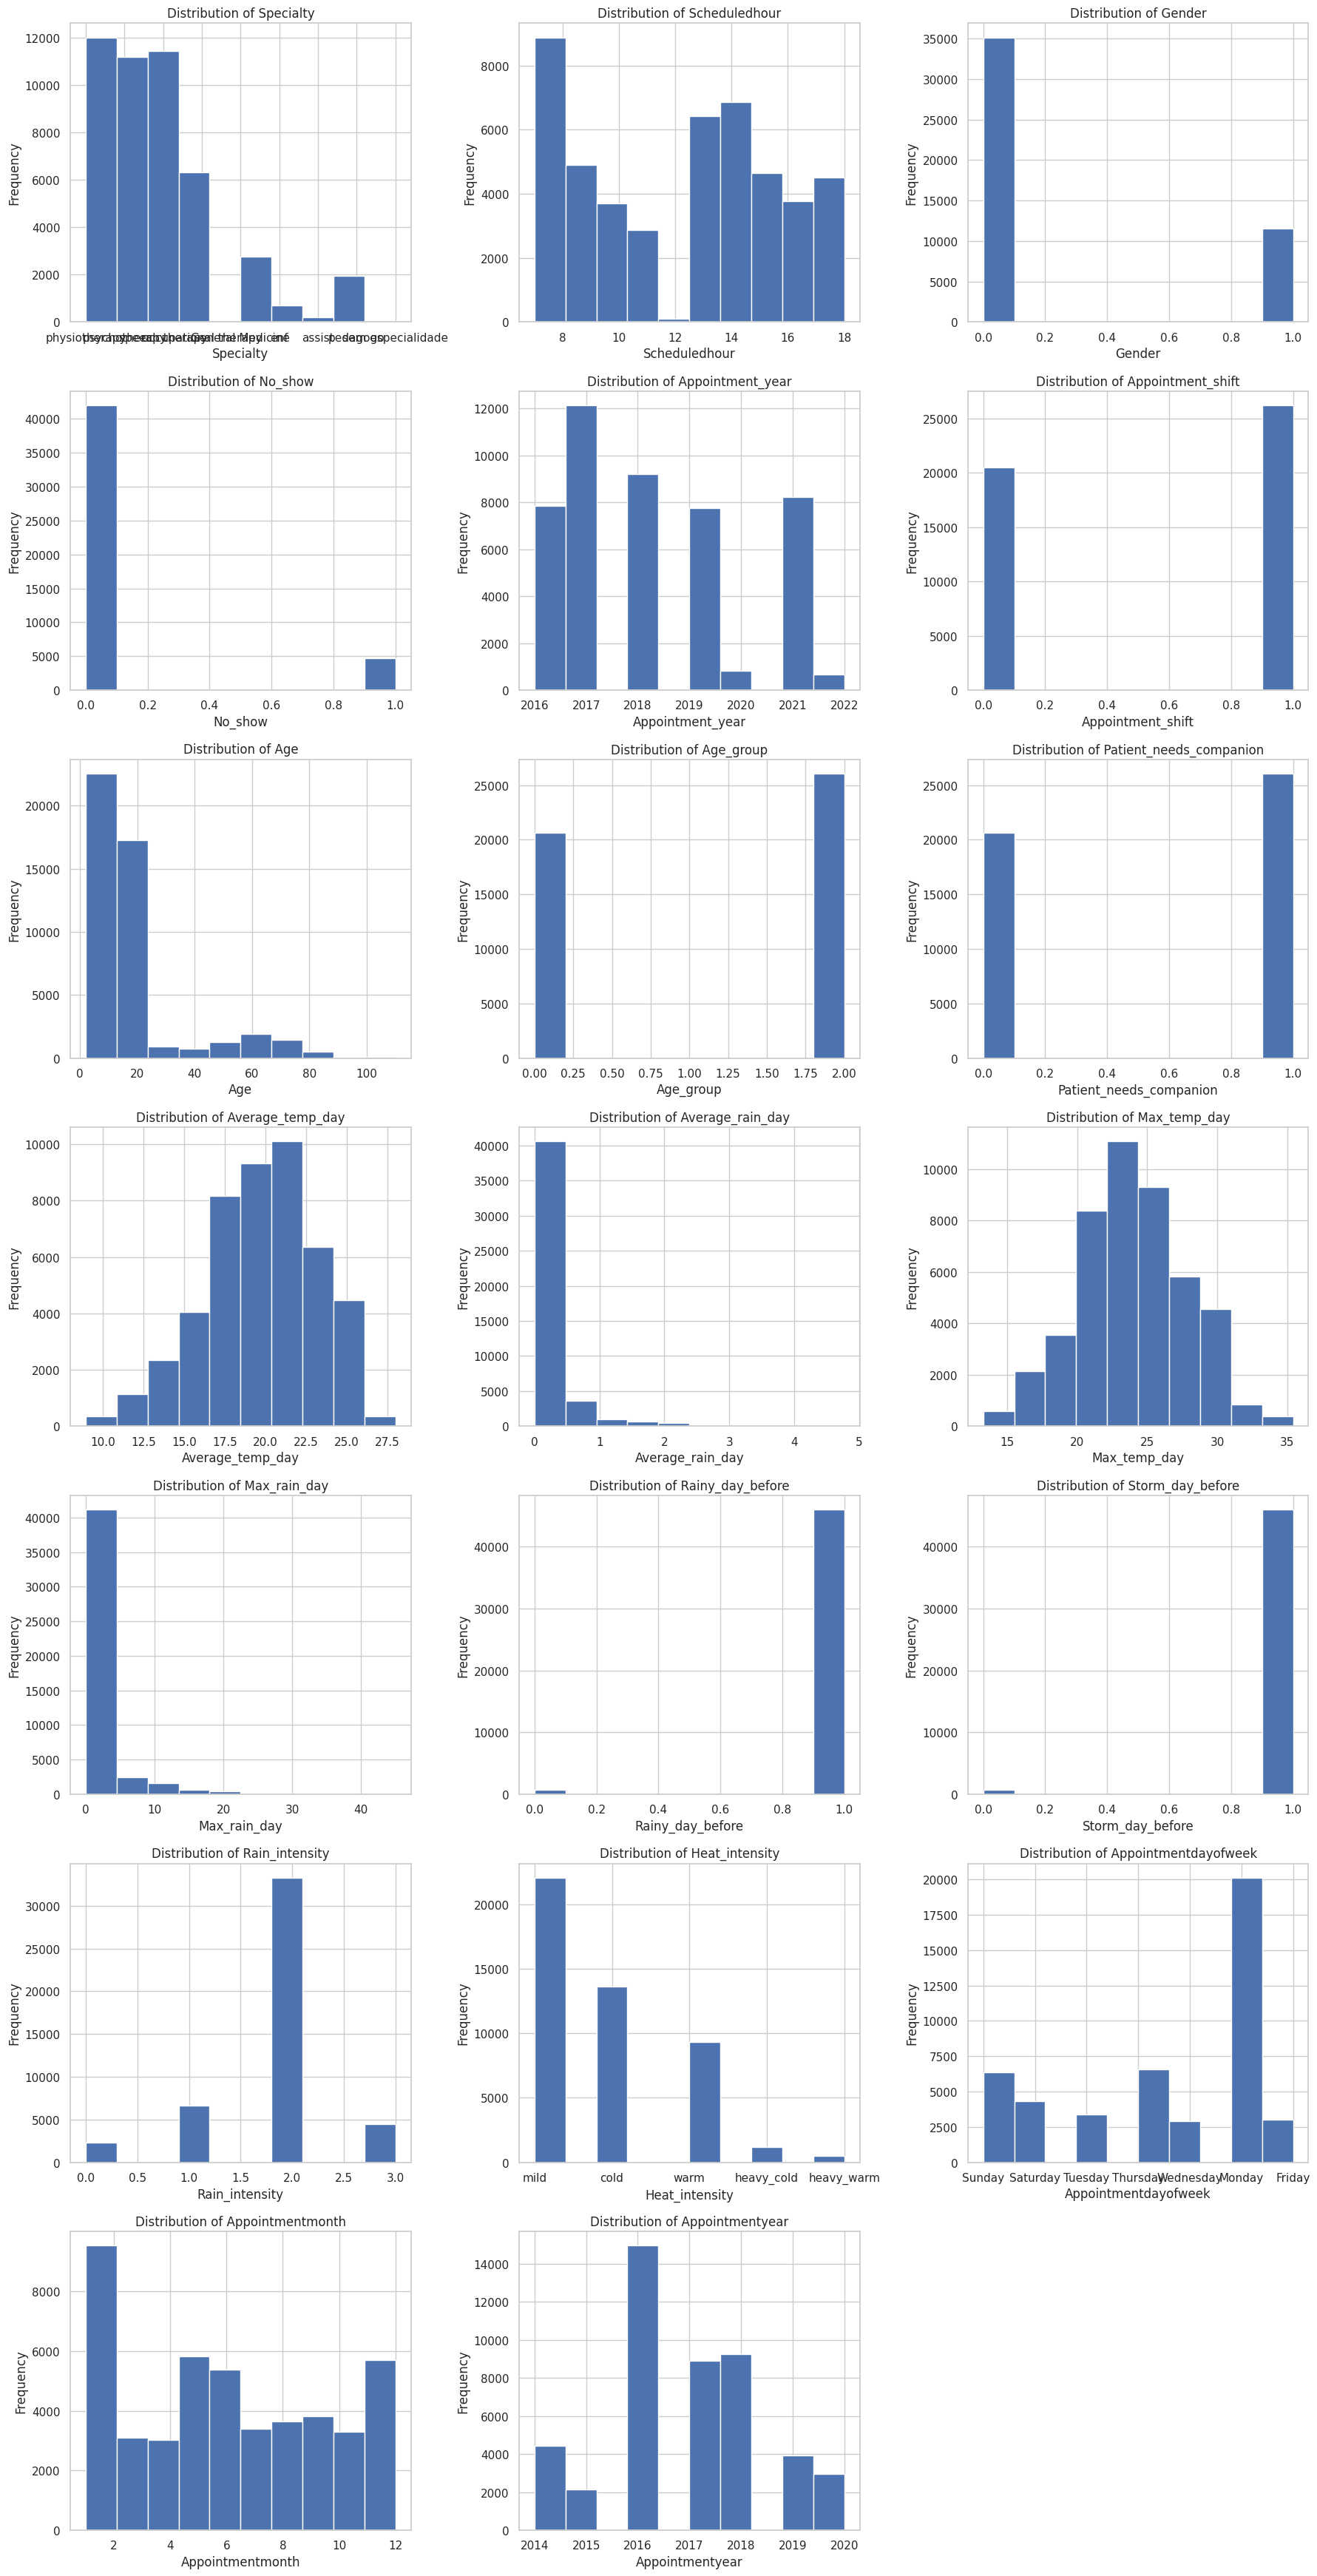

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming you have a DataFrame named 'df' and a list of variables 'variables'
# Replace this with your actual DataFrame and variables list

# Set the number of columns and rows for the subplot grid
num_cols = 3
num_rows = len(variables) // num_cols + (len(variables) % num_cols > 0)

# Create subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 5 * num_rows))

# Flatten the axes array for easier indexing
axes = axes.flatten()

# Plot histograms for each variable in the grid
for i, variable in enumerate(variables):
    ax = axes[i]
    df[variable].hist(ax=ax)
    ax.set_xlabel(variable.capitalize())
    ax.set_ylabel("Frequency")
    ax.set_title(f"Distribution of {variable.capitalize()}")

# Remove empty subplots
for i in range(len(variables), num_cols * num_rows):
    fig.delaxes(axes[i])

# Adjust layout
plt.tight_layout()
plt.show()


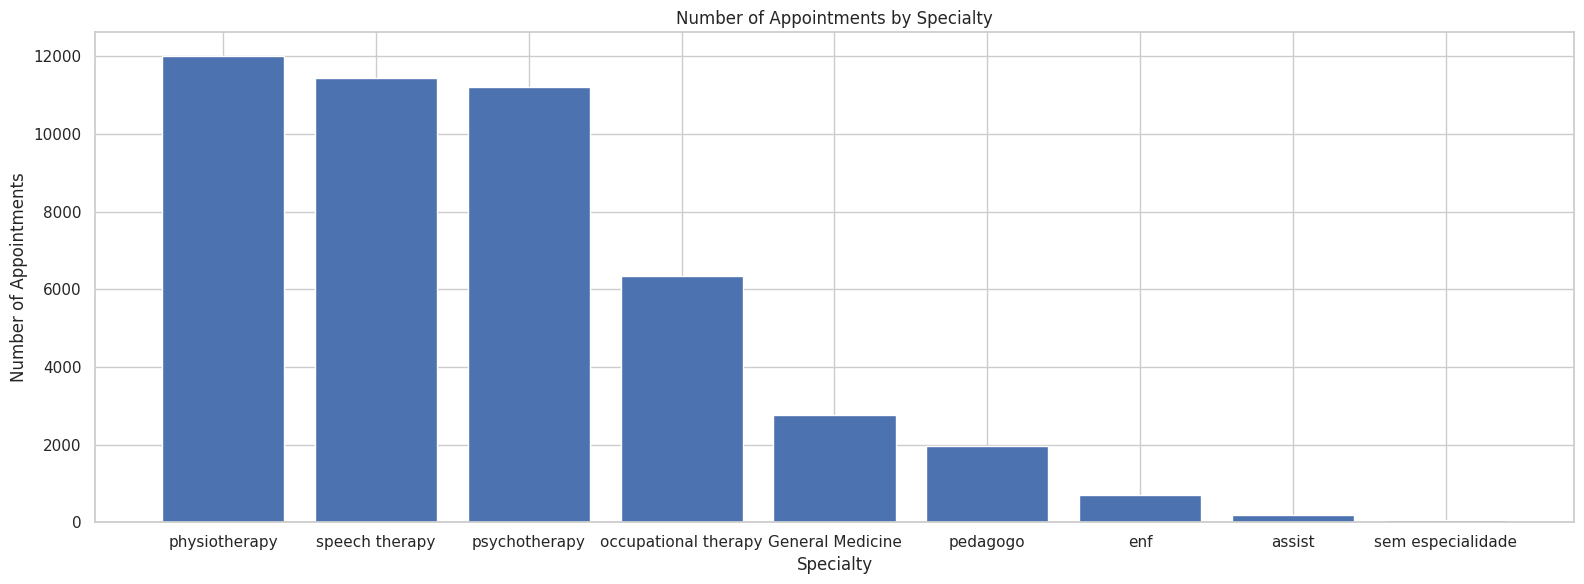

In [ ]:
# Count the number of appointments for each specialty
specialty_counts = df['specialty'].value_counts()

# Create a bar chart
plt.figure(figsize=(16, 6))
plt.bar(specialty_counts.index, specialty_counts.values)
plt.xlabel('Specialty')
plt.ylabel('Number of Appointments')
plt.title('Number of Appointments by Specialty')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

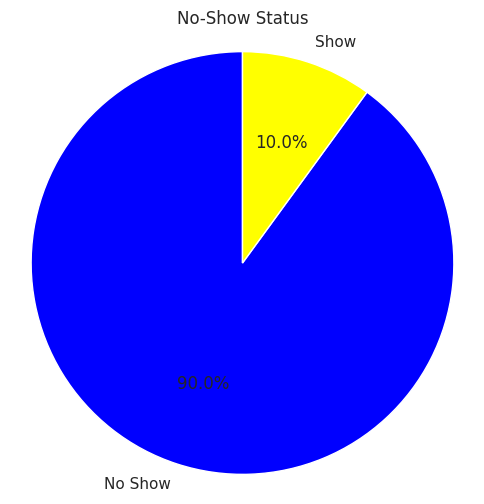

In [ ]:
# Count the number of appointments for each no-show status
noshow_counts = df['no_show'].value_counts()

# Create a pie chart
plt.figure(figsize=(6, 6))
plt.pie(noshow_counts.values, labels=['No Show', 'Show'], autopct='%1.1f%%', startangle=90, colors=['blue', 'yellow'])
plt.title('No-Show Status')
plt.axis('equal')
plt.show()


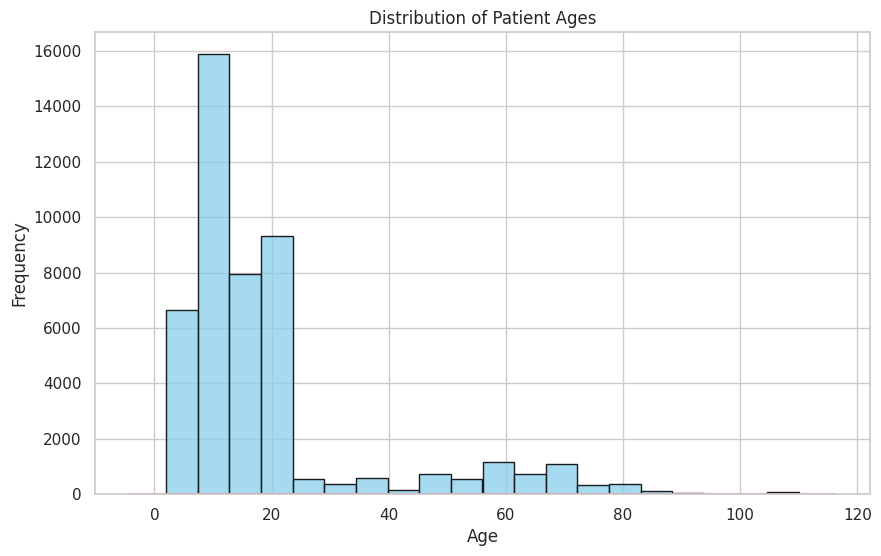

In [ ]:
import seaborn as sns

# Set the style for the plot
sns.set(style="whitegrid")

# Create a figure with subplots
fig, ax = plt.subplots(figsize=(10, 6))

# Plot histogram
sns.histplot(df['age'], bins=20, kde=False, color='skyblue', edgecolor='k', ax=ax)

# Plot KDE
sns.kdeplot(df['age'], color='red', ax=ax)

# Set labels and title
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Patient Ages')

# Show the plot
plt.show()

<Figure size 800x600 with 0 Axes>

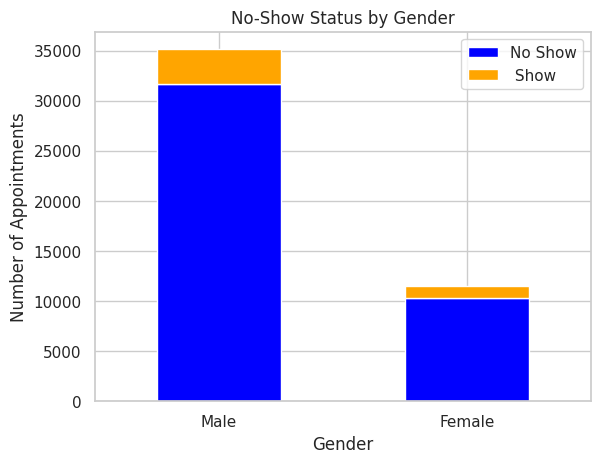

In [ ]:
# Count the number of appointments for each combination of gender and no-show status
gender_noshow_counts = df.groupby(['gender', 'no_show']).size().unstack()

# Create a stacked bar chart with blue and orange colors
plt.figure(figsize=(8, 6))
ax = gender_noshow_counts.plot(kind='bar', stacked=True, color=['blue', 'orange'])
plt.xlabel('Gender')
plt.ylabel('Number of Appointments')
plt.title('No-Show Status by Gender')
plt.xticks([0, 1], labels=['Male', 'Female'], rotation=0)  # Set x-axis labels

# Set legend labels
plt.legend( labels=['No Show', ' Show'], loc='upper right')

# Show the plot
plt.show()


<Figure size 1000x600 with 0 Axes>

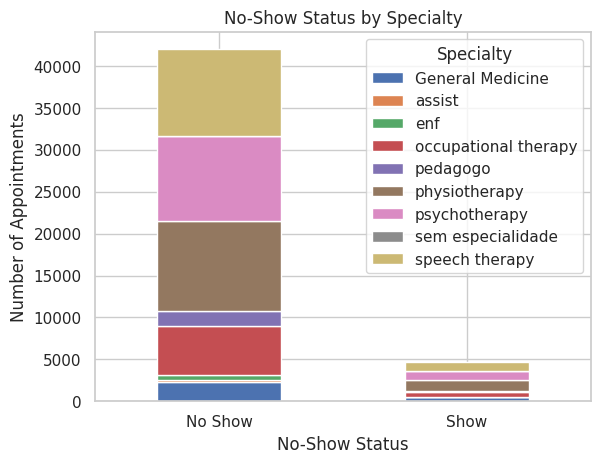

In [ ]:
# Count the number of appointments for each combination of no-show status and specialty
noshow_specialty_counts = df.groupby(['no_show', 'specialty']).size().unstack()

# Create a stacked bar chart
plt.figure(figsize=(10, 6))
ax = noshow_specialty_counts.plot(kind='bar', stacked=True)
plt.xlabel('No-Show Status')
plt.ylabel('Number of Appointments')
plt.title('No-Show Status by Specialty')
plt.legend(title='Specialty')
plt.xticks([0, 1], labels=['No Show', 'Show'], rotation=0)  # Set x-axis labels

# Show the plot
plt.show()

In [ ]:
showed_up = df.no_show == True
no_showed = df.no_show == False

In [ ]:
df['no_show'].unique()

array([1, 0])

In [ ]:
# Count the number of appointments for each no-show status
no_show_counts = df['no_show'].value_counts().rename({0: 'No Show', 1: 'Show'})

# Display the counts with updated labels
print(no_show_counts)


No Show    41994
Show        4678
Name: no_show, dtype: int64


In [ ]:
# Calculate the percentage for each no-show status
showed_percentage = df['no_show'].value_counts(normalize=True).rename({0: 'No Show', 1: 'Show'}) * 100

# Display the percentages with updated labels
print(showed_percentage)


No Show    89.97686
Show       10.02314
Name: no_show, dtype: float64


In [ ]:
df['gender'].unique() # M': 0, 'F': 1

array([0, 1])

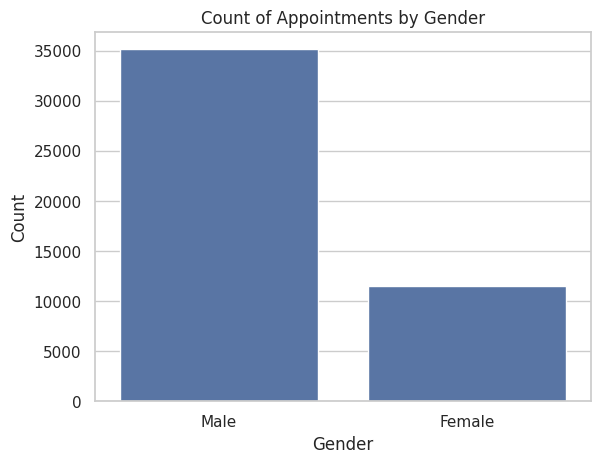

In [ ]:

# Assuming 'gender' column values are 0 for Male and 1 for Female
# If it's the other way around, you can reverse the order in xticklabels

# Create a count plot
sns.countplot(x='gender', data=df)

# Set x-axis labels
plt.xticks([0, 1], labels=['Male', 'Female'])

# Set labels and title
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Count of Appointments by Gender')

# Show the plot
plt.show()


In [ ]:
# Count the number of appointments for each gender
gender_counts = df['gender'].value_counts()

# Rename the index labels for better clarity
gender_counts = gender_counts.rename({0: 'Male', 1: 'Female'})

# Display the counts
print(gender_counts)


Male      35139
Female    11533
Name: gender, dtype: int64


In [ ]:
# Calculate the percentage of appointments for each gender
gender_percentage = df['gender'].value_counts(normalize=True) * 100

# Rename the index labels for better clarity
gender_percentage = gender_percentage.rename({0: 'Male', 1: 'Female'})

# Display the percentages
print(gender_percentage)


Male      75.289253
Female    24.710747
Name: gender, dtype: float64


In [ ]:
# Group by gender and find the mean value of show rate
gender_show_rate = df.groupby('gender')['no_show'].mean().rename({0: 'Male', 1: 'Female'})

# Display the mean show rate
print(gender_show_rate)


gender
Male      0.099149
Female    0.103529
Name: no_show, dtype: float64


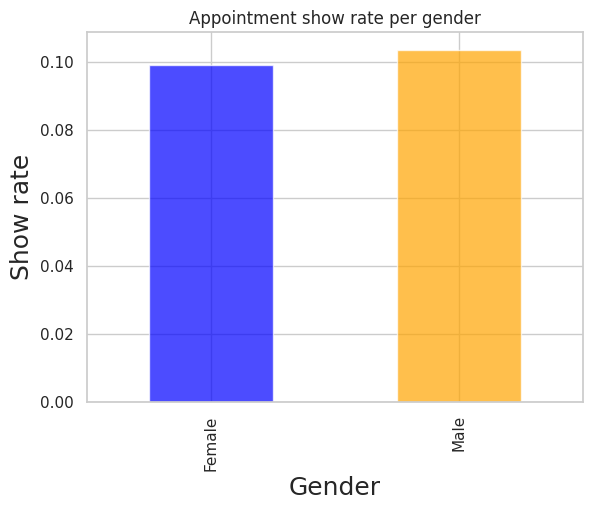

In [ ]:
#Show up rate (gender)
df.groupby('gender')['no_show'].mean().plot(kind='bar', alpha=.7, color=['blue', 'orange']);

# title and labels
plt.xticks([0, 1], ['Female', 'Male'])
plt.ylabel('Show rate', fontsize=18)
plt.xlabel('Gender', fontsize=18)
plt.title('Appointment show rate per gender');

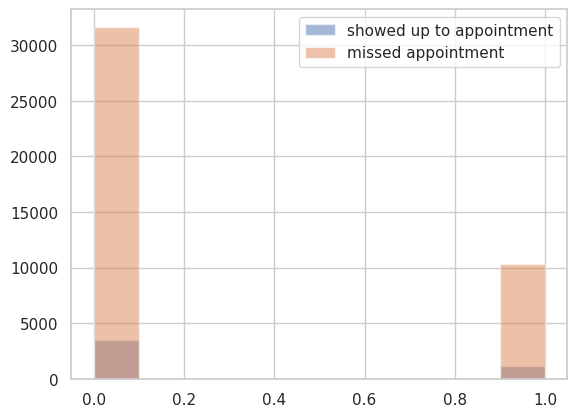

In [ ]:
df.gender[showed_up].hist(alpha=0.5, label = 'showed up to appointment')
df.gender[no_showed].hist(alpha=0.5, label = 'missed appointment');
plt.legend();

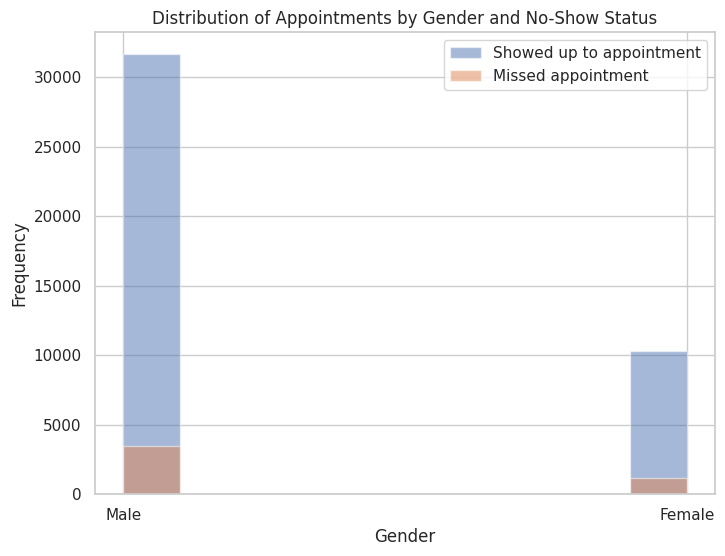

In [ ]:
# Assuming 'showed_up' and 'no_showed' are boolean masks for the corresponding conditions
# Replace these with your actual conditions

showed_up = df['no_show'] == 0
no_showed = df['no_show'] == 1

# Create histograms for 'showed up' and 'missed appointment'
plt.figure(figsize=(8, 6))

df.gender[showed_up].hist(alpha=0.5, label='Showed up to appointment')
df.gender[no_showed].hist(alpha=0.5, label='Missed appointment')

# Set x-axis labels
plt.xticks([0, 1], labels=['Male', 'Female'])

# Set labels and title
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.title('Distribution of Appointments by Gender and No-Show Status')

# Add legend
plt.legend()

# Show the plot
plt.show()


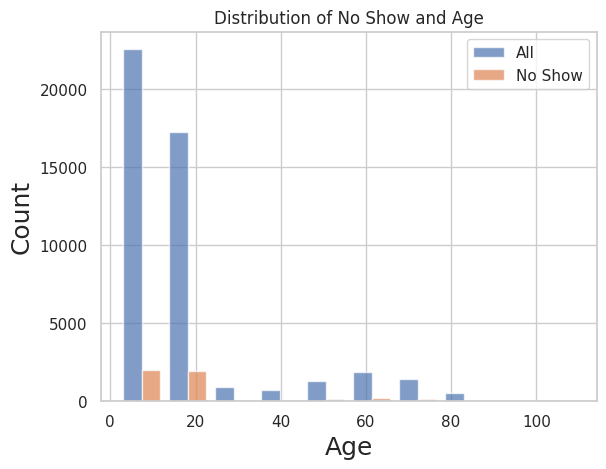

In [ ]:
# Filter DataFrame for no_show == 1 (yes)
no_show_yes = df[df['no_show'] == 1]

# Create histogram
plt.hist([df.age, no_show_yes.age], bins=10, label=['All', 'No Show'], alpha=0.7)
plt.title('Distribution of No Show and Age')
plt.xlabel('Age', fontsize=18)
plt.ylabel('Count', fontsize=18)
plt.legend()
plt.show()

In [ ]:
df.scheduleddayofweek.value_counts(normalize=True)

Monday       0.431372
Thursday     0.140962
Sunday       0.135799
Saturday     0.092497
Tuesday      0.072613
Friday       0.064664
Wednesday    0.062093
Name: scheduleddayofweek, dtype: float64

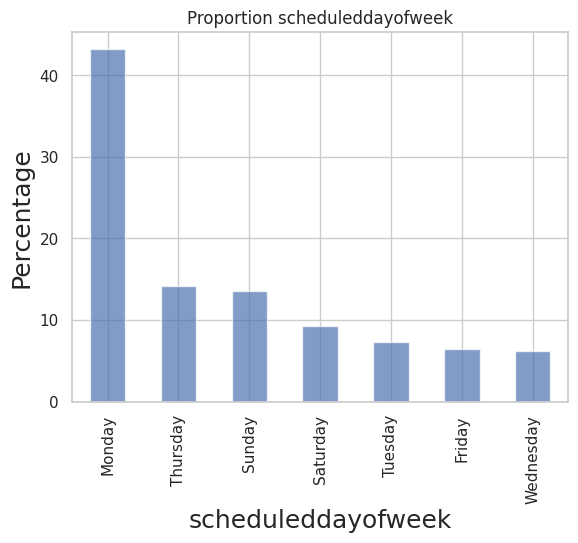

In [ ]:
# Count the occurrences of each day of the week and calculate the percentage
(df.scheduleddayofweek.value_counts(normalize=True) * 100).plot(kind='bar', alpha=0.7)

# Set title and labels for the plot
plt.title('Proportion scheduleddayofweek')  # Set the title of the plot
plt.xlabel('scheduleddayofweek', fontsize=18)  # Set the x-axis label with a font size of 18
plt.ylabel('Percentage', fontsize=18)  # Set the y-axis label with a font size of 18
plt.show()


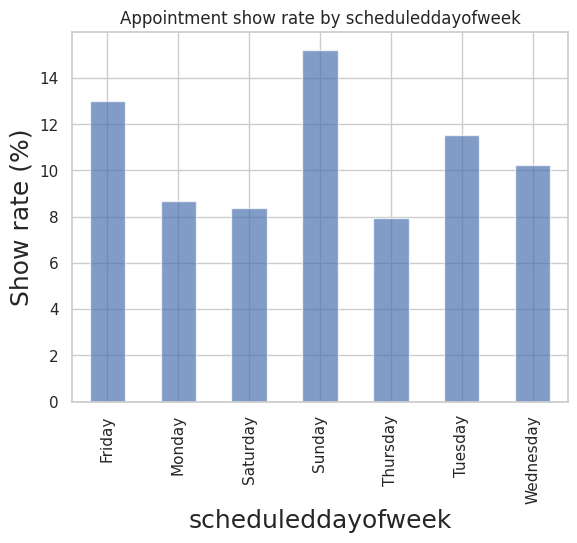

In [ ]:
# Calculate the mean show rate for each day of the week and plot as percentages
(df.groupby('scheduleddayofweek')['no_show'].mean() * 100).plot(kind='bar', alpha=0.7)

# Set title and labels for the plot
plt.title('Appointment show rate by scheduleddayofweek')
plt.xlabel('scheduleddayofweek', fontsize=18)
plt.ylabel('Show rate (%)', fontsize=18)
plt.show()


In [ ]:
# Define a mapping of hour to time
hour_to_time = {
    7: '7:00 AM', 8: '8:00 AM', 9: '9:00 AM', 10: '10:00 AM', 11: '11:00 AM',
    12: '12:00 PM', 13: '1:00 PM', 14: '2:00 PM', 15: '3:00 PM', 16: '4:00 PM',
    17: '5:00 PM', 18: '6:00 PM'
}

# Calculate the normalized counts (proportions) for each scheduled hour
scheduled_hour_proportions = df['scheduledhour'].value_counts(normalize=True) * 100

# Display the breakdown for all scheduled hours with time
for hour, proportion in scheduled_hour_proportions.items():
    time = hour_to_time.get(hour, f'{hour}:00')
    print(f"{hour} ({time}): {proportion:.2f}% of appointments are scheduled at this time.")


14 (2:00 PM): 14.70% of appointments are scheduled at this time.
13 (1:00 PM): 13.78% of appointments are scheduled at this time.
8 (8:00 AM): 12.08% of appointments are scheduled at this time.
9 (9:00 AM): 10.53% of appointments are scheduled at this time.
15 (3:00 PM): 9.95% of appointments are scheduled at this time.
16 (4:00 PM): 8.06% of appointments are scheduled at this time.
10 (10:00 AM): 7.94% of appointments are scheduled at this time.
7 (7:00 AM): 6.96% of appointments are scheduled at this time.
17 (5:00 PM): 6.76% of appointments are scheduled at this time.
11 (11:00 AM): 6.13% of appointments are scheduled at this time.
18 (6:00 PM): 2.88% of appointments are scheduled at this time.
12 (12:00 PM): 0.22% of appointments are scheduled at this time.


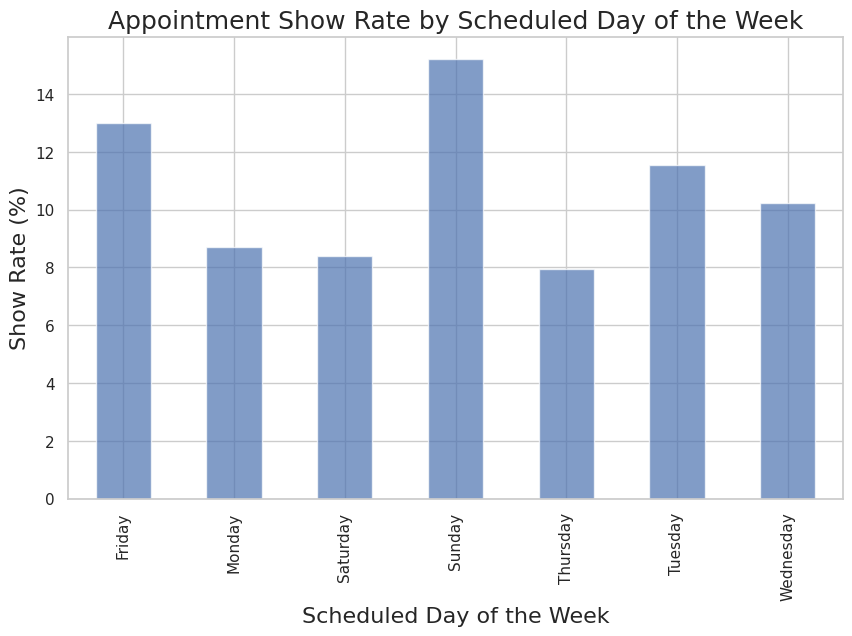

In [ ]:
# Define a mapping of day of the week to name
day_to_name = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}

# Calculate the mean show rate for each day of the week
day_of_week_show_rate = df.groupby('scheduleddayofweek')['no_show'].mean() * 100

# Display the breakdown for all scheduled days of the week
for day, show_rate in day_of_week_show_rate.items():
    day_name = day_to_name.get(day)
    if day_name is not None:
        print(f"{day} ({day_name}): {show_rate:.2f}% show rate")

# Create a bar plot
day_of_week_show_rate.plot(kind='bar', alpha=0.7, figsize=(10, 6))

# Set title and labels for the plot
plt.title('Appointment Show Rate by Scheduled Day of the Week', fontsize=18)
plt.xlabel('Scheduled Day of the Week', fontsize=16)
plt.ylabel('Show Rate (%)', fontsize=16)

# Show the plot
plt.show()


14 (2:00 PM): 14.70% of appointments are scheduled at this time.
13 (1:00 PM): 13.78% of appointments are scheduled at this time.
8 (8:00 AM): 12.08% of appointments are scheduled at this time.
9 (9:00 AM): 10.53% of appointments are scheduled at this time.
15 (3:00 PM): 9.95% of appointments are scheduled at this time.
16 (4:00 PM): 8.06% of appointments are scheduled at this time.
10 (10:00 AM): 7.94% of appointments are scheduled at this time.
7 (7:00 AM): 6.96% of appointments are scheduled at this time.
17 (5:00 PM): 6.76% of appointments are scheduled at this time.
11 (11:00 AM): 6.13% of appointments are scheduled at this time.
18 (6:00 PM): 2.88% of appointments are scheduled at this time.
12 (12:00 PM): 0.22% of appointments are scheduled at this time.


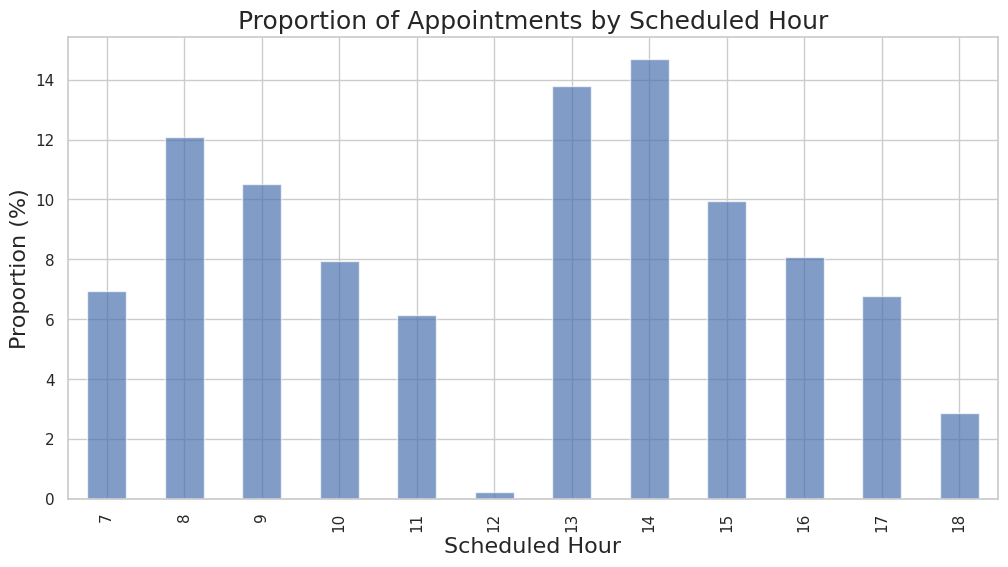

In [ ]:
# Define a mapping of hour to time
hour_to_time = {
    7: '7:00 AM', 8: '8:00 AM', 9: '9:00 AM', 10: '10:00 AM', 11: '11:00 AM',
    12: '12:00 PM', 13: '1:00 PM', 14: '2:00 PM', 15: '3:00 PM', 16: '4:00 PM',
    17: '5:00 PM', 18: '6:00 PM'
}

# Calculate the normalized counts (proportions) for each scheduled hour
scheduled_hour_proportions = df['scheduledhour'].value_counts(normalize=True) * 100

# Display the breakdown for all scheduled hours with time
for hour, proportion in scheduled_hour_proportions.items():
    time = hour_to_time.get(hour, f'{hour}:00')
    print(f"{hour} ({time}): {proportion:.2f}% of appointments are scheduled at this time.")

# Create a bar plot
plt.figure(figsize=(12, 6))
scheduled_hour_proportions.sort_index().plot(kind='bar', alpha=0.7)

# Set title and labels for the plot
plt.title('Proportion of Appointments by Scheduled Hour', fontsize=18)
plt.xlabel('Scheduled Hour', fontsize=16)
plt.ylabel('Proportion (%)', fontsize=16)

# Show the plot
plt.show()


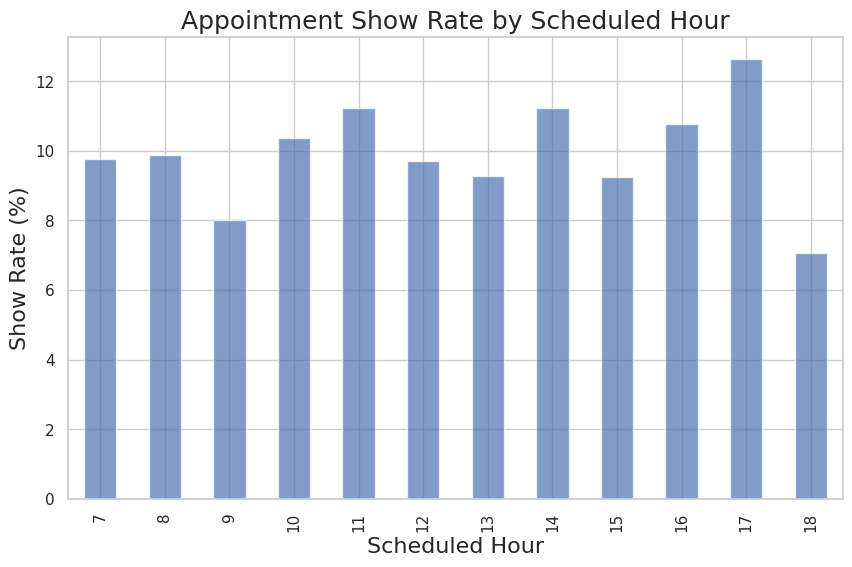

In [ ]:
# Calculate the mean show rate for each scheduled hour and plot as percentages
(df.groupby('scheduledhour')['no_show'].mean() * 100).plot(kind='bar', alpha=0.7, figsize=(10, 6))

# Set title and labels for the plot
plt.title('Appointment Show Rate by Scheduled Hour', fontsize=18)
plt.xlabel('Scheduled Hour', fontsize=16)
plt.ylabel('Show Rate (%)', fontsize=16)

# Show the plot
plt.show()


# ***Machine Leaning***

In [ ]:
# Encode the target variable 'no_show' to numerical values (0 and 1)
le = LabelEncoder()
df['no_show_encoded'] = le.fit_transform(df['no_show'])



In [ ]:
df

,specialty,gender,appointment_date,no_show,entry_service_date,appointment_year,appointment_shift,age,patient_needs_companion,average_temp_day,...,scheduling_date,scheduledhour,scheduleddayofweek,scheduledmonth,scheduledyear,appointmentdayofweek,appointmentmonth,appointmentyear,LeadDays,no_show_encoded
0,physiotherapy,0,2014-01-12 23:59:59,1,2014-01-12,2021,1,22.756153,0,20.75,...,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0,1
1,psychotherapy,0,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0,0
2,speech therapy,1,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0,0
3,physiotherapy,1,2014-01-12 23:59:59,0,2014-01-12,2021,1,22.756153,0,20.75,...,2014-01-12,13,Sunday,1,2014,Sunday,1,2014,0,0
4,physiotherapy,0,2020-05-02 23:59:59,0,2020-05-02,2021,1,68.000000,1,20.75,...,2020-05-02,14,Saturday,5,2020,Saturday,5,2020,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49587,psychotherapy,0,2020-11-02 23:59:59,0,2020-11-02,2022,0,6.000000,1,22.55,...,2020-11-02,10,Monday,11,2020,Monday,11,2020,0,0
49589,General Medicine,0,2014-01-12 23:59:59,1,2014-01-12,2022,0,22.756153,0,22.55,...,2014-01-12,10,Sunday,1,2014,Sunday,1,2014,0,1
49590,physiotherapy,0,2020-11-02 23:59:59,0,2020-11-02,2022,0,6.000000,1,22.55,...,2020-11-02,11,Monday,11,2020,Monday,11,2020,0,0
49591,psychotherapy,0,2014-01-12 23:59:59,1,2014-01-12,2022,0,22.756153,0,22.55,...,2014-01-12,11,Sunday,1,2014,Sunday,1,2014,0,1


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd


# Define features and target variable
features = ['specialty', 'gender', 'appointment_year',
            'appointment_shift', 'age',
            'patient_needs_companion', 'average_temp_day', 'average_rain_day',
            'max_temp_day', 'max_rain_day', 'rainy_day_before', 'storm_day_before',
            'rain_intensity', 'heat_intensity', 'scheduledhour', 'scheduleddayofweek',
            'scheduledmonth', 'scheduledyear', 'appointmentdayofweek', 'appointmentmonth',
            'appointmentyear']
target = 'no_show_encoded'

# Features and target variable
X = df[features]  # Use all columns listed in 'features'
y = df[target]  # Use the target variable 'no_show_encoded'


# Encode categorical features
label_encoders = {}
for feature in features:
    if df[feature].dtype == 'object':  # Check if the feature is categorical
        label_encoders[feature] = LabelEncoder()
        df[feature] = label_encoders[feature].fit_transform(df[feature])

# Split the data into features (X) and target variable (y)
X = df[features]
y = df[target]

# Initialize StratifiedKFold with the desired number of folds
num_folds = 5
stratified_kfold = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42)

# Perform cross-validation
fold_index = 1
for train_index, test_index in stratified_kfold.split(X, y):
    train_data, test_data = X.iloc[train_index], X.iloc[test_index]
    train_labels, test_labels = y.iloc[train_index], y.iloc[test_index]

    # Process the fold
    print(f"Fold {fold_index}:")
    print("Training Data:")
    print(train_data)
    print(train_labels)
    print()
    print("Testing Data:")
    print(test_data)
    print(test_labels)
    print()

    fold_index += 1


Fold 1:
Training Data:
       specialty  gender  appointment_year  appointment_shift        age  \
0              5       0              2021                  1  22.756153   
1              6       0              2021                  1  22.756153   
4              5       0              2021                  1  68.000000   
5              3       0              2021                  1   5.000000   
6              6       0              2021                  1  11.000000   
...          ...     ...               ...                ...        ...   
49585          0       0              2022                  0  22.756153   
49586          0       0              2022                  0  13.000000   
49587          6       0              2022                  0   6.000000   
49589          0       0              2022                  0  22.756153   
49590          5       0              2022                  0   6.000000   

       patient_needs_companion  average_temp_day  average_rain_d

# ***Random Forest ***

In [ ]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize the model
model = RandomForestClassifier()

# Perform cross-validation
cv_scores = []
for fold_index, (train_index, test_index) in enumerate(stratified_kfold.split(X, y), 1):
    train_data, test_data = X.iloc[train_index], X.iloc[test_index]
    train_labels, test_labels = y.iloc[train_index], y.iloc[test_index]

    # Train the model
    model.fit(train_data, train_labels)

    # Evaluate the model on the training data
    train_predictions = model.predict(train_data)
    train_accuracy = accuracy_score(train_labels, train_predictions)
    print(f"Training Accuracy (Fold {fold_index}): {train_accuracy}")

    # Evaluate the model on the testing data
    test_predictions = model.predict(test_data)
    test_accuracy = accuracy_score(test_labels, test_predictions)
    print(f"Testing Accuracy (Fold {fold_index}): {test_accuracy}")

    cv_scores.append(test_accuracy)

print(f"Mean Testing Accuracy: {sum(cv_scores) / len(cv_scores)}")  # Print the mean testing accuracy across all folds


Training Accuracy (Fold 1): 0.991750810188285
Testing Accuracy (Fold 1): 0.901981788966256
Training Accuracy (Fold 2): 0.9911883654283954
Testing Accuracy (Fold 2): 0.9017675415104446
Training Accuracy (Fold 3): 0.9914028603567411
Testing Accuracy (Fold 3): 0.9044353974716092
Training Accuracy (Fold 4): 0.9909743424929027
Testing Accuracy (Fold 4): 0.9005785301049924
Training Accuracy (Fold 5): 0.991429642723231
Testing Accuracy (Fold 5): 0.9028283694021856
Mean Testing Accuracy: 0.9023183254910976


# ***Printing the importance of each column
***

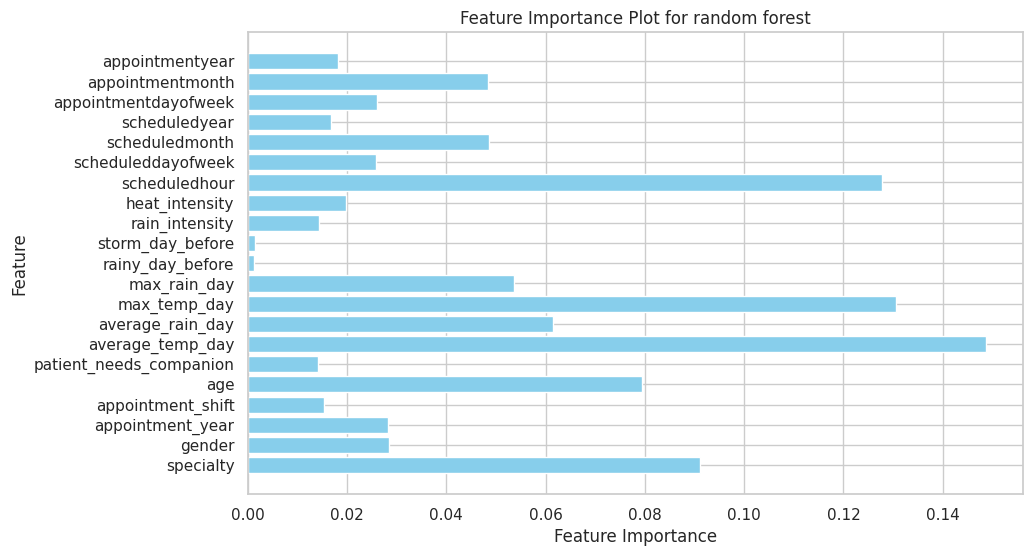

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt


# Get feature importances
feature_importances = model.feature_importances_
feature_names = X.columns

# Plot feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_names, feature_importances, color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Feature Importance Plot for random forest')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# X_train: Features for training
# y_train: Target variable for training
# X_test: Features for testing
# y_test: Target variable for testing


In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Initialize the RandomOverSampler
ros = RandomOverSampler(random_state=42)

# Resample the data
X_train_balanced, y_train_balanced = ros.fit_resample(X_train, y_train)


In [ ]:
y_train_balanced.value_counts()

1    29377
0    29377
Name: no_show_encoded, dtype: int64

# ***GaussianNB***

In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

# Concatenate the training and testing data
all_data_imputed = np.concatenate([X_train, X_test])
all_labels = np.concatenate([y_train, y_test])

# Initialize the Gaussian Naive Bayes model
model = GaussianNB()

# Perform cross-validation
cv_scores = cross_val_score(model, all_data_imputed, all_labels, cv=5)

# Print the cross-validation scores
print("Cross-Validation Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())
print("Standard Deviation of CV Scores:", cv_scores.std())

# Fit the model on the entire data
model.fit(all_data_imputed, all_labels)

# Evaluate the model on the training data
train_predictions = model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("\nTraining Accuracy:", train_accuracy)

# Evaluate the model on the testing data
test_predictions = model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

# Perform permutation importance
perm_importance = permutation_importance(model, all_data_imputed, all_labels, n_repeats=10, random_state=42)

# Get importance scores
importance_scores = perm_importance.importances_mean






Cross-Validation Scores: [0.88066417 0.86459561 0.87122348 0.87604457 0.87700879]
Mean CV Score: 0.8739073224817862
Standard Deviation of CV Scores: 0.005545319753793537

Training Accuracy: 0.8722681359044996
Testing Accuracy: 0.8769461505499214


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but GaussianNB was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/base.py:432: UserWarning: X has feature names, but GaussianNB was fitted without feature names
  warnings.warn(


# ****Printing the importance of each column


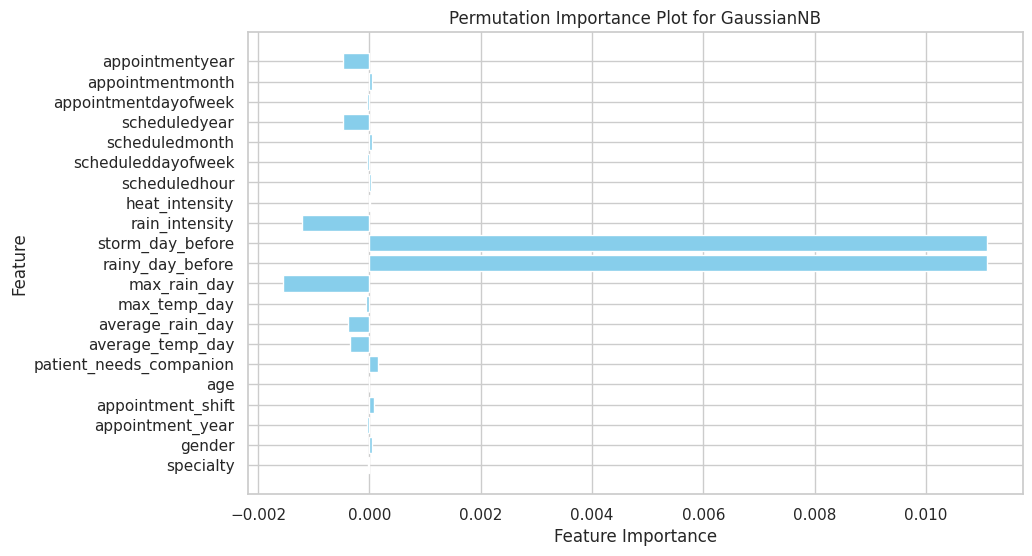

In [ ]:
import matplotlib.pyplot as plt

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importance_scores, color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Permutation Importance Plot for GaussianNB')
plt.show()


# ***KNeighbors***

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

# Define the parameter grid for KNN
param_grid = {
    'n_neighbors': range(1, 6),
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

# Create KNN classifier
knn = KNeighborsClassifier()

# Create GridSearchCV for KNN
grid_search = GridSearchCV(estimator=knn, param_grid=param_grid, cv=5, scoring='accuracy')

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and best score for KNN
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best Score:", best_score)

# Create KNN classifier with the best parameters
knn_best = KNeighborsClassifier(**best_params)

# Fit the KNN model with the best parameters to the training data
knn_best.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions = knn_best.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training Accuracy:", train_accuracy)

# Evaluate the model on the testing data
test_predictions = knn_best.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

# Perform permutation importance
results = permutation_importance(knn_best, X_test, y_test, scoring='accuracy')



Best Parameters: {'n_neighbors': 4, 'p': 1, 'weights': 'uniform'}
Best Score: 0.8964493419038874
Training Accuracy: 0.9117539026629936
Testing Accuracy: 0.8993715183545208


# **Printing the importance of each column**

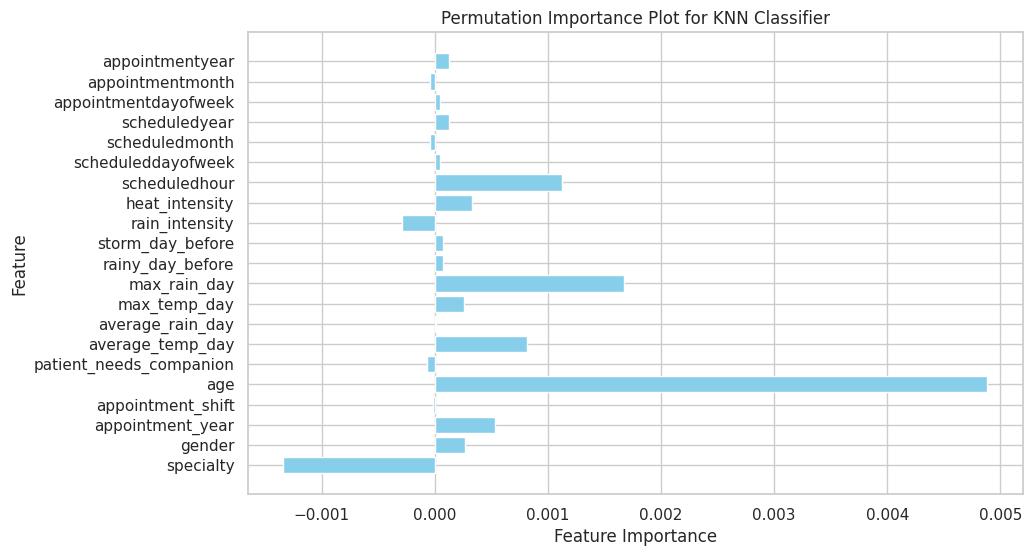

In [ ]:
import matplotlib.pyplot as plt

# Extract feature names
feature_names = X.columns

# Get importance scores
importance_scores = results.importances_mean

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importance_scores, color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Permutation Importance Plot for KNN Classifier')
plt.show()


# ***DecisionTree***

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score

# Define the parameter grid for Decision Tree
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10]
}

# Create Decision Tree classifier
dt = DecisionTreeClassifier()

# Create GridSearchCV for Decision Tree
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, scoring='accuracy')

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and best score for Decision Tree
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best Score:", best_score)

# Create Decision Tree classifier with the best parameters
dt_best = DecisionTreeClassifier(**best_params)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Fit the Decision Tree model with the best parameters and selected features to the training data
dt_best.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions = dt_best.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("\nTraining Accuracy:", train_accuracy)

# Evaluate the model on the testing data
test_predictions = dt_best.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

# Perform cross-validation with the best model and selected features
cv_scores = cross_val_score(dt_best, X_train, y_train, cv=5)
print("\nCross-Validation Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())
print("Standard Deviation of CV Scores:", cv_scores.std())


Best Parameters: {'criterion': 'entropy', 'max_depth': 5}
Best Score: 0.8991123354759718

Training Accuracy: 0.8998316498316499
Testing Accuracy: 0.8977655341291705

Cross-Validation Scores: [0.8986228  0.89955998 0.89917735 0.89898603 0.89917735]
Mean CV Score: 0.8991047016338125
Standard Deviation of CV Scores: 0.0003046774301519861


# ***print the important feature***

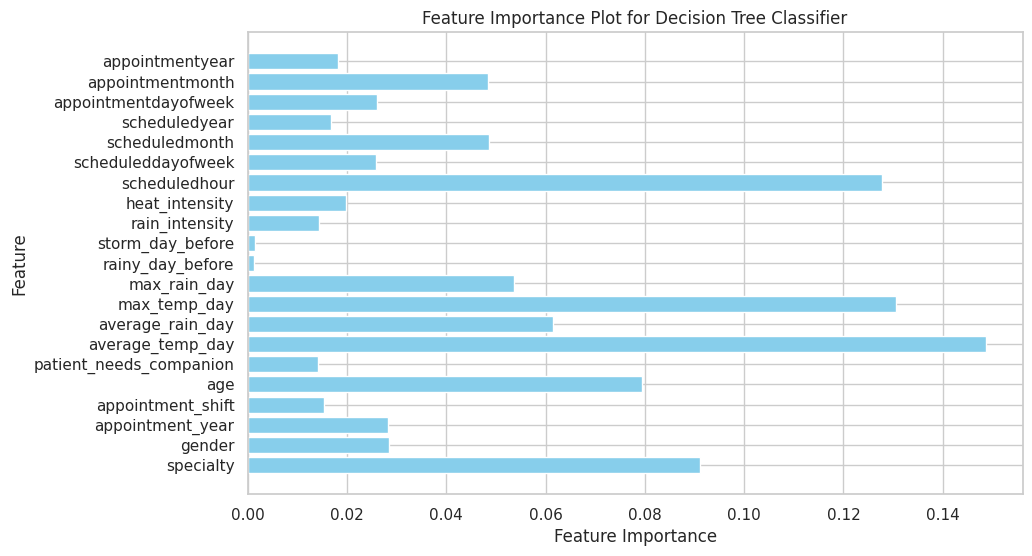

In [ ]:
import matplotlib.pyplot as plt

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_names, feature_importances, color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Feature Importance Plot for Decision Tree Classifier')
plt.show()




# ***LogisticRegression***

In [ ]:
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# parameter grid for logistic regression
param_grid = {
    'penalty': ['l1', 'l2'],  # Regularization type
    'C': [0.001, 0.01, 0.1, 1, 10, 100],  # Inverse of regularization strength
}

# Create a logistic regression model
logreg = LogisticRegression(solver='liblinear')

# Perform GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(estimator=logreg, param_grid=param_grid, cv=5)

# Fit the grid search to our data
grid_search.fit(X_train, y_train)

# Get the best parameters
best_params = grid_search.best_params_
print("Best Parameters:", best_params)

# Create a logistic regression model with the best parameters
best_logreg = LogisticRegression(solver='liblinear', **best_params)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# Fit the model to the training data
best_logreg.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions = best_logreg.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training Accuracy:", train_accuracy)

# Evaluate the model on the testing data
test_predictions = best_logreg.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

# Perform cross-validation with the best model and all data
cv_scores = cross_val_score(best_logreg, X_train, y_train, cv=5)
print("Cross-Validation Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())
print("Standard Deviation of CV Scores:", cv_scores.std())


/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Best Parameters: {'C': 0.001, 'penalty': 'l1'}
Training Accuracy: 0.8991295198010331
Testing Accuracy: 0.9001530221882172
Cross-Validation Scores: [0.89909134 0.89909134 0.89909134 0.89930639 0.89906721]
Mean CV Score: 0.8991295252795233
Standard Deviation of CV Scores: 8.892303730063085e-05


# ***print the feature importance***

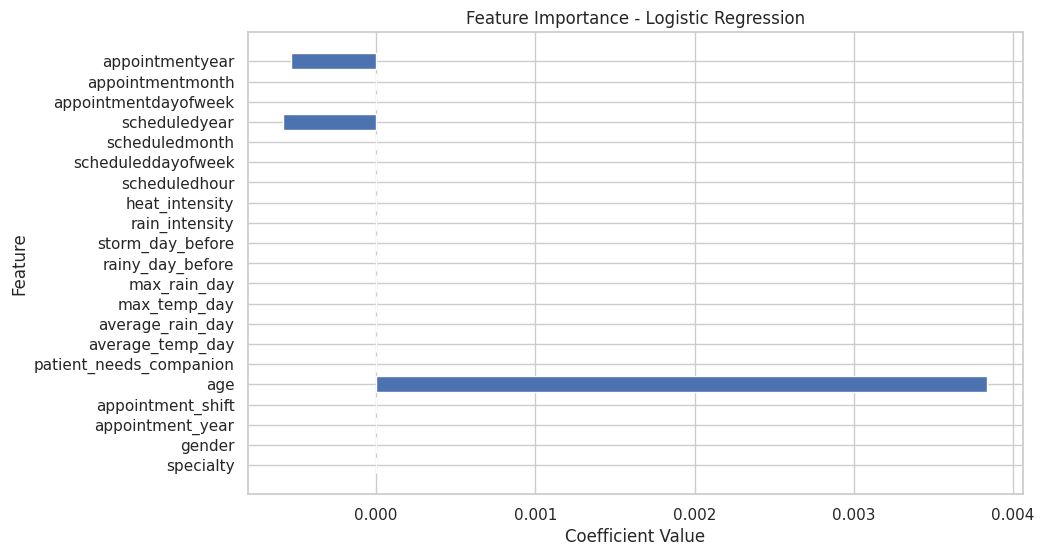

In [ ]:
import matplotlib.pyplot as plt

# Get the coefficients (feature importances)
coefficients = best_logreg.coef_[0]

# Get feature names
feature_names = X_train.columns

# Create a bar plot for feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_names, coefficients)
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.title('Feature Importance - Logistic Regression')
plt.show()




# ***RandomForest & logistic regression***

Model: Logistic Regression


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Best Parameters: {'C': 0.001, 'penalty': 'l2'}
Test Accuracy: 0.9001530221882172

Model: Random forest
Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Feature 0: 0.06123901857283391
Feature 1: 0.022395396961692984
Feature 2: 0.04449587502359661
Feature 3: 0.014268456975687823
Feature 4: 0.08100719349373206
Feature 5: 0.013422726102098598
Feature 6: 0.14862518629055813
Feature 7: 0.0694261446279475
Feature 8: 0.1338279446492688
Feature 9: 0.06311710404553841
Feature 10: 0.001761674784673529
Feature 11: 0.0017081484404390557
Feature 12: 0.017080163189760172
Feature 13: 0.023098578056093687
Feature 14: 0.09301500815987426
Feature 15: 0.029261485489863234
Feature 16: 0.05281353544148963
Feature 17: 0.023609491445424204
Feature 18: 0.029517562379341396
Feature 19: 0.05231781625979862
Feature 20: 0.02399148961028742
Test Accuracy: 0.9011094108645754



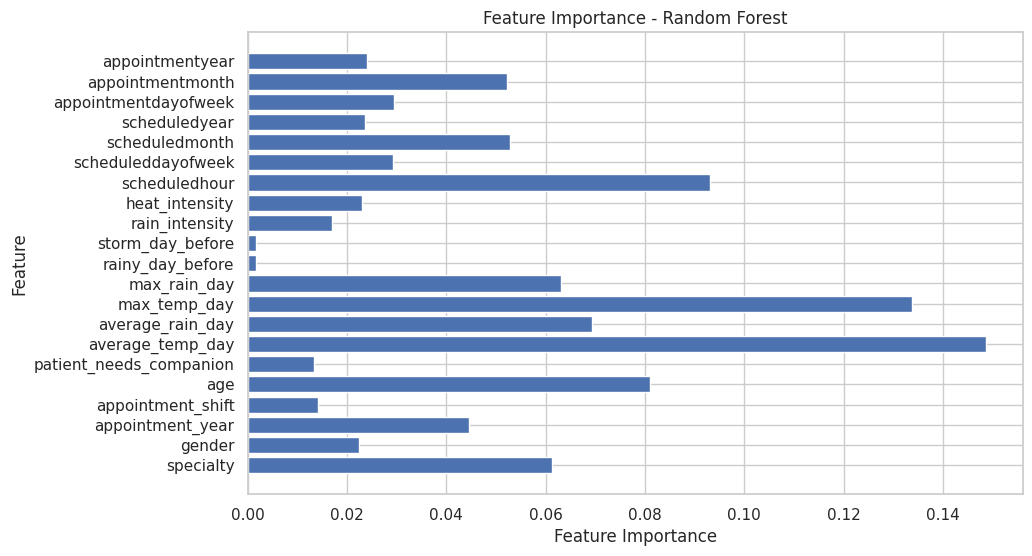

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Define Models with hyperparameter grids for tuning
Models = [
    ('Logistic Regression', LogisticRegression(random_state=42), {
        'C': [0.001, 0.01, 0.1, 1, 10],
        'penalty': ['l1', 'l2']
    }),
    ('Random forest', RandomForestClassifier(random_state=42), {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'criterion': ['gini', 'entropy']
    })
]

# Iterate through Models
for clf_name, clf, param_grid in Models:
    print(f"Model: {clf_name}")
    grid_search = GridSearchCV(clf, param_grid, cv=5, scoring='accuracy')
    grid_search.fit(X_train, y_train)

    # Get the best parameters and model
    best_params = grid_search.best_params_
    best_model = grid_search.best_estimator_

    # Fit the best model on the entire training data
    best_model.fit(X_train, y_train)

    # Print the best parameters
    print("Best Parameters:", best_params)

    # Print the feature importance
    if clf_name == 'Random forest':
        importance = best_model.feature_importances_
        for i, imp in enumerate(importance):
            print(f'Feature {i}: {imp}')

    # Predict on test data
    y_test_predict = best_model.predict(X_test)

    # Calculate test accuracy
    test_accuracy = accuracy_score(y_test, y_test_predict)
    print(f"Test Accuracy: {test_accuracy}\n")

    # Plot feature importance
    if clf_name == 'Random forest':
        feature_importances = best_model.feature_importances_
        plt.figure(figsize=(10, 6))
        plt.barh(X_train.columns, feature_importances)
        plt.xlabel('Feature Importance')
        plt.ylabel('Feature')
        plt.title('Feature Importance - Random Forest')
        plt.show()


# ***Multinomial Naive Bayes***

In [ ]:
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB

# Define the parameter grid for Multinomial Naive Bayes
param_grid = {
    'alpha': [0.1, 0.5, 1.0],  # Smoothing parameter
    'fit_prior': [True, False]  # Whether to learn class prior probabilities
}

# Create Multinomial Naive Bayes classifier
nb = MultinomialNB()

# Create GridSearchCV for Multinomial Naive Bayes
grid_search = GridSearchCV(estimator=nb, param_grid=param_grid, cv=5, scoring='accuracy')

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and best score for Multinomial Naive Bayes
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best Parameters:", best_params)
print("Best Score:", best_score)

# Create Multinomial Naive Bayes classifier with the best parameters
nb_best = MultinomialNB(**best_params)

# Fit the Multinomial Naive Bayes model with the best parameters to the training data
nb_best.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions = nb_best.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training Accuracy:", train_accuracy)

# Evaluate the model on the testing data
test_predictions = nb_best.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
print("Testing Accuracy:", test_accuracy)

# Perform cross-validation with the best model and selected features
cv_scores = cross_val_score(nb_best, X_train, y_train, cv=5)
print("Cross-Validation Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())
print("Standard Deviation of CV Scores:", cv_scores.std())

# Plot feature importance (if applicable)
# Multinomial Naive Bayes does not have a built-in feature importance attribute


Best Parameters: {'alpha': 0.1, 'fit_prior': True}
Best Score: 0.8015595590766044
Training Accuracy: 0.8017026975320451
Testing Accuracy: 0.8027926549349655
Cross-Validation Scores: [0.79674797 0.80846485 0.79220469 0.80650562 0.80387467]
Mean CV Score: 0.8015595590766044
Standard Deviation of CV Scores: 0.006134677705841148


# ***print the feature important and SVC***

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Define hyperparameters for the SVM model
svm_params = {
    'kernel': 'linear',  # Use linear kernel
    'C': 1.0,  # Regularization parameter
}

# Create the SVM model with specified hyperparameters
svm_model = SVC(**svm_params)

# Train the SVM model on the training data
svm_model.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions_svm = svm_model.predict(X_train)
train_accuracy_svm = accuracy_score(y_train, train_predictions_svm)
print("Training Accuracy (SVM):", train_accuracy_svm)

# Evaluate the model on the testing data
test_predictions_svm = svm_model.predict(X_test)
test_accuracy_svm = accuracy_score(y_test, test_predictions_svm)
print("Testing Accuracy (SVM):", test_accuracy_svm)


Training Accuracy (SVM): 0.8982686053185384
Testing Accuracy (SVM): 0.8986228003060444


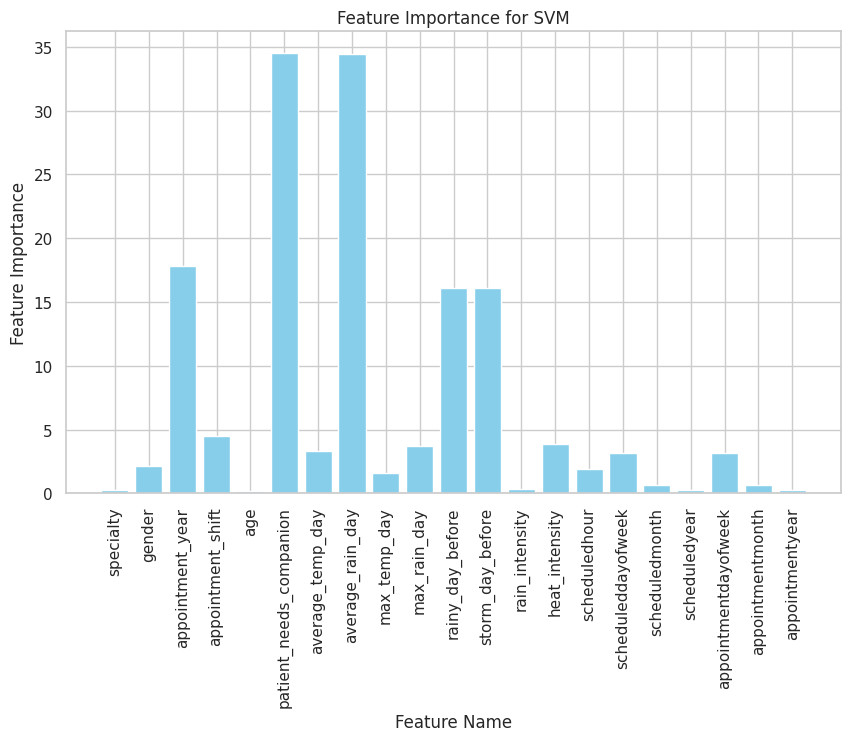

In [ ]:
# Get the feature importances from the SVM model
feature_importances = np.abs(svm_model.coef_[0])

# Plot the feature importances with corresponding names
plt.figure(figsize=(10, 6))
plt.bar(feature_names, feature_importances, color='skyblue')
plt.xlabel('Feature Name')
plt.ylabel('Feature Importance')
plt.title('Feature Importance for SVM')

# Set the x-axis labels to feature names
plt.xticks(range(len(feature_names)), feature_names, rotation=90)

plt.show()





# ***Neural Network***

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import numpy as np

# Scale the training data
scaler = StandardScaler()
train_data_scaled = scaler.fit_transform(X_train)

# Initialize StratifiedKFold for cross-validation
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize lists to store accuracies
train_accuracies_nn = []
test_accuracies_nn = []

# Define hyperparameters for the neural network
learning_rate = 0.001
epochs = 10
batch_size = 32

# Define and compile the neural network model
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(train_data_scaled.shape[1],)),
    Dense(1, activation='sigmoid')  # Output layer with one unit for binary classification
])
optimizer = Adam(learning_rate=learning_rate)
nn_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Iterate through each fold
for fold, (train_index, test_index) in enumerate(skf.split(train_data_scaled, y_train), 1):
    print(f"Fold {fold}:")

    # Get the training and testing data for this fold
    X_train_fold, X_test_fold = train_data_scaled[train_index], train_data_scaled[test_index]
    y_train_fold, y_test_fold = y_train.iloc[train_index], y_train.iloc[test_index]  # Use iloc to access by integer position

    # Fit the model on the training data for this fold
    nn_model.fit(X_train_fold, y_train_fold, epochs=epochs, batch_size=batch_size, verbose=0)

    # Evaluate the model on the training data for this fold
    train_predictions_nn_prob = nn_model.predict(X_train_fold)
    train_predictions_nn = np.round(train_predictions_nn_prob)
    train_accuracy_nn = accuracy_score(y_train_fold, train_predictions_nn)
    print("Training Accuracy (Neural Network):", train_accuracy_nn)
    train_accuracies_nn.append(train_accuracy_nn)

    # Evaluate the model on the testing data for this fold
    test_predictions_nn_prob = nn_model.predict(X_test_fold)
    test_predictions_nn = np.round(test_predictions_nn_prob)
    test_accuracy_nn = accuracy_score(y_test_fold, test_predictions_nn)
    print("Testing Accuracy (Neural Network):", test_accuracy_nn)
    test_accuracies_nn.append(test_accuracy_nn)
    print()  # Print a blank line between folds

# Calculate and print average accuracies across all folds
print("Average Training Accuracy (Neural Network):", np.mean(train_accuracies_nn))
print("Average Testing Accuracy (Neural Network):", np.mean(test_accuracies_nn))


Fold 1:
523/523 [==============================] - 1s 2ms/step
Training Accuracy (Neural Network): 0.8991988520865718
131/131 [==============================] - 0s 1ms/step
Testing Accuracy (Neural Network): 0.899091343854615

Fold 2:
523/523 [==============================] - 1s 1ms/step
Training Accuracy (Neural Network): 0.8992586392442903
131/131 [==============================] - 0s 1ms/step
Testing Accuracy (Neural Network): 0.8993304638928742

Fold 3:
523/523 [==============================] - 1s 2ms/step
Training Accuracy (Neural Network): 0.8995575750328829
131/131 [==============================] - 0s 1ms/step
Testing Accuracy (Neural Network): 0.8986131037780966

Fold 4:
523/523 [==============================] - 1s 1ms/step
Training Accuracy (Neural Network): 0.8992048783404077
131/131 [==============================] - 0s 1ms/step
Testing Accuracy (Neural Network): 0.8995455632623774

Fold 5:
523/523 [==============================] - 1s 1ms/step
Training Accuracy (Neural 

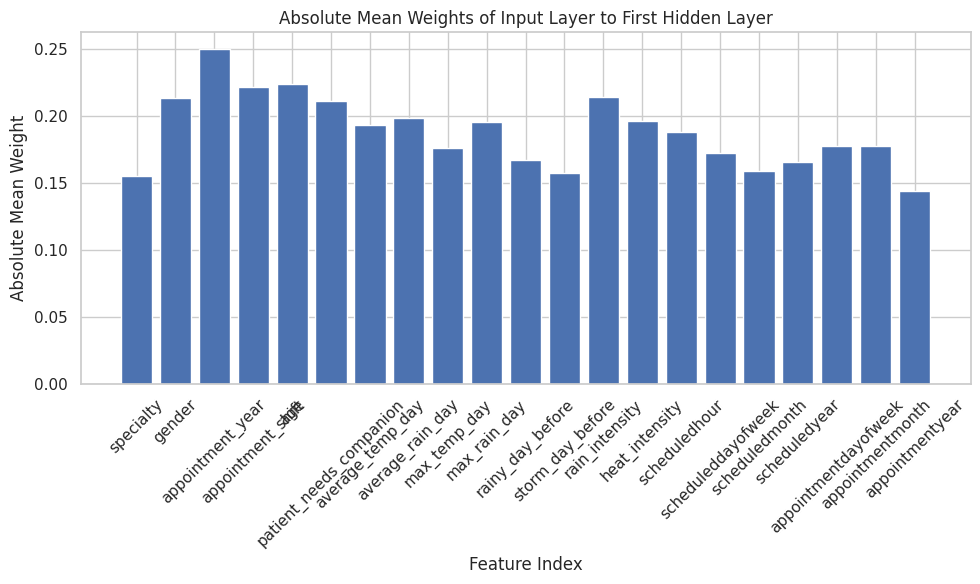

In [ ]:
# Get the weights of the connections between the input layer and the first hidden layer
weights = nn_model.layers[0].get_weights()[0]

# Calculate the absolute mean weights across all folds
abs_mean_weights = np.mean(np.abs(weights), axis=1)

# Get feature names
feature_names = X_train.columns

# Plot the absolute mean weights along with feature names
plt.figure(figsize=(10, 6))
plt.bar(range(len(abs_mean_weights)), abs_mean_weights)
plt.xlabel('Feature Index')
plt.ylabel('Absolute Mean Weight')
plt.xticks(range(len(feature_names)), feature_names, rotation=45)
plt.title('Absolute Mean Weights of Input Layer to First Hidden Layer')
plt.tight_layout()
plt.show()


# ***GridSearch***

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

# Initialize StratifiedKFold for cross-validation
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Define the parameter grid for Gradient Boosting
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

# Create Gradient Boosting classifier
gb = GradientBoostingClassifier()

# Create GridSearchCV for Gradient Boosting
grid_search_gb = GridSearchCV(estimator=gb, param_grid=param_grid, cv=skf, scoring='accuracy')

# Fit the grid search to the training data
grid_search_gb.fit(X_train, y_train)

# Get the best parameters and best score for Gradient Boosting
best_params_gb = grid_search_gb.best_params_
best_score_gb = grid_search_gb.best_score_

print("Best Parameters for Gradient Boosting:", best_params_gb)
print("Best Score for Gradient Boosting:", best_score_gb)

# Create Gradient Boosting classifier with the best parameters
gb_best = GradientBoostingClassifier(**best_params_gb)

# Fit the model to the entire training data
gb_best.fit(X_train, y_train)

# Evaluate the model on the training data
train_predictions_gb = gb_best.predict(X_train)
train_accuracy_gb = accuracy_score(y_train, train_predictions_gb)
print("Training Accuracy (Gradient Boosting):", train_accuracy_gb)

# Evaluate the model on the testing data
test_predictions_gb = gb_best.predict(X_test)
test_accuracy_gb = accuracy_score(y_test, test_predictions_gb)
print("Testing Accuracy (Gradient Boosting):", test_accuracy_gb)




Best Parameters for Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 50}
Best Score for Gradient Boosting: 0.8997035963859645
Training Accuracy (Gradient Boosting): 0.9122345513678974
Testing Accuracy (Gradient Boosting): 0.899770466717674


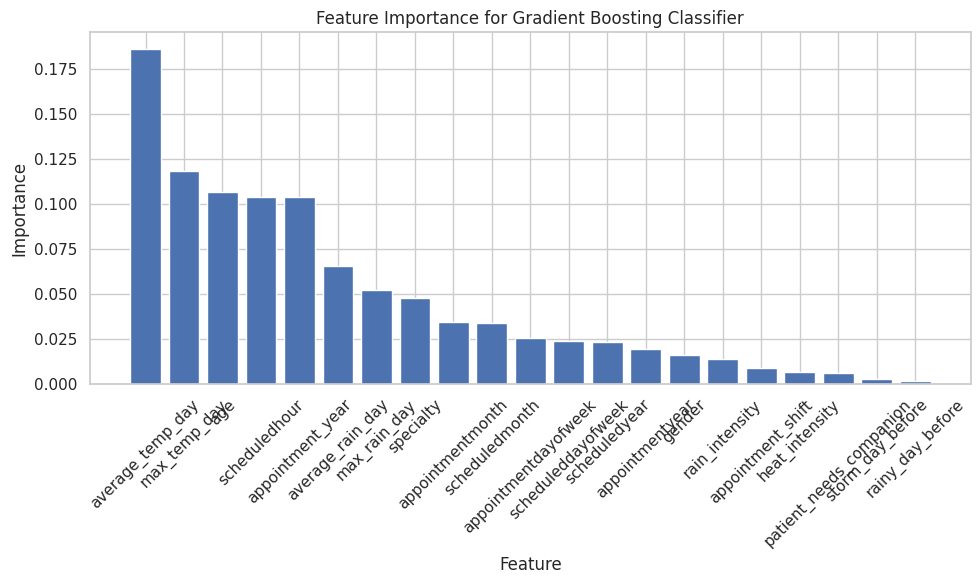

In [ ]:
import matplotlib.pyplot as plt

# Get feature importances and their corresponding names
feature_importances_gb = gb_best.feature_importances_
feature_names = X_train.columns

# Sort features by importance
sorted_indices = feature_importances_gb.argsort()[::-1]
sorted_importances = feature_importances_gb[sorted_indices]
sorted_names = [feature_names[i] for i in sorted_indices]

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(sorted_importances)), sorted_importances)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(range(len(sorted_names)), sorted_names, rotation=45)
plt.title('Feature Importance for Gradient Boosting Classifier')
plt.tight_layout()
plt.show()


# ***ENSEMBLE***

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Define models
models = [
    ('Logistic Regression', LogisticRegression(C=10, solver='liblinear', penalty='l2', random_state=42)),
    ('Random Forest', RandomForestClassifier(criterion='gini', max_depth=10, min_samples_leaf=1, min_samples_split=5, n_estimators=50)),
    ('Naive Bayes (Gaussian)', GaussianNB()),
    ('Naive Bayes (Multinomial)', MultinomialNB()),
    ('K-Nearest Neighbors', KNeighborsClassifier(n_neighbors=5, weights='uniform', p=1)),
    ('Decision Tree', DecisionTreeClassifier(criterion='entropy', max_depth=None)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5)),
    ('SVM', SVC(kernel='rbf', C=1)),
    ('Neural Network', MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42))
]

# Create ensemble model using hard voting
ensemble_model = VotingClassifier(estimators=models, voting='hard')

# Fit the ensemble model to the training data
ensemble_model.fit(X_train, y_train)

# Evaluate the ensemble model on the training data
train_predictions_ensemble = ensemble_model.predict(X_train)
train_accuracy_ensemble = accuracy_score(y_train, train_predictions_ensemble)
print("Training Accuracy (Ensemble):", train_accuracy_ensemble)

# Evaluate the ensemble model on the testing data
test_predictions_ensemble = ensemble_model.predict(X_test)
test_accuracy_ensemble = accuracy_score(y_test, test_predictions_ensemble)
print("Testing Accuracy (Ensemble):", test_accuracy_ensemble)

best_model_name = None
best_model_accuracy = 0

# Iterate through each base model in the ensemble
for model_name, model in models:
    # Train the base model
    model.fit(X_train, y_train)

    # Predict with the base model on the training data
    train_predictions_model = model.predict(X_train)

    # Calculate the training accuracy for the base model
    train_accuracy_model = accuracy_score(y_train, train_predictions_model)

    # Predict with the base model on the testing data
    test_predictions_model = model.predict(X_test)

    # Calculate the testing accuracy for the base model
    test_accuracy_model = accuracy_score(y_test, test_predictions_model)

    # Print the accuracy of the base model
    print(f"{model_name} Training Accuracy: {train_accuracy_model}")
    print(f"{model_name} Testing Accuracy: {test_accuracy_model}")

    # Check if this model is the best so far
    if test_accuracy_model > best_model_accuracy:
        best_model_accuracy = test_accuracy_model
        best_model_name = model_name

# Print the best model and its accuracy
print(f"\nBest Model: {best_model_name}")
print(f"Best Model Testing Accuracy: {best_model_accuracy}")


Training Accuracy (Ensemble): 0.9022383776544863
Testing Accuracy (Ensemble): 0.8999617444529456
Logistic Regression Training Accuracy: 0.8991295198010331
Logistic Regression Testing Accuracy: 0.9001530221882172
Random Forest Training Accuracy: 0.9010426630954659
Random Forest Testing Accuracy: 0.9001530221882172
Naive Bayes (Gaussian) Training Accuracy: 0.8741151712263249
Naive Bayes (Gaussian) Testing Accuracy: 0.8773909716908952
Naive Bayes (Multinomial) Training Accuracy: 0.8017026975320451
Naive Bayes (Multinomial) Testing Accuracy: 0.8027926549349655
K-Nearest Neighbors Training Accuracy: 0.9104648938205472
K-Nearest Neighbors Testing Accuracy: 0.8917368018362662
Decision Tree Training Accuracy: 0.9952649703462789
Decision Tree Testing Accuracy: 0.8448737566947208
Gradient Boosting Training Accuracy: 0.9146259804859384
Gradient Boosting Testing Accuracy: 0.899770466717674
SVM Training Accuracy: 0.8991295198010331
SVM Testing Accuracy: 0.9001530221882172
Neural Network Training Ac

In [ ]:
plt.style.use('dark_background')


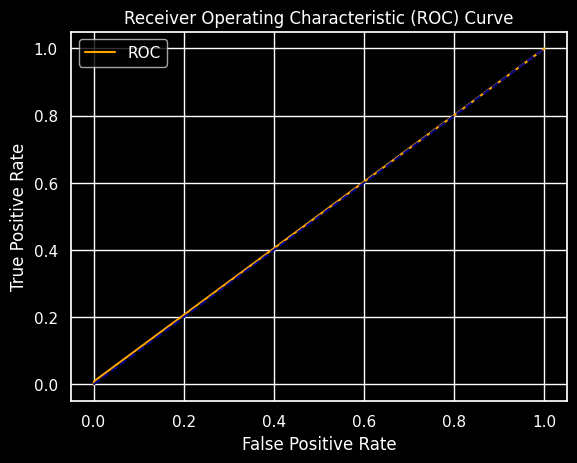

In [ ]:
fper, tper, thresholds = roc_curve(y_test, test_predictions_ensemble)
plt.plot(fper, tper, color='orange', label='ROC')
plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()